# Ok-k-mer

Use python310 conda environment

## Imports

In [2]:
import os
# from random import randint
import multiprocessing as mp
from random import sample
from random import sample, seed as set_seed, randint
import numpy as np
import pandas as pd
from collections import Counter
from ete3 import Tree
from itertools import combinations, product
from scipy.stats import binom, geom, spearmanr, pearsonr

pd.options.display.max_rows = 40



In [3]:
# import matplotlib
import matplotlib.pyplot as plt
import matplotlib.patches as mplpatches
from mpl_toolkits.axes_grid1.inset_locator import inset_axes
%matplotlib inline

plt.rcParams['figure.dpi'] = 300
plt.rcParams['agg.path.chunksize'] = 10000

In [4]:
import warnings
warnings.filterwarnings("ignore")


In [5]:
# import plotnine

from plotnine import \
    ggplot, aes, theme, themes, element_blank, element_line, element_text, mapping, \
    geom_point, geom_jitter, geom_line, geom_bar, geom_boxplot, geom_violin, geom_histogram, \
    ggtitle, xlab, ylab, geom_vline, geom_hline, geom_abline, geom_col, geom_tile, \
    scale_x_discrete, scale_y_discrete, scale_x_continuous, scale_y_continuous, \
    scale_color_discrete, scale_fill_manual, scale_fill_hue, scale_fill_gradient, scale_color_manual, scale_color_hue, \
    guides, after_stat, \
    xlim, ylim
from plotnine.options import figure_size
from mizani.formatters import percent_format

# plotnine theme
def theme_tufte_func(base_size=19, base_family="sans", rotate=True, figure_size=None):
    ''' Plotnine plotting theme. '''
    thm = themes.theme_bw(base_size=base_size, base_family = base_family) + \
        theme(
            legend_background = element_blank(),
            legend_key = element_blank(),
            panel_background = element_blank(),
            panel_border = element_blank(),
            strip_background = element_blank(),
            plot_background = element_blank(),
            panel_grid = element_blank(),
            axis_line = element_line(colour = "black", size = 1),
            axis_text_y = element_text(colour = "black")
        )

    if rotate:
        thm += theme(axis_text_x=element_text(rotation=45, hjust=1))
    if figure_size is not None:
        thm += theme(figure_size=figure_size)
    return thm


## Helper functions

In [6]:
def yield_file_lines(path):
    ''' Read file from path line-by-line. '''
    with open(path, 'r') as in_file:
        for line in in_file:
            yield line.strip()

In [7]:
def calc_corr(l1, l2, pearson=False, prnt=False):
    if pearson:
        corr, pval = pearsonr(l1, l2)
    else:
        corr, pval = spearmanr(l1, l2)
    if prnt:
        print("Correlation coefficient:", corr)
        print("p-value:", pval)
    return corr, pval

In [8]:
def dist_tree_calc(filename1):
    ''' Calculate tree distance. '''
    tree1= Tree(filename1,format=1)
    # print('Tree from', filename1, 'len:', len(tree1))
    dist_tree={}
    samples = [i.name for i in tree1.get_leaves()]
    num_sample = len(samples)
    for i in range(num_sample):
        tax_i = samples[i]
        for j in range(i+1,num_sample):
            tax_j = samples[j]
            dist_tree[(min(tax_i, tax_j)+".fa", max(tax_i, tax_j)+".fa")] = tree1.get_distance(tax_i, tax_j, topology_only=False)
    # print('num samples:', num_sample)
    # print('xxx:', num_sample * (num_sample-1)/2)
    # print('tree len:', len(dist_tree))
    return dist_tree


In [9]:
def make_tree_dict(tree_path):
    """
    Given a path to a Newick tree file, return a symmetric dictionary of distances between all pairs of taxa names
    (with or without '.fa' extension).

    Parameters:
        tree_path (str): Path to the Newick tree file.

    Returns:
        dict: A dictionary of dictionaries: { taxon_name: { other_taxon: distance, ... }, ... }
    """
    dist_tree = dist_tree_calc(tree_path)

    names = set()
    processed_pairs = []
    for (g1, g2), dist in dist_tree.items():
        g1_clean = g1.rstrip('.fa')
        g2_clean = g2.rstrip('.fa')
        names.add(g1_clean)
        names.add(g2_clean)
        processed_pairs.append((g1_clean, g2_clean, float(dist)))

    tree_dict = {name: {other: 0.0 for other in names} for name in names}
    for g1, g2, d in processed_pairs:
        tree_dict[g1][g2] = d
        tree_dict[g2][g1] = d  # Ensure symmetry

    return tree_dict


In [10]:

def get_random_samples(sample_names, sample_fraction=0.1, seed=None):
    '''
    # Example usage:
    cyano_random_samples = get_random_samples(cyano_sample_names, sample_fraction=0.1, seed=42)
    '''
    if seed is not None:
        set_seed(seed)
    num_samples = max(1, int(len(sample_names) * sample_fraction))
    random_samples = sample(sample_names, num_samples)
    return random_samples



In [11]:
def parse_dashing_dfs(dir_path):
    """
    Parses all distance_* files in the given directory into a dictionary of pandas DataFrames.
    Each DataFrame skips the first line, assumes tab-separation and adjusts indices and columns as expected.

    Args:
        dir_path (str): Path to the directory containing distance_* files.

    Returns:
        dict: Dictionary mapping filename to corresponding DataFrame.
    """

    # Get list of files in directory that start with 'distance_'
    files = [f for f in os.listdir(dir_path) if os.path.isfile(os.path.join(dir_path, f)) and f.startswith('distance_')]

    # Create a dictionary to store dataframes
    dashing_dfs = {}

    # Read each file into a dataframe, skipping first line
    for file in files:
        file_path = os.path.join(dir_path, file)
        try:
            # Skip first line and read tab-separated data
            df = pd.read_csv(file_path, sep='\t', header=None, skiprows=1)
            df.index = df.iloc[:, 0].str.replace('genomes_ncbi/', '')
            df = df.iloc[:, 1:]
            df.columns = df.index
            dashing_dfs[file] = df
            # print(f"Successfully read {file}")
        except Exception as e:
            print(f"Error reading {file}: {str(e)}")

    # Print summary of loaded dataframes
    print(f"\nLoaded {len(dashing_dfs)} files")
    for file, df in dashing_dfs.items():
        print(f"{file}: {df.shape}")
    return dashing_dfs

In [12]:
def build_merged_df(tree_dict, dashing_dfs):
    """
    Build merged dataframe for all genome pairs among `genomes`,
    including tree distances and distances for each k from `dashing_dfs`.

    Parameters:
    -----------
    tree_dict : dict
        Nested dictionary of tree-based distances; tree_dict[g1][g2] gives distance.
    dashing_dfs : dict
        Mapping from dashing file name to pairwise distance DataFrame.

    Returns:
    --------
    merged_df : pd.DataFrame
        DataFrame indexed by sorted genome pairs, with metadata and k-mer distances.
    """

    genomes = sorted(tree_dict.keys())

    # Create all pairs of genomes (upper triangle only, sorted lexicographically)
    pairs = []
    for i in range(len(genomes)):
        for j in range(i+1, len(genomes)):
            pair = '_'.join(sorted([genomes[i], genomes[j]]))
            pairs.append(pair)

    # Initialize dataframe with pairs as index
    merged_df = pd.DataFrame(index=pairs)

    # Add metadata columns to merged_df
    genome_pairs = []
    genomes_1s = []
    genomes_2s = []
    tree_distances = []
    for index in merged_df.index:
        # Split the genome pair
        genome1 = "_".join(index.split("_", 2)[:2])
        genome2 = "_".join(index.split("_", 2)[2:])

        # Get distance from tree_dict
        genome_pairs.append(index)
        genomes_1s.append(genome1)
        genomes_2s.append(genome2)
        tree_distances.append(tree_dict[genome1][genome2])

    merged_df['genome_pair'] = genome_pairs
    merged_df['genome_1'] = genomes_1s
    merged_df['genome_2'] = genomes_2s
    merged_df['tree_distance'] = tree_distances

    print(f"Final dataframe shape: {merged_df.shape}")

    # For each k, add a column to merged_df with the pairwise distances
    for fname, df in dashing_dfs.items():
        k_val = int(str(fname).replace('distance_k', '').replace('.txt', ''))
        # Build a dictionary mapping sorted genome pair -> distance
        pair_to_dist = {}
        for i in range(len(df)):
            g1 = df.iloc[i].name
            for g2, d in dict(df.iloc[i]).items():
                if g1 == g2: continue
                pair = '_'.join(sorted([g1, g2]))
                pair_to_dist[pair] = d

        # Map the distances to the merged_df for this k
        colname = f'k{k_val}_distance'
        merged_df[colname] = merged_df.index.map(pair_to_dist.get)
        print(f"Added column '{colname}' to merged_df.")

    return merged_df

In [13]:
def process_data(tree_path, dashing_dir_path):
    tree_dict = make_tree_dict(tree_path)
    dashing_dfs = parse_dashing_dfs(dashing_dir_path)
    merged_df = build_merged_df(tree_dict, dashing_dfs)
    return tree_dict, dashing_dfs, merged_df


## Process data

In [14]:
aquificota_dir_path = '/scratch4/blangme2/sjhwang/ok_k_mer/data/aquificota/dashingfull_genomes_ncbi'
bacillales_dir_path = '/scratch4/blangme2/sjhwang/ok_k_mer/data/bacillales/dashingfull_genomes_ncbi'
caldisericia_dir_path = '/scratch4/blangme2/sjhwang/ok_k_mer/data/caldisericia/dashingfull_genomes_ncbi'
chlamydia_dir_path = '/scratch4/blangme2/sjhwang/ok_k_mer/data/chlamydiales/dashingfull_genomes_ncbi'
cyano_dir_path = '/scratch4/blangme2/sjhwang/ok_k_mer/data/cyanobacteriales/dashingfull_genomes_ncbi'
neisseriaceae_dir_path = '/scratch4/blangme2/sjhwang/ok_k_mer/data/neisseriaceae/dashingfull_genomes_ncbi'

aquificota_tree_path = '/scratch4/blangme2/sjhwang/ok_k_mer/data/aquificota/p__Aquificota.nwk'
bacillales_tree_path = '/scratch4/blangme2/sjhwang/ok_k_mer/data/bacillales/o__Bacillales_A.nwk'
caldisericia_tree_path = '/scratch4/blangme2/sjhwang/ok_k_mer/data/caldisericia/c__Caldisericia.nwk'
chlamydia_tree_path = '/scratch4/blangme2/sjhwang/ok_k_mer/data/chlamydiales/o__Chlamydiales.nwk'
cyano_tree_path = '/scratch4/blangme2/sjhwang/ok_k_mer/data/cyanobacteriales/o__Cyanobacteriales.nwk'
neisseriaceae_tree_path = '/scratch4/blangme2/sjhwang/ok_k_mer/data/neisseriaceae/f__Neisseriaceae.nwk'

chlamydia_tree_dict, chlamydia_dashing_dfs, chlamydia_merged_df = process_data(chlamydia_tree_path, chlamydia_dir_path)
aquificota_tree_dict, aquificota_dashing_dfs, aquificota_merged_df = process_data(aquificota_tree_path, aquificota_dir_path)
bacillales_tree_dict, bacillales_dashing_dfs, bacillales_merged_df = process_data(bacillales_tree_path, bacillales_dir_path)
caldisericia_tree_dict, caldisericia_dashing_dfs, caldisericia_merged_df = process_data(caldisericia_tree_path, caldisericia_dir_path)
cyano_tree_dict, cyano_dashing_dfs, cyano_merged_df = process_data(cyano_tree_path, cyano_dir_path)
neisseriaceae_tree_dict, neisseriaceae_dashing_dfs, neisseriaceae_merged_df = process_data(neisseriaceae_tree_path, neisseriaceae_dir_path)


Loaded 60 files
distance_k42.txt: (288, 288)
distance_k10.txt: (288, 288)
distance_k54.txt: (288, 288)
distance_k58.txt: (288, 288)
distance_k39.txt: (288, 288)
distance_k57.txt: (288, 288)
distance_k26.txt: (288, 288)
distance_k34.txt: (288, 288)
distance_k11.txt: (288, 288)
distance_k22.txt: (288, 288)
distance_k7.txt: (288, 288)
distance_k45.txt: (288, 288)
distance_k61.txt: (288, 288)
distance_k14.txt: (288, 288)
distance_k52.txt: (288, 288)
distance_k59.txt: (288, 288)
distance_k18.txt: (288, 288)
distance_k38.txt: (288, 288)
distance_k31.txt: (288, 288)
distance_k41.txt: (288, 288)
distance_k55.txt: (288, 288)
distance_k60.txt: (288, 288)
distance_k64.txt: (288, 288)
distance_k33.txt: (288, 288)
distance_k12.txt: (288, 288)
distance_k30.txt: (288, 288)
distance_k15.txt: (288, 288)
distance_k56.txt: (288, 288)
distance_k44.txt: (288, 288)
distance_k37.txt: (288, 288)
distance_k36.txt: (288, 288)
distance_k63.txt: (288, 288)
distance_k51.txt: (288, 288)
distance_k21.txt: (288, 288

In [15]:
# Prepare a list of all available merged_dfs and their names
datasets = [
    ("Aquificota", aquificota_merged_df),
    ("Bacillales", bacillales_merged_df),
    ("Caldisericia", caldisericia_merged_df),
    ("Chlamydia", chlamydia_merged_df),
    ("Cyano", cyano_merged_df),
    ("Neisseriaceae", neisseriaceae_merged_df),
]


## Grid search and heatmaps on (one to three) k-mers

### One k-mer

In [22]:
# Find single best k-mer length

def initial_corr(merged_df, iteration=0, k_low=5, k_high=32):
    ''' Find best single value k. Output correlation in clipped direction '''
    results_matrix = np.zeros((k_high - k_low + 1, 3 + iteration))
    for i, k in enumerate(range(k_low, k_high + 1)):
        k_rank = merged_df[f'k{k}_distance'].rank()
        corr, pval = spearmanr(k_rank, merged_df['tree_distance'])
        results_matrix[i, :] = [k, -1*corr, pval]
    min_idx = np.nanargmin(results_matrix[:,-2])
    return results_matrix, (int(results_matrix[min_idx][0]), *results_matrix[min_idx][1:3])



In [23]:
# Plot single best k-mer length

def plot_single_corr_colorbar(name, df, k_low=6, k_high=40):
    """Plot a single heatmap row with one colorbar for k-mer correlations."""
    arr = np.asarray(df)
    k_vals = arr[:, 0].astype(int)
    corr_vals = arr[:, 1].astype(float)
    keep = (k_vals >= k_low) & (k_vals <= k_high) # filter to k-mers between k_low and k_high
    k_vals = k_vals[keep]
    corr_vals = corr_vals[keep]
    heatmap = corr_vals[np.newaxis, :]  # shape (1, n_k)
    fig, ax = plt.subplots(1, 1, figsize=(5,5), constrained_layout=True) # square heatmap plot

    im = ax.imshow(
        heatmap,
        aspect="auto",
        origin="lower",
        cmap="YlOrRd",
        vmin=0,
        # vmin=np.nanmin(heatmap),
        # vmax=0.5252762634393853
    )

    xtick_pos = np.arange(0, len(k_vals), 2)
    ax.set_xticks(xtick_pos)
    ax.set_xticklabels(k_vals[xtick_pos], fontsize=8)
    ax.set_yticks([])
    ax.set_ylabel("")

    ax.set_xlabel("k-mer length")
    ax.set_title(f"{name}: Spearman correlation for one k-mer, k={k_low}..{k_high}")
    # ax.set_title(f"Chlamydiales: Spearman correlation for one k-mer, k={k_low}..{k_high}")

    if np.any(np.isfinite(corr_vals)):
        best_x = int(np.nanargmax(corr_vals))
        rect = plt.Rectangle(
            (best_x - 0.5, -0.5),
            1,
            1,
            linewidth=2.5,
            edgecolor="black",
            facecolor="none",
        )
        ax.add_patch(rect)

    fig.colorbar(im, ax=ax, label="Spearman corr")
    plt.show()


Aquificota


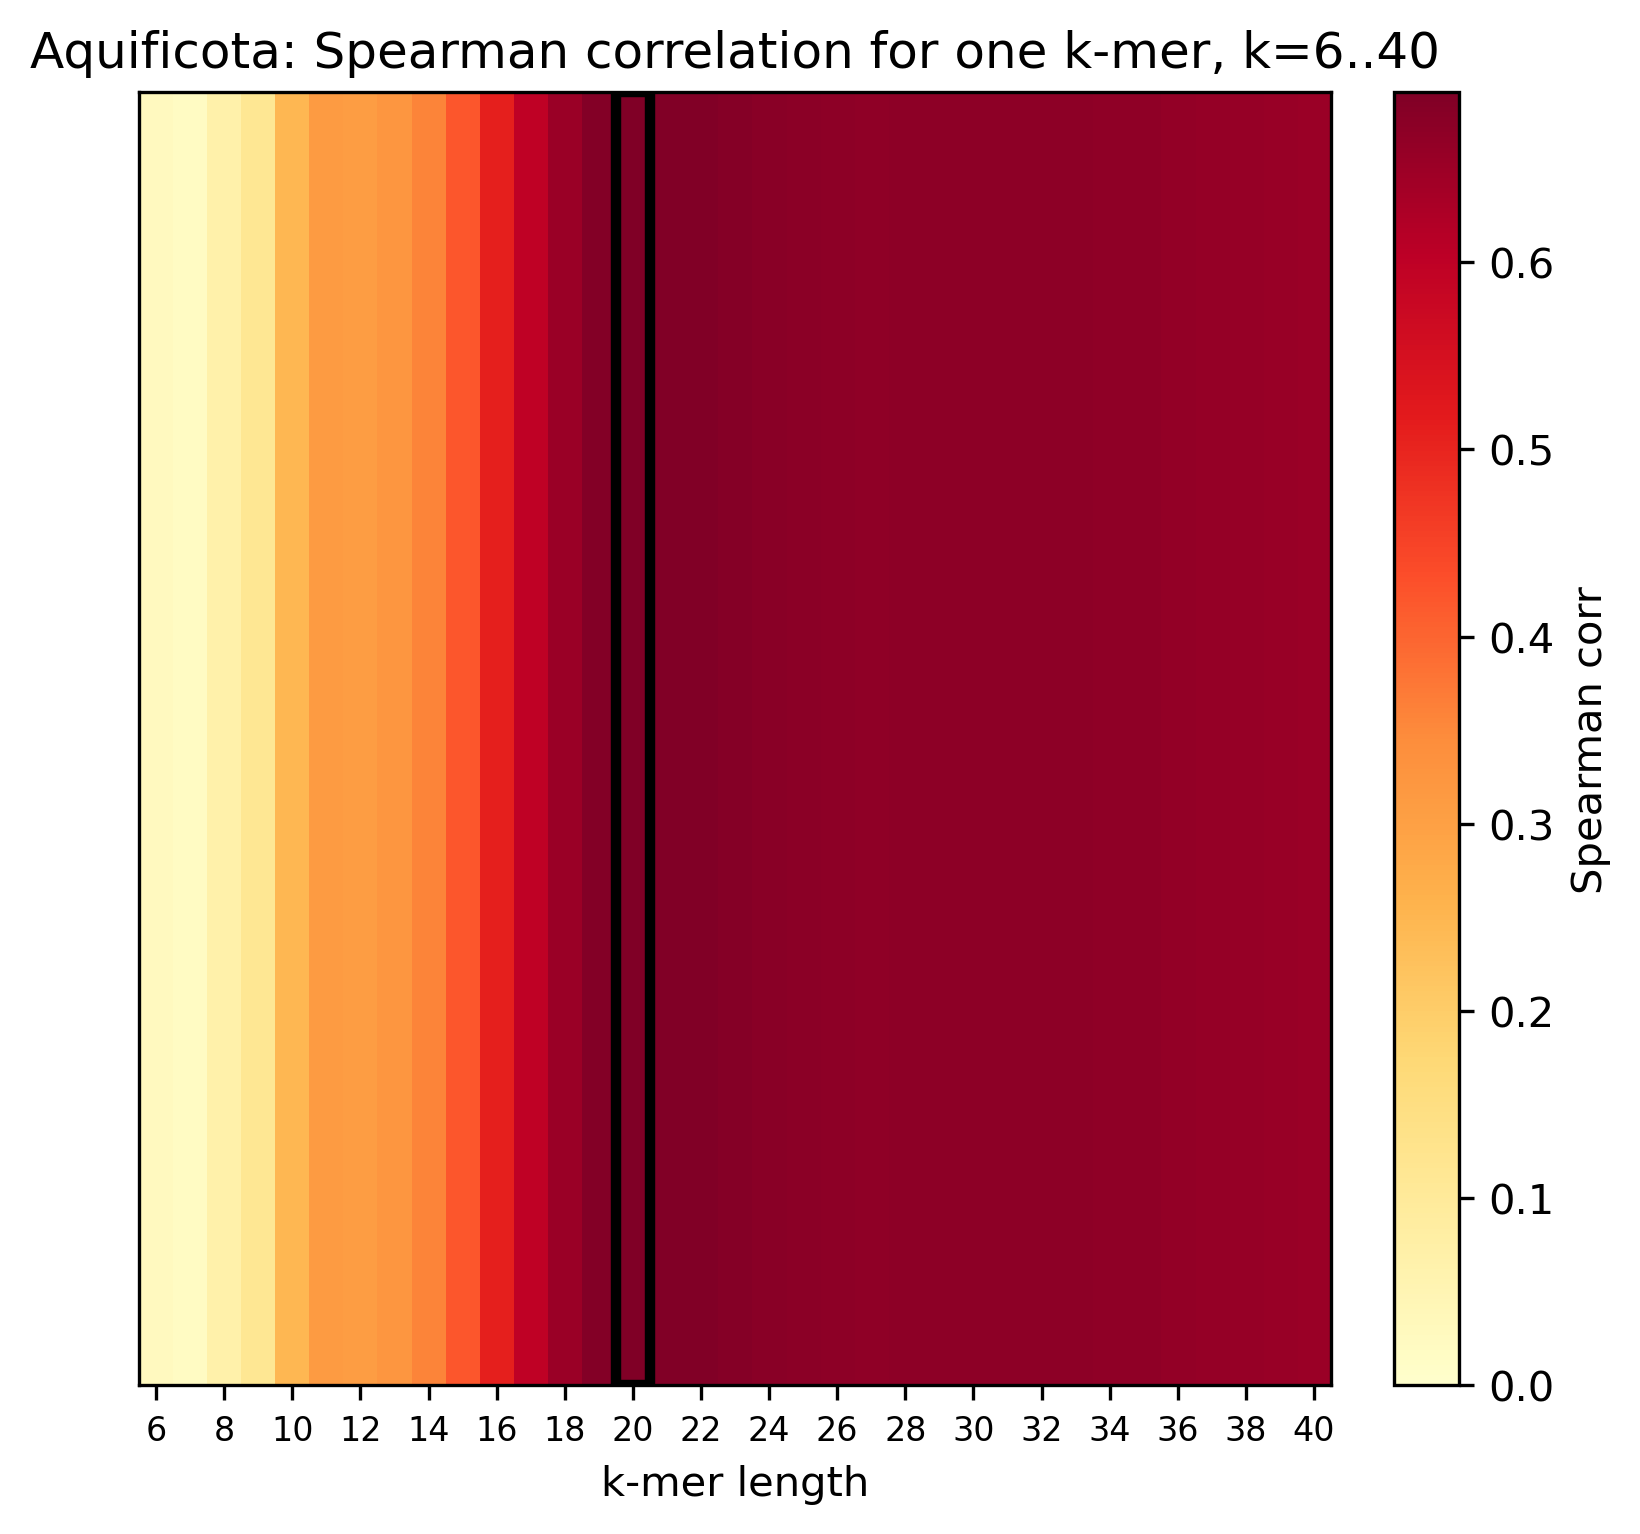


Bacillales


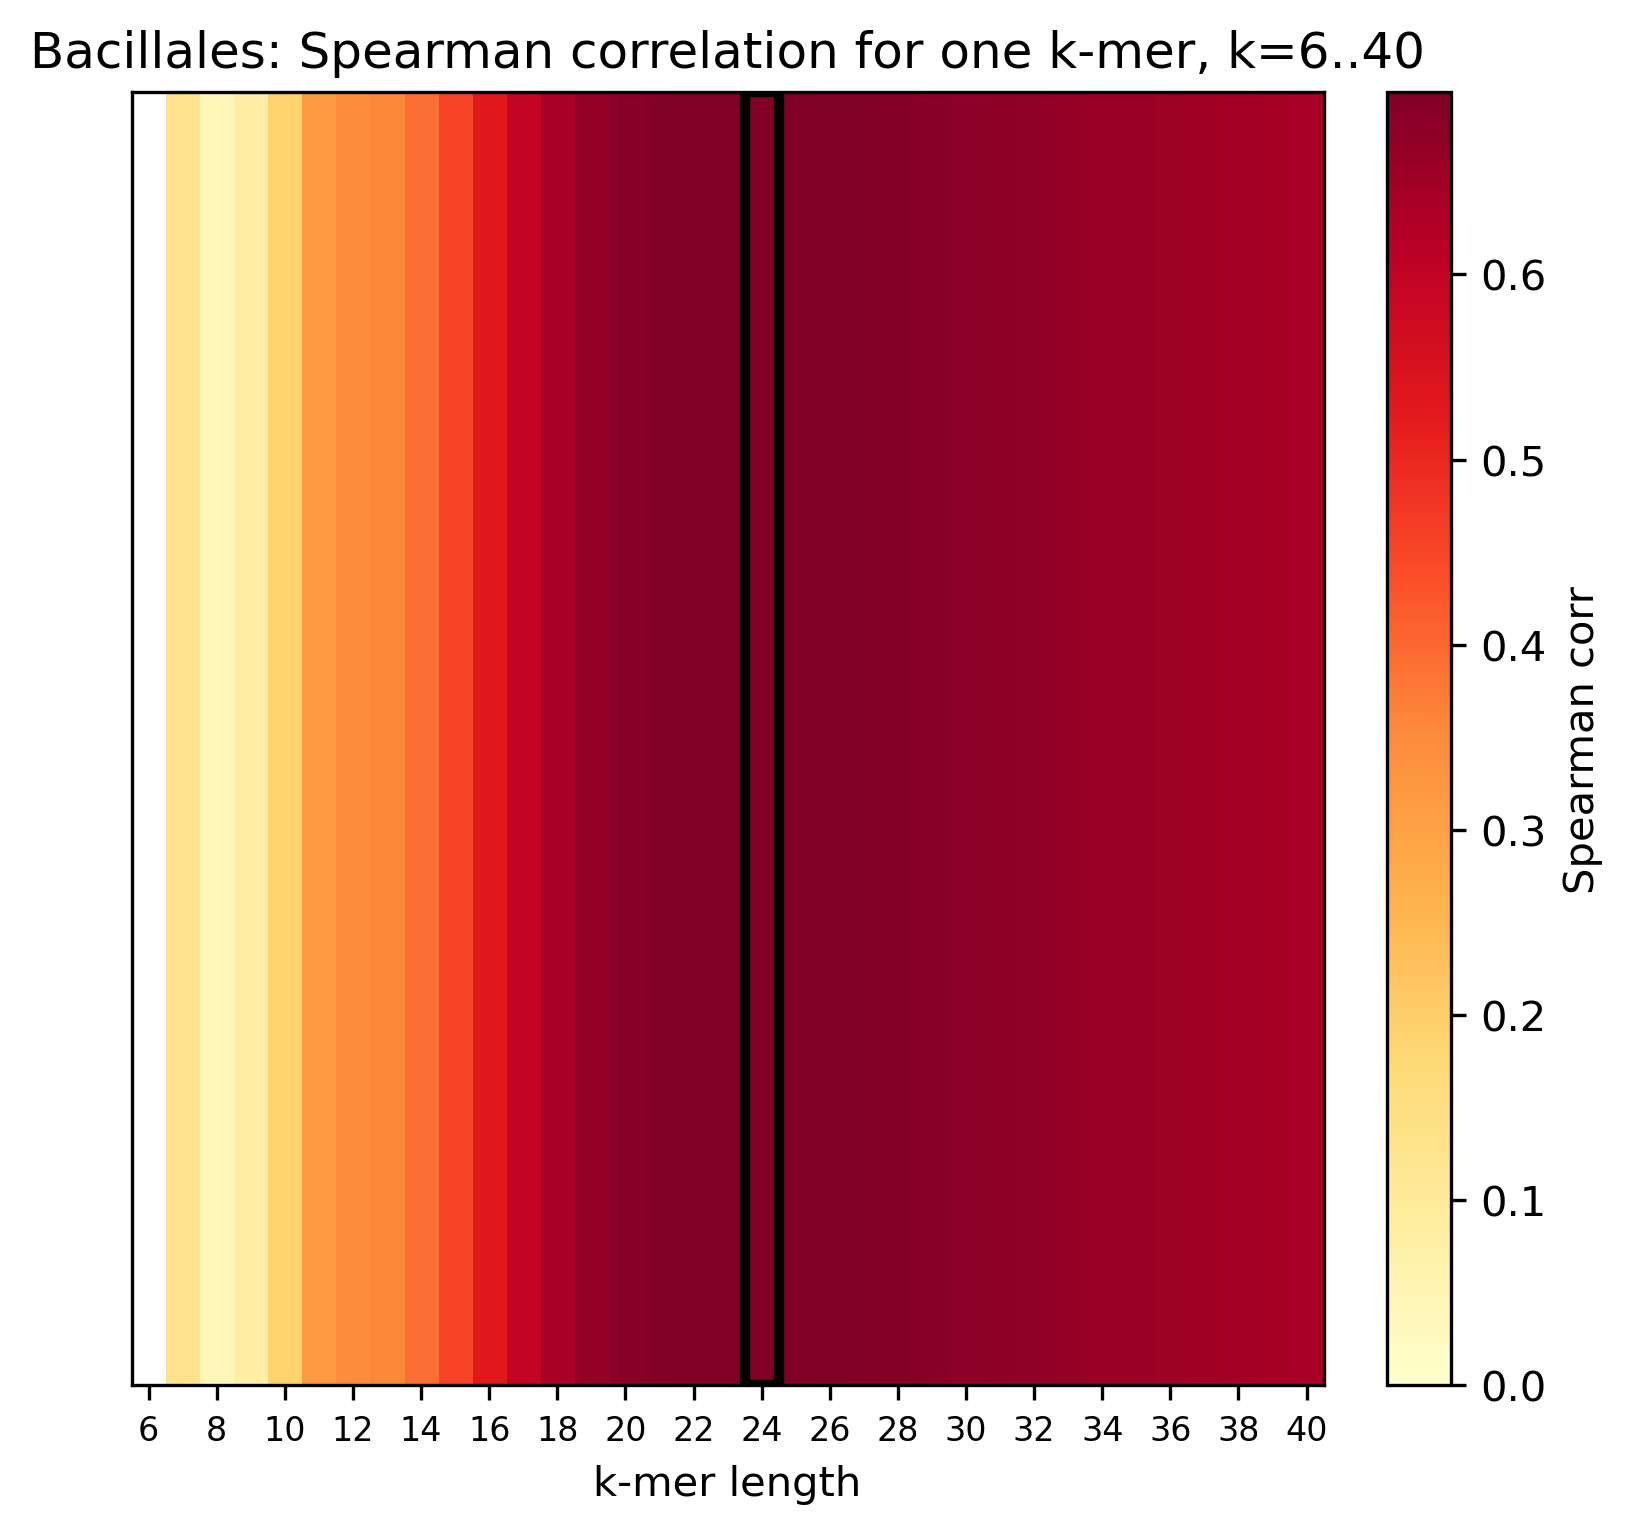


Caldisericia


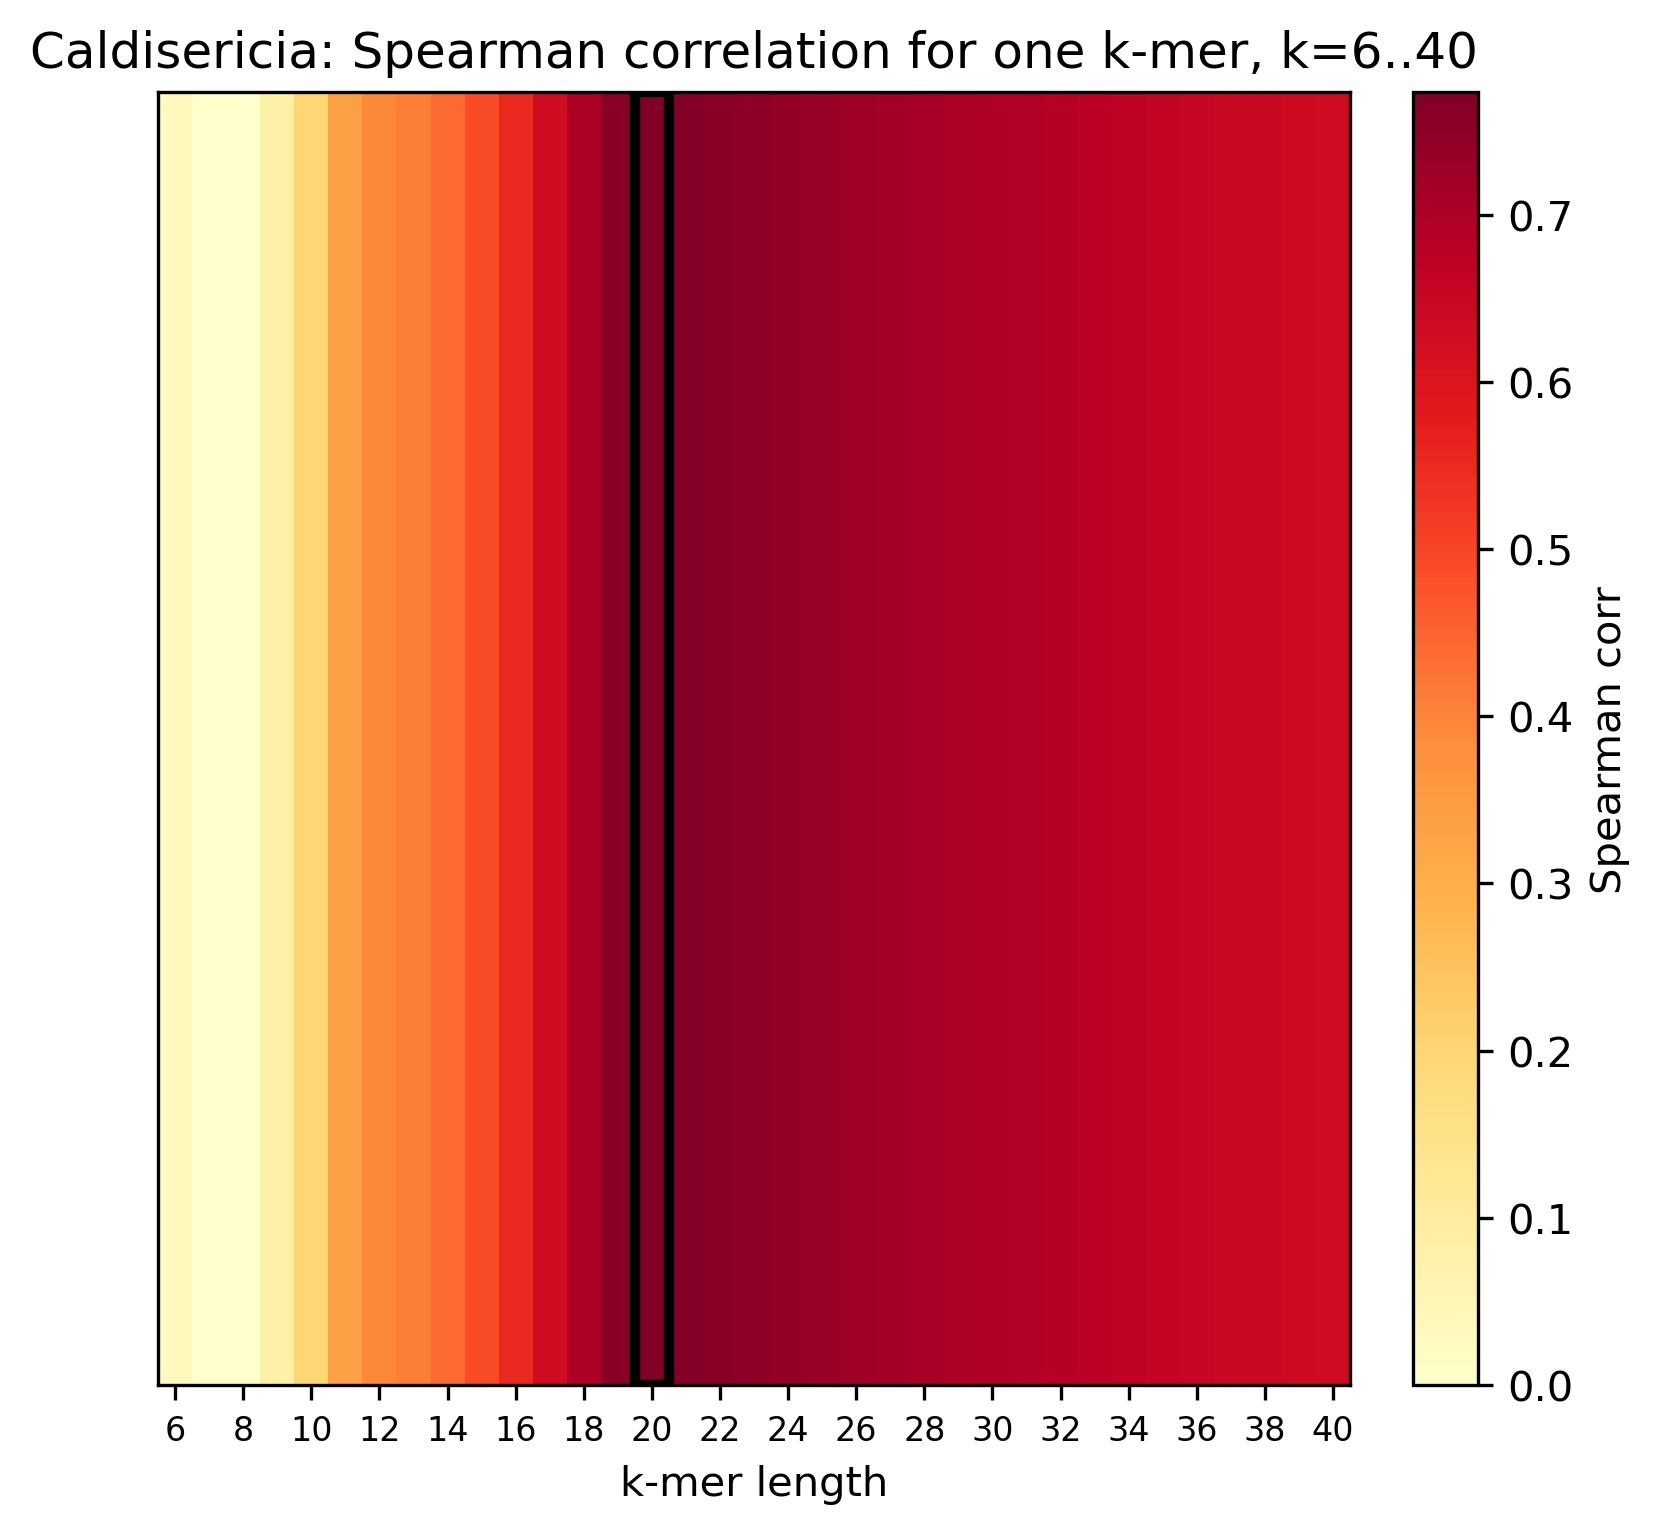


Chlamydia


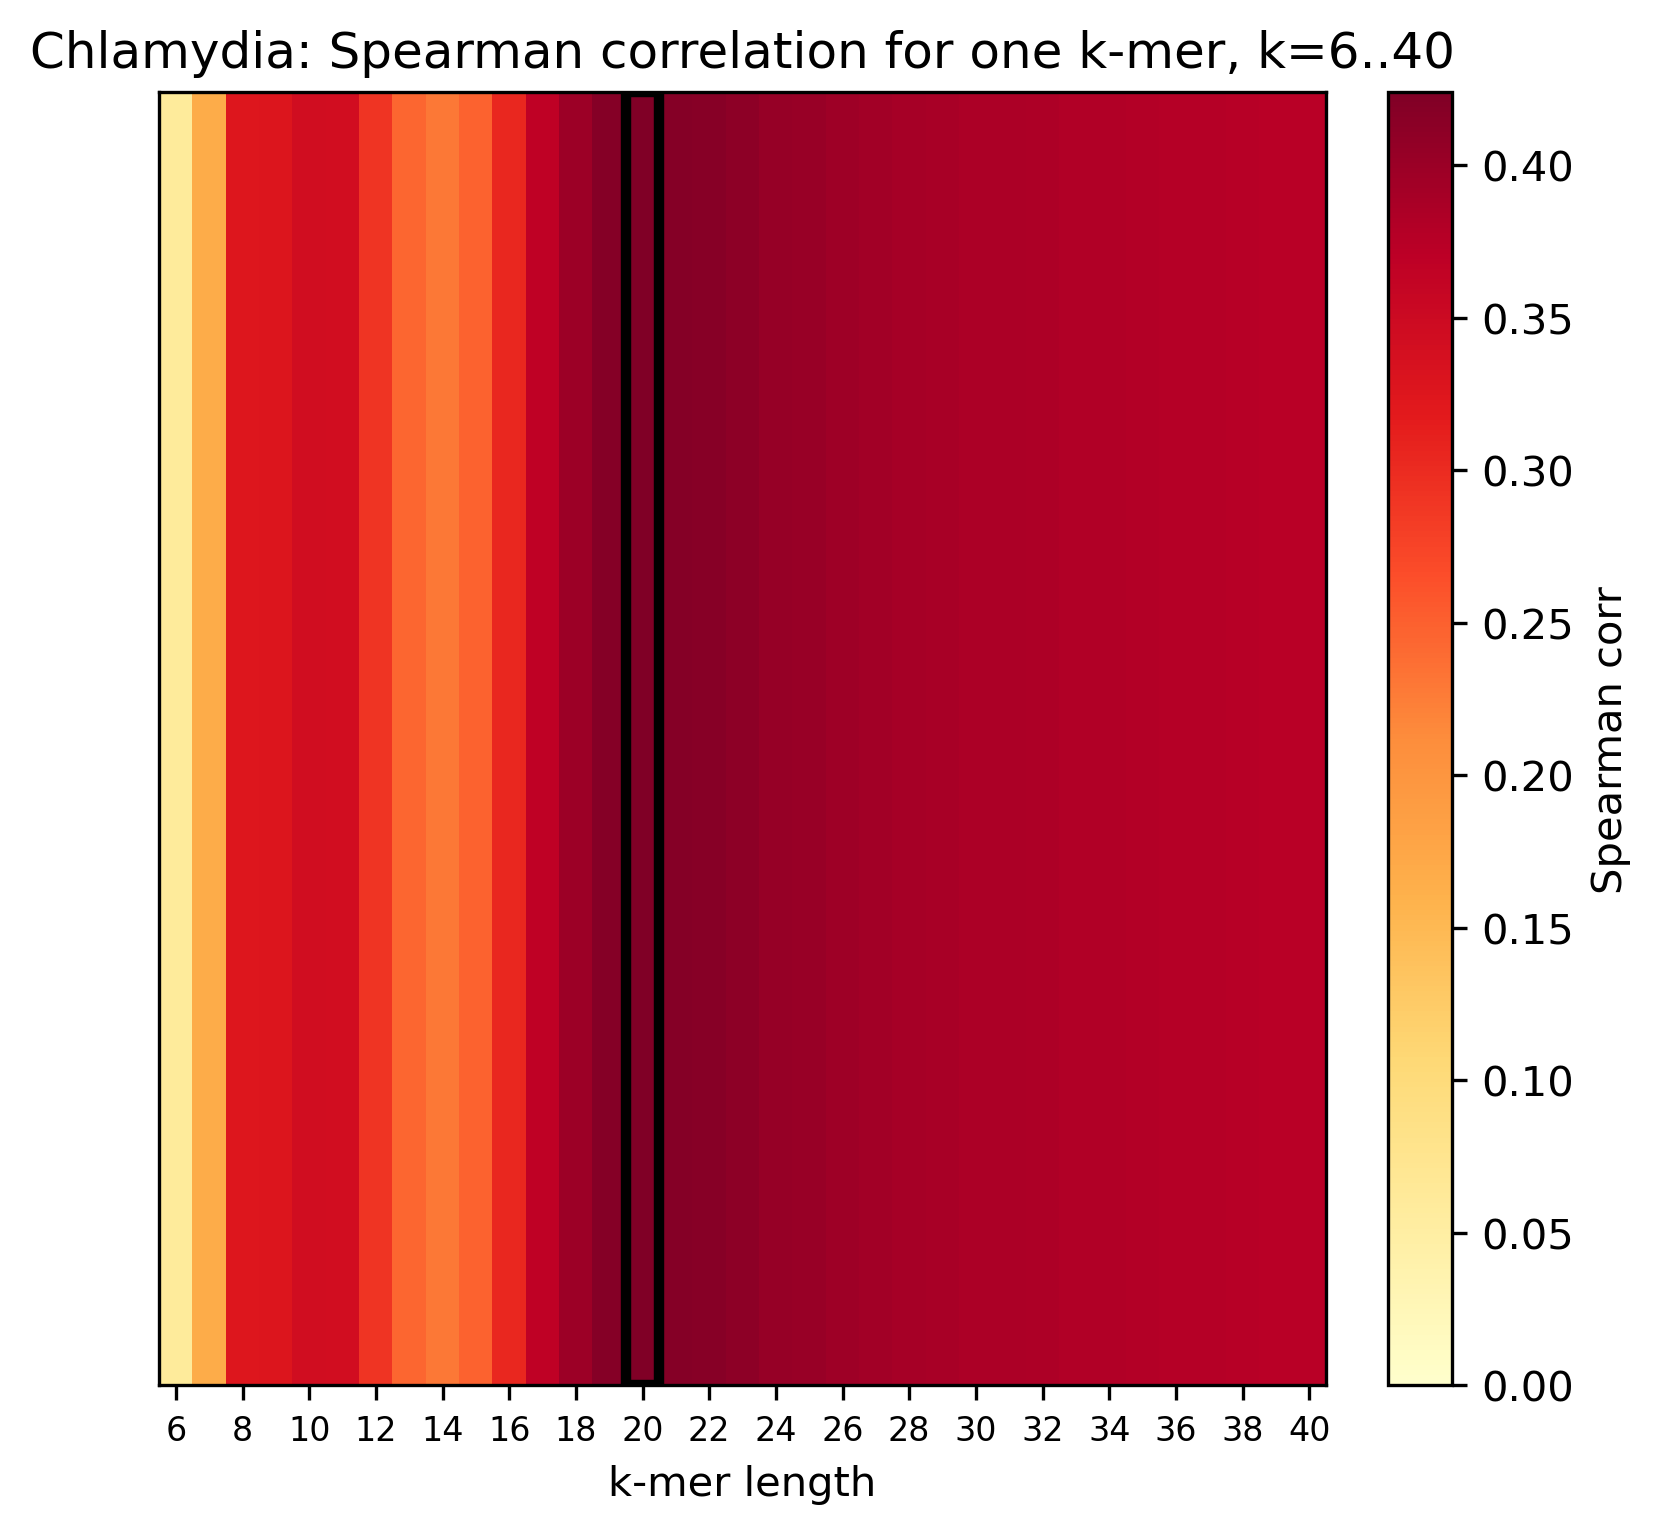


Cyano


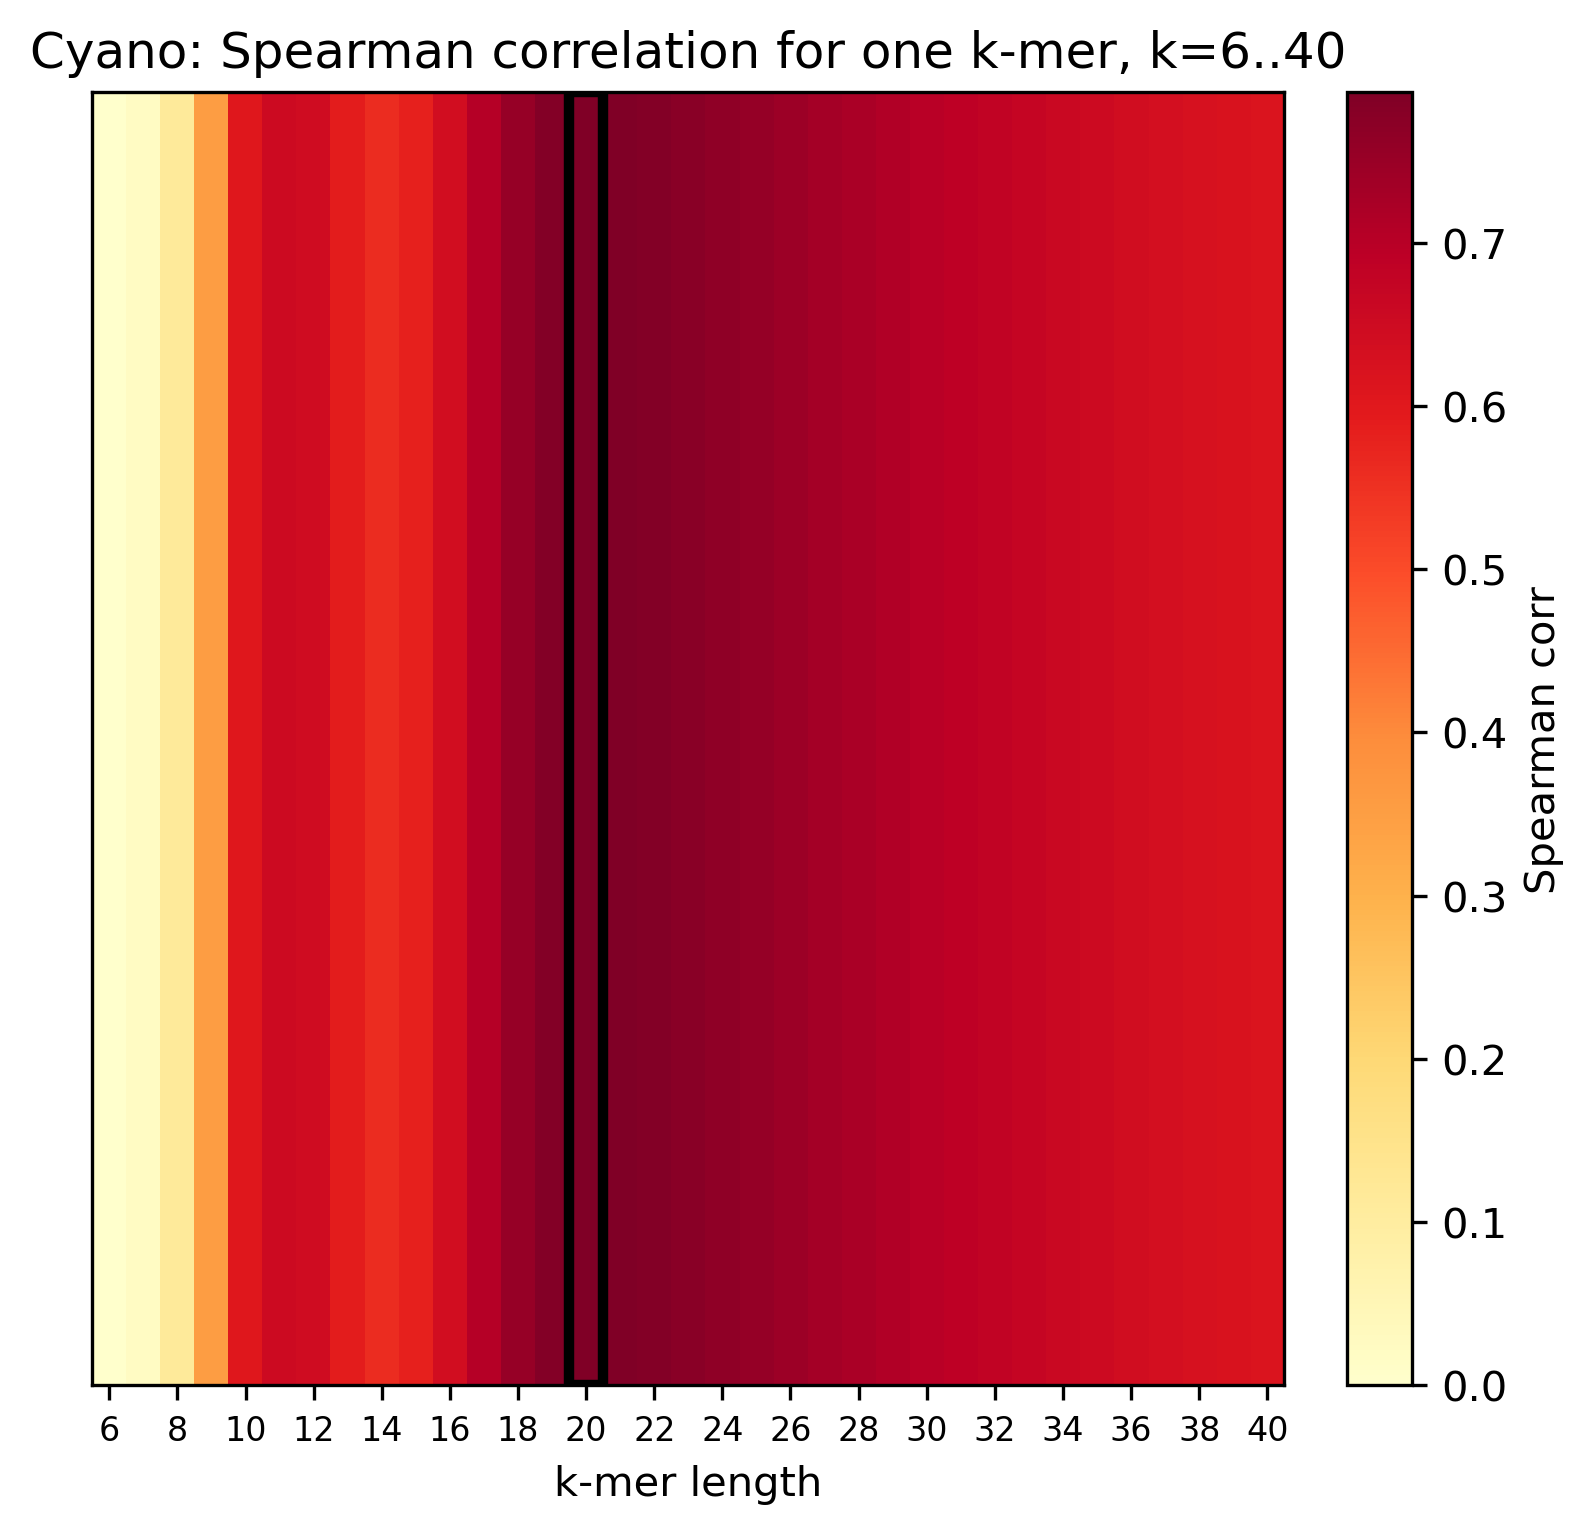


Neisseriaceae


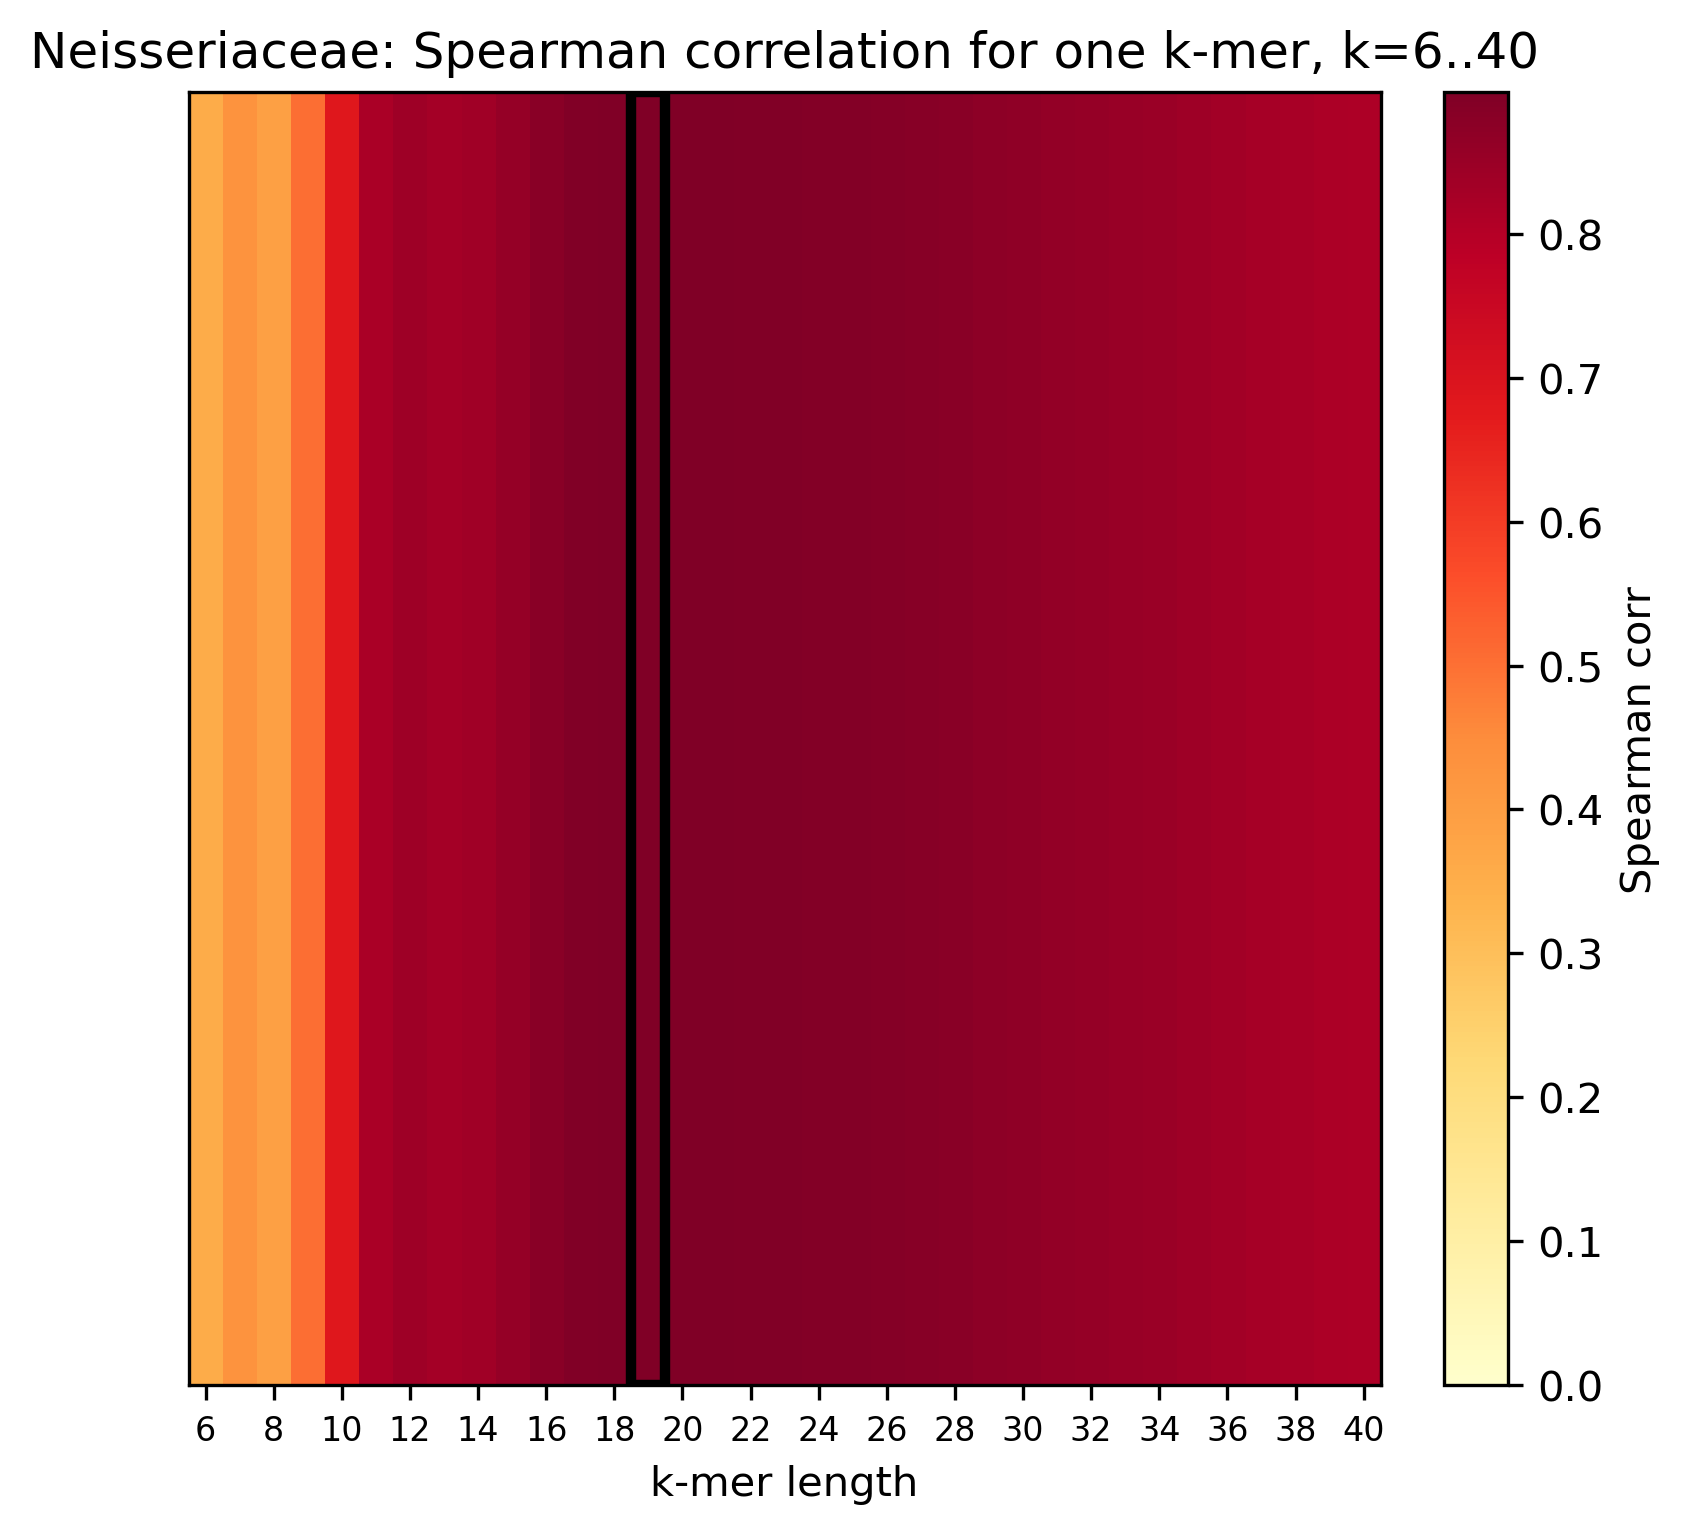

In [25]:
# Run full grid search
for name, merged_df in datasets:
    print(name)
    # if name is 'Chlamydia':
    df, (k, corr, pval) = initial_corr(merged_df, k_low=6, k_high=40)
    # df = np.abs(df)
    # df = -1 * df
    plot_single_corr_colorbar(name, df, k_low=6, k_high=40)
    print()





### Two k-mers


In [29]:
# Full Grid search: unfixed k-mers; with and without weights

def run_full_grid_corr(merged_df, k_low=5, k_high=32, w_low=0, w_high=1, w_step=0.05):
    ''' Full grid search with all degrees of freedom: k1 low-> high, k2 low -> high, with all weights. '''
    ws = np.round(np.arange(w_low, w_high, w_step), 3)
    num_ws = len(ws)
    ks = list(range(k_low, k_high + 1))
    num_ks = len(ks)

    results_matrix = np.zeros((num_ks, num_ks, num_ws))
    for k1_idx, k1 in enumerate(ks):
        k1_rank = merged_df[f'k{k1}_distance'].rank()
        for k2_idx, k2 in enumerate(ks):
            k2_rank = merged_df[f'k{k2}_distance'].rank()
            for w_idx, w in enumerate(ws):
                avg_k1_k2_w_rank = w * k1_rank + (1 - w) * k2_rank   # weight the ranks by w and 1-w
                corr, pval = spearmanr(avg_k1_k2_w_rank, merged_df['tree_distance'])
                results_matrix[k1_idx, k2_idx, w_idx] = corr

    # find global min
    results_matrix = np.nan_to_num(results_matrix, nan=0.0)
    min_val = np.min(results_matrix)
    min_idx = np.unravel_index(np.argmin(results_matrix), results_matrix.shape)
    k1_min, k2_min, w_min = ks[min_idx[0]], ks[min_idx[1]], ws[min_idx[2]]
    print(f"Grid Ks: {k1_min, k2_min} with weight {w_min}; corr: {min_val}")
    print(min_idx)
    return results_matrix, min_val, k1_min, k2_min, w_min, min_val


In [27]:

def plot_2d_heatmap_from_results_matrix(name, results_matrix, k_low, k_high):
    """
    Plot a 2D heatmap using only the first two dimensions (k1, k2) of results_matrix.
    Averages (or finds the min/max) over the remaining dimension (e.g., ws).
    Spearman correlation strength is shown; the axes cover all ks in the range.
    """
    aggregate_matrix = np.max(results_matrix, axis=2)  # shape [k1, k2]

    ks = list(range(k_low, k_high + 1))
    n_ks = len(ks)
    fig, ax = plt.subplots(figsize=(8, 6))

    im = ax.imshow(aggregate_matrix, origin="lower", aspect="equal", cmap="YlOrRd")
    # im = ax.imshow(aggregate_matrix, vmin=0, origin="lower", aspect="equal", cmap="YlOrRd")
    # im = ax.imshow(aggregate_matrix, vmin=0, vmax=0.5252762634393853, origin="lower", aspect="equal", cmap="YlOrRd")

    # Label axes as k1 (y), k2 (x):
    ax.set_xlabel("k2")
    ax.set_ylabel("k1")
    ax.set_title(f"{name}: Spearman correlation for two k-mers, k={k_low}..{k_high}")
    # ax.set_title(f"{name}: Spearman correlation vs tree distance\n(k1, k2 grid, min over w)")

    xticks = yticks = list(range(n_ks))
    ax.set_xticks(xticks)
    ax.set_xticklabels(ks, fontsize=8, rotation=90)
    ax.set_yticks(yticks)
    ax.set_yticklabels(ks, fontsize=8)

    # Optional: mark the globally min (best) cell
    max_val = np.nanmax(aggregate_matrix)
    min_indices = np.where(aggregate_matrix == max_val)
    print(min_indices, max_val)
    if len(min_indices[0]) > 0:
        y, x = min_indices[0][0], min_indices[1][0]
        ax.add_patch(plt.Rectangle((x-0.5, y-0.5), 1, 1, fill=False, edgecolor='black', lw=2.5))

    cbar = fig.colorbar(im, ax=ax, shrink=0.8, label="Spearman correlation")
    plt.tight_layout()
    plt.show()

# Example usage (replace with actual data as needed)
# plot_2d_heatmap_from_results_matrix("Chlamydiales", results_matrix, k_low=6, k_high=40)


Aquificota
Grid Ks: (34, 20) with weight 0.2; corr: -0.6930305020275189
(28, 14, 3)
(array([28]), array([14])) 0.6930305020275189


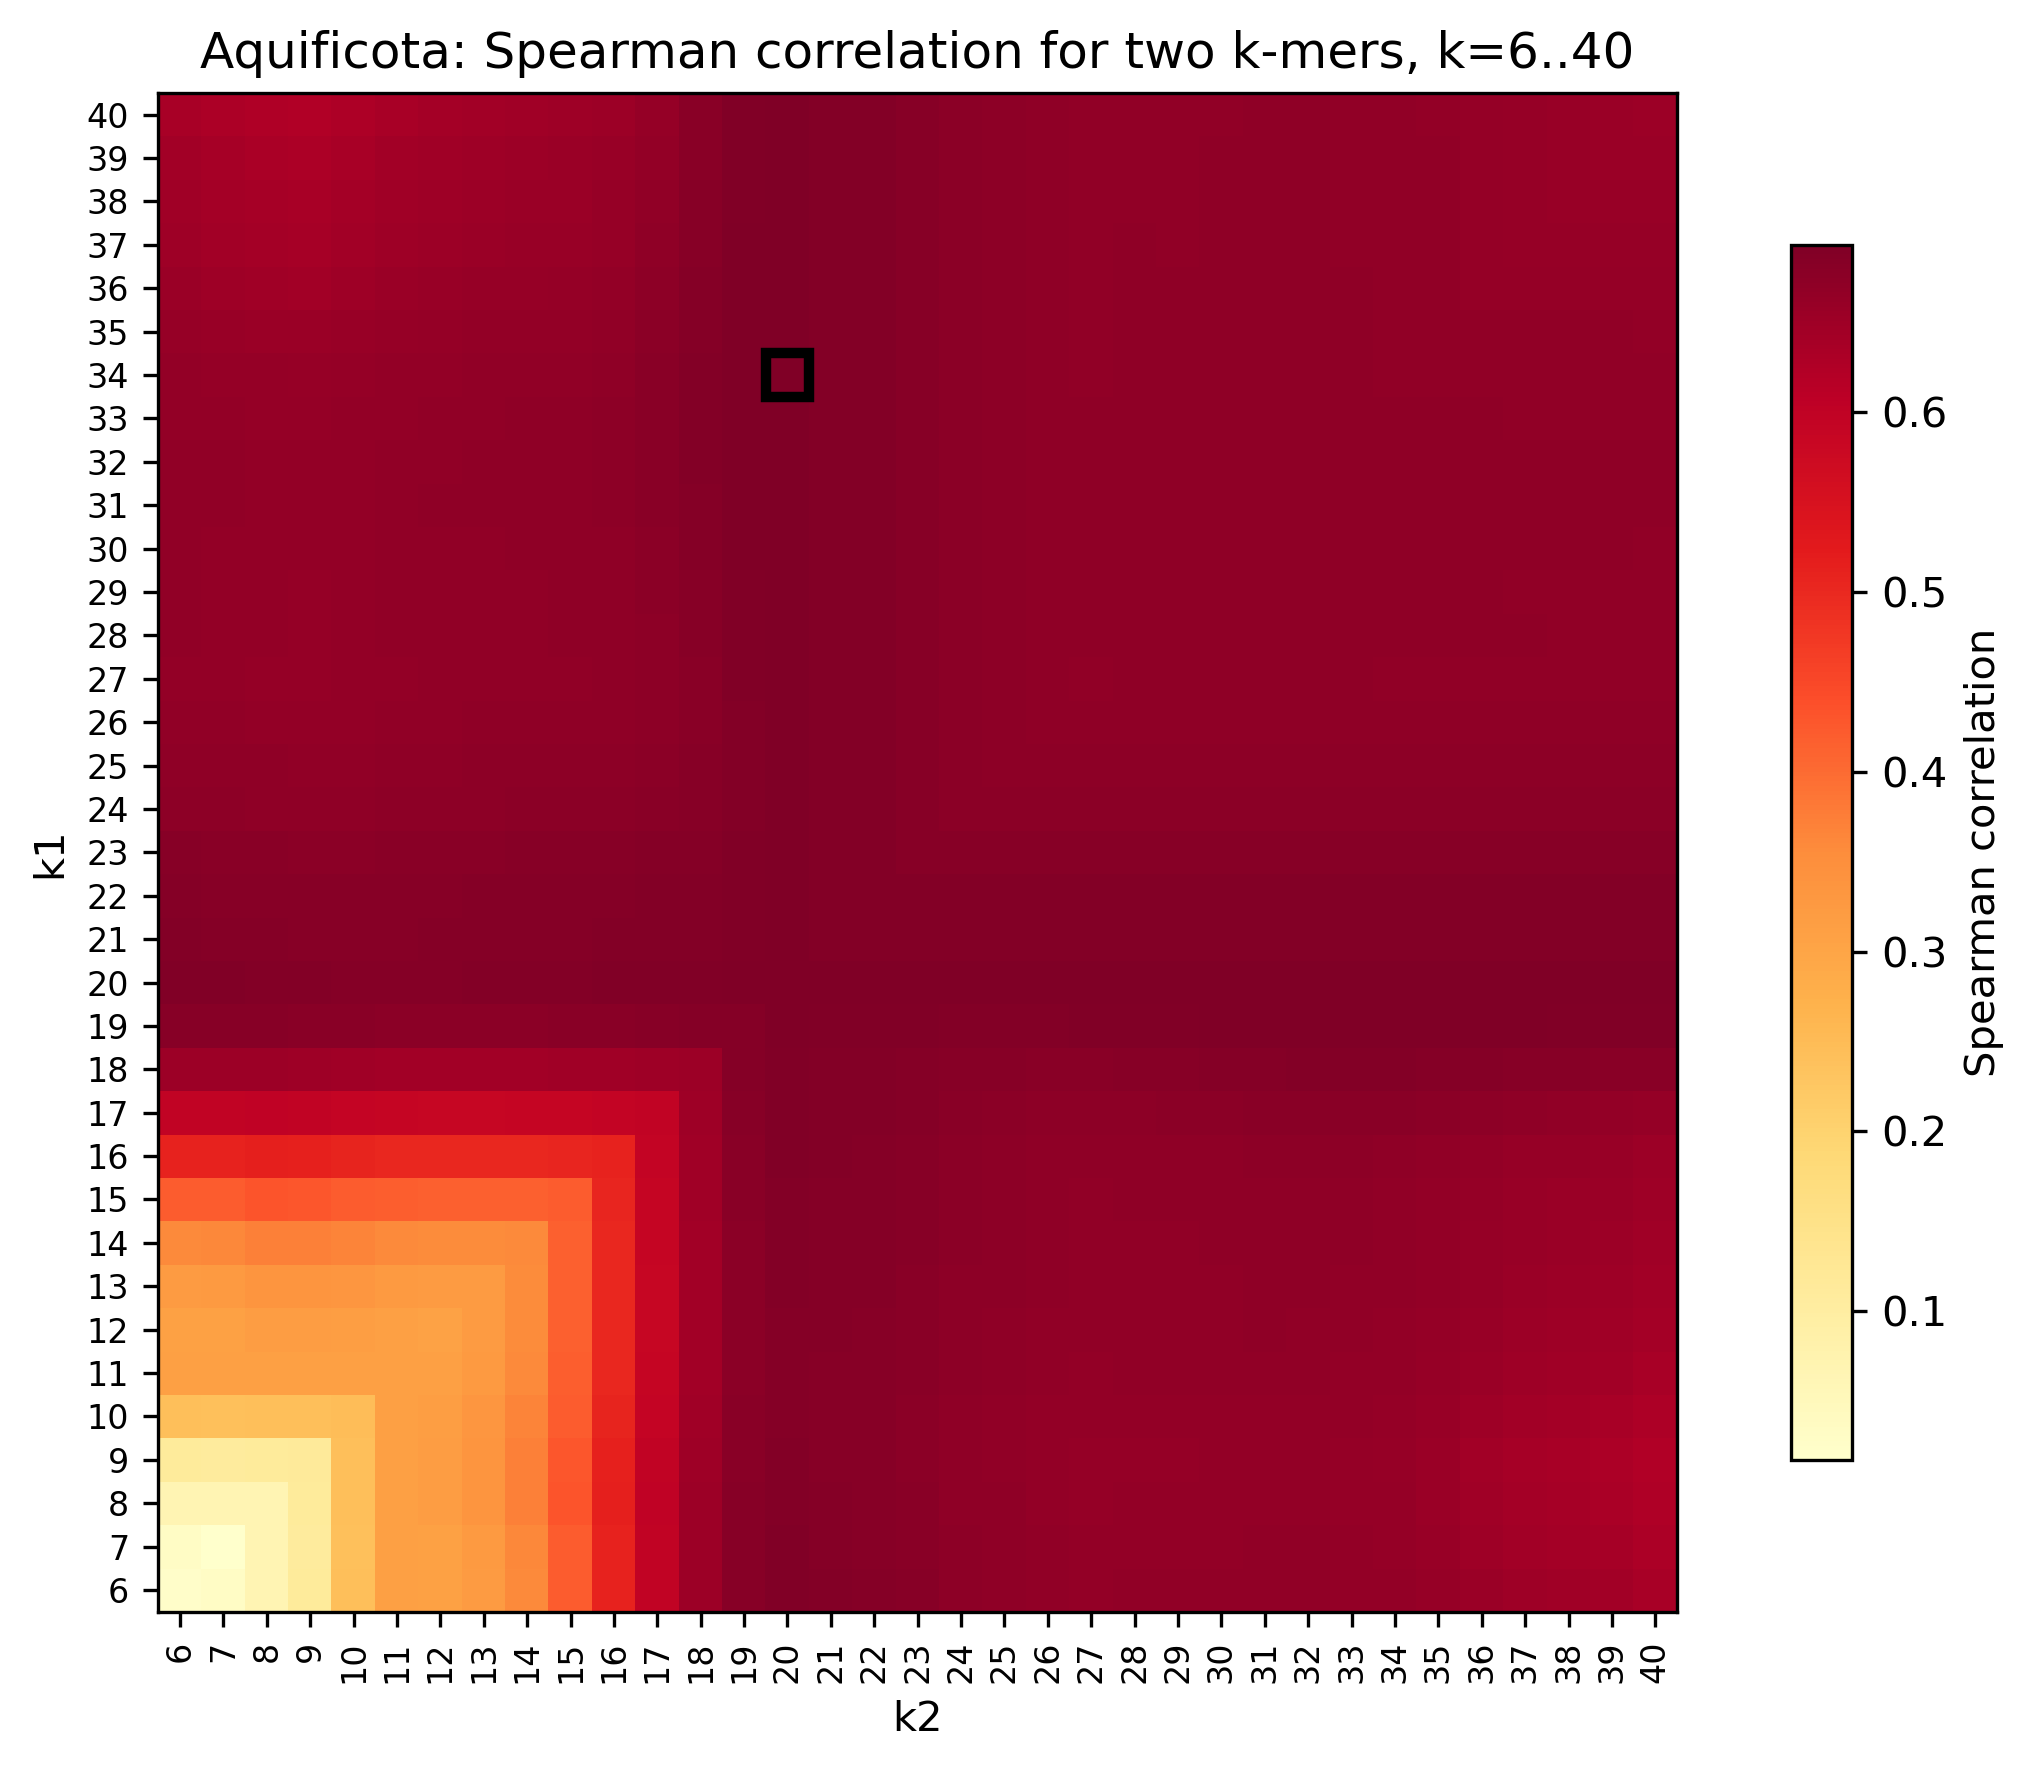


Bacillales
Grid Ks: (7, 23) with weight 0.25; corr: -0.6993156409948573
(1, 17, 4)
(array([ 1, 17]), array([17,  1])) 0.6993156409948573


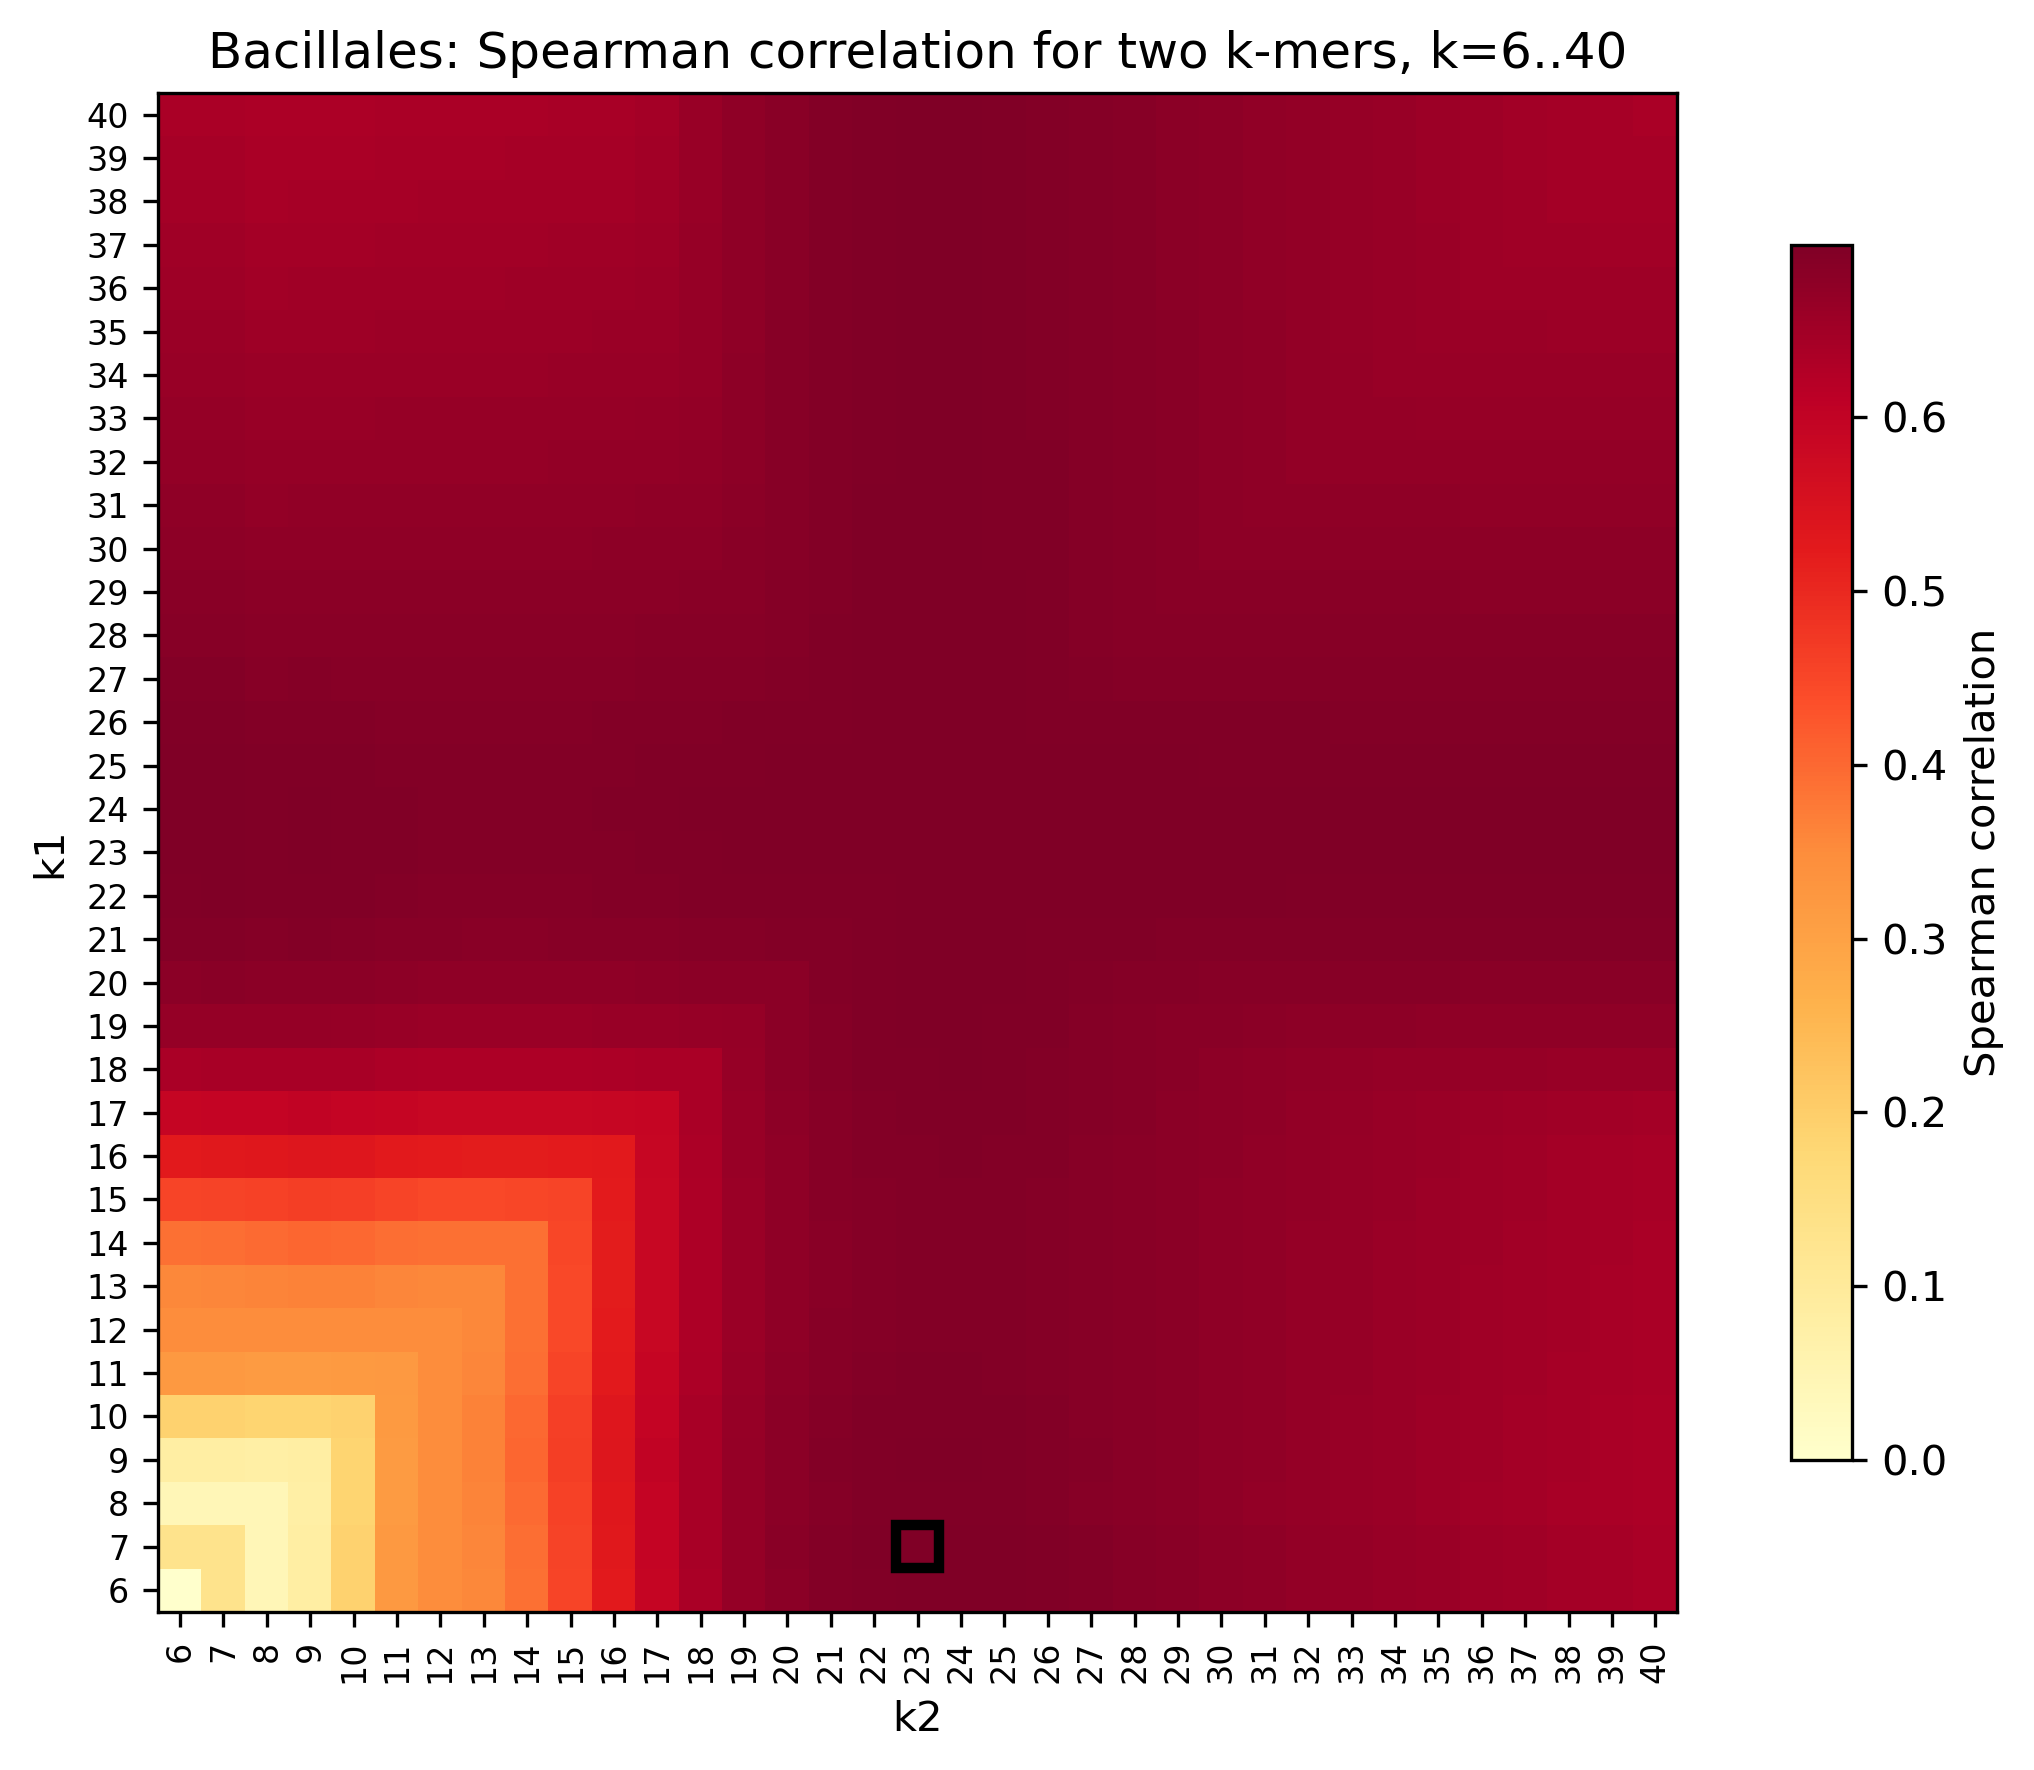


Caldisericia
Grid Ks: (20, 20) with weight 0.05; corr: -0.7732939230754757
(14, 14, 0)
(array([14]), array([14])) 0.7732939230754757


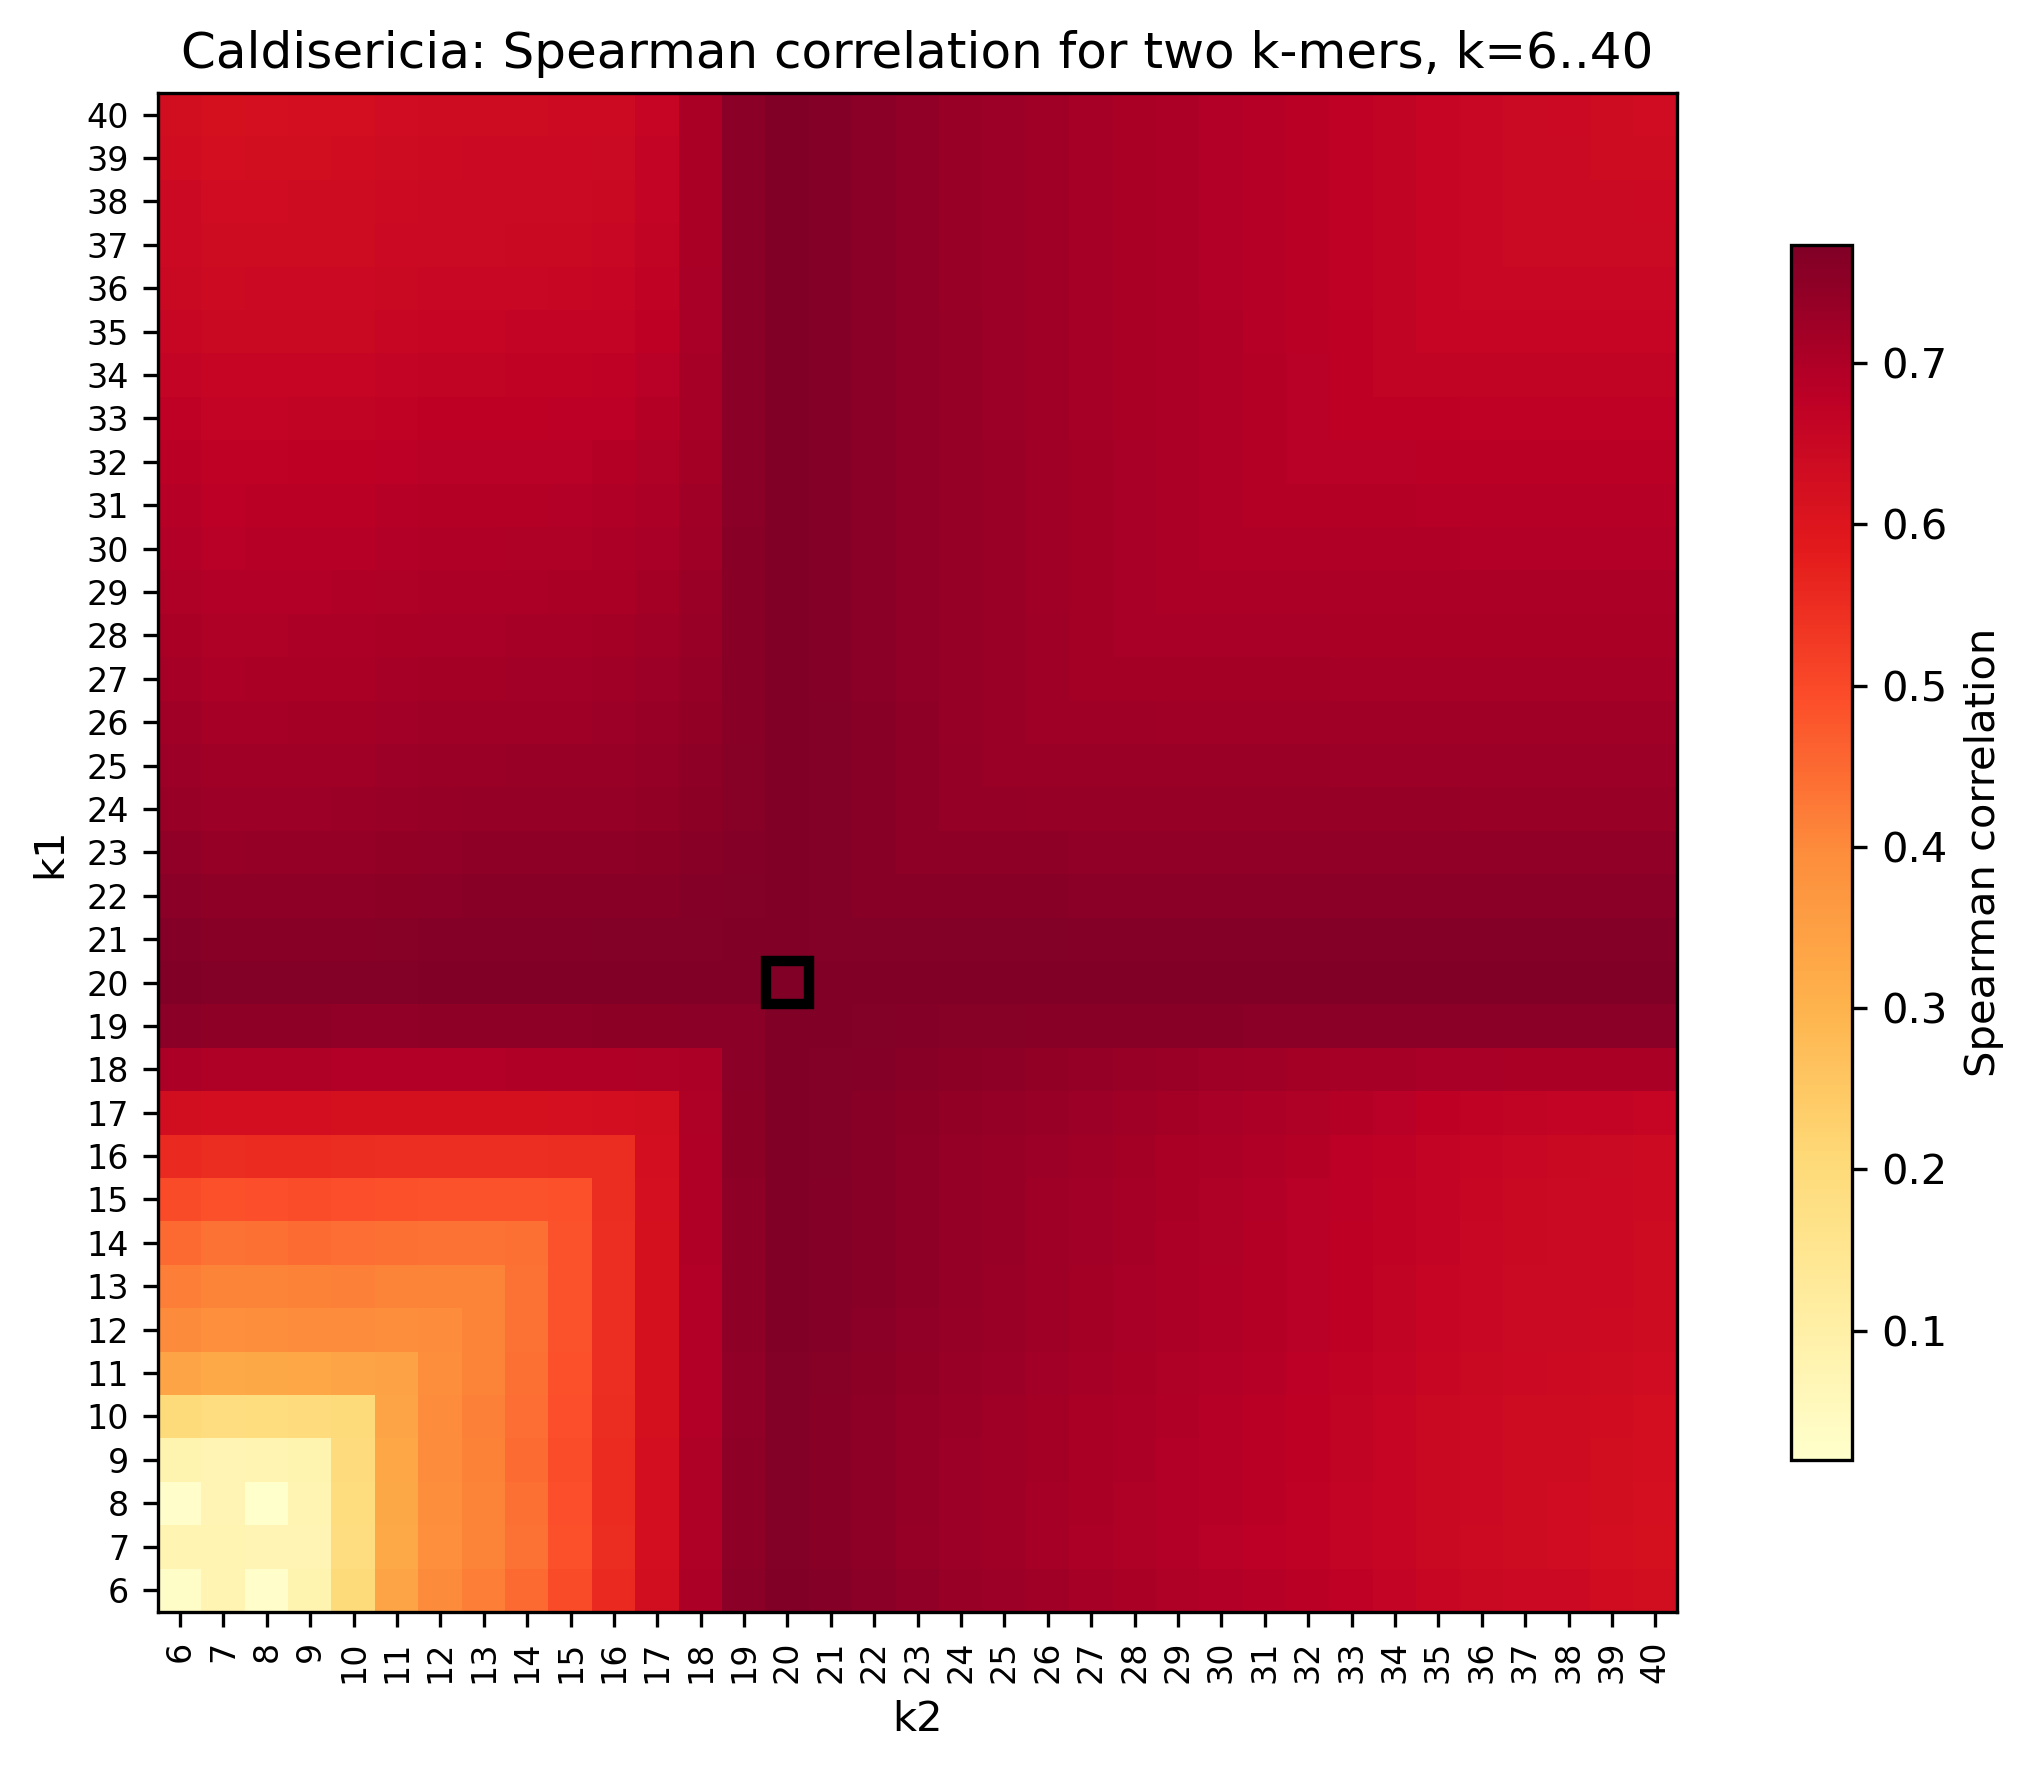


Chlamydia
Grid Ks: (9, 18) with weight 0.45; corr: -0.5132143691921338
(3, 12, 8)
(array([3]), array([12])) 0.5132143691921338


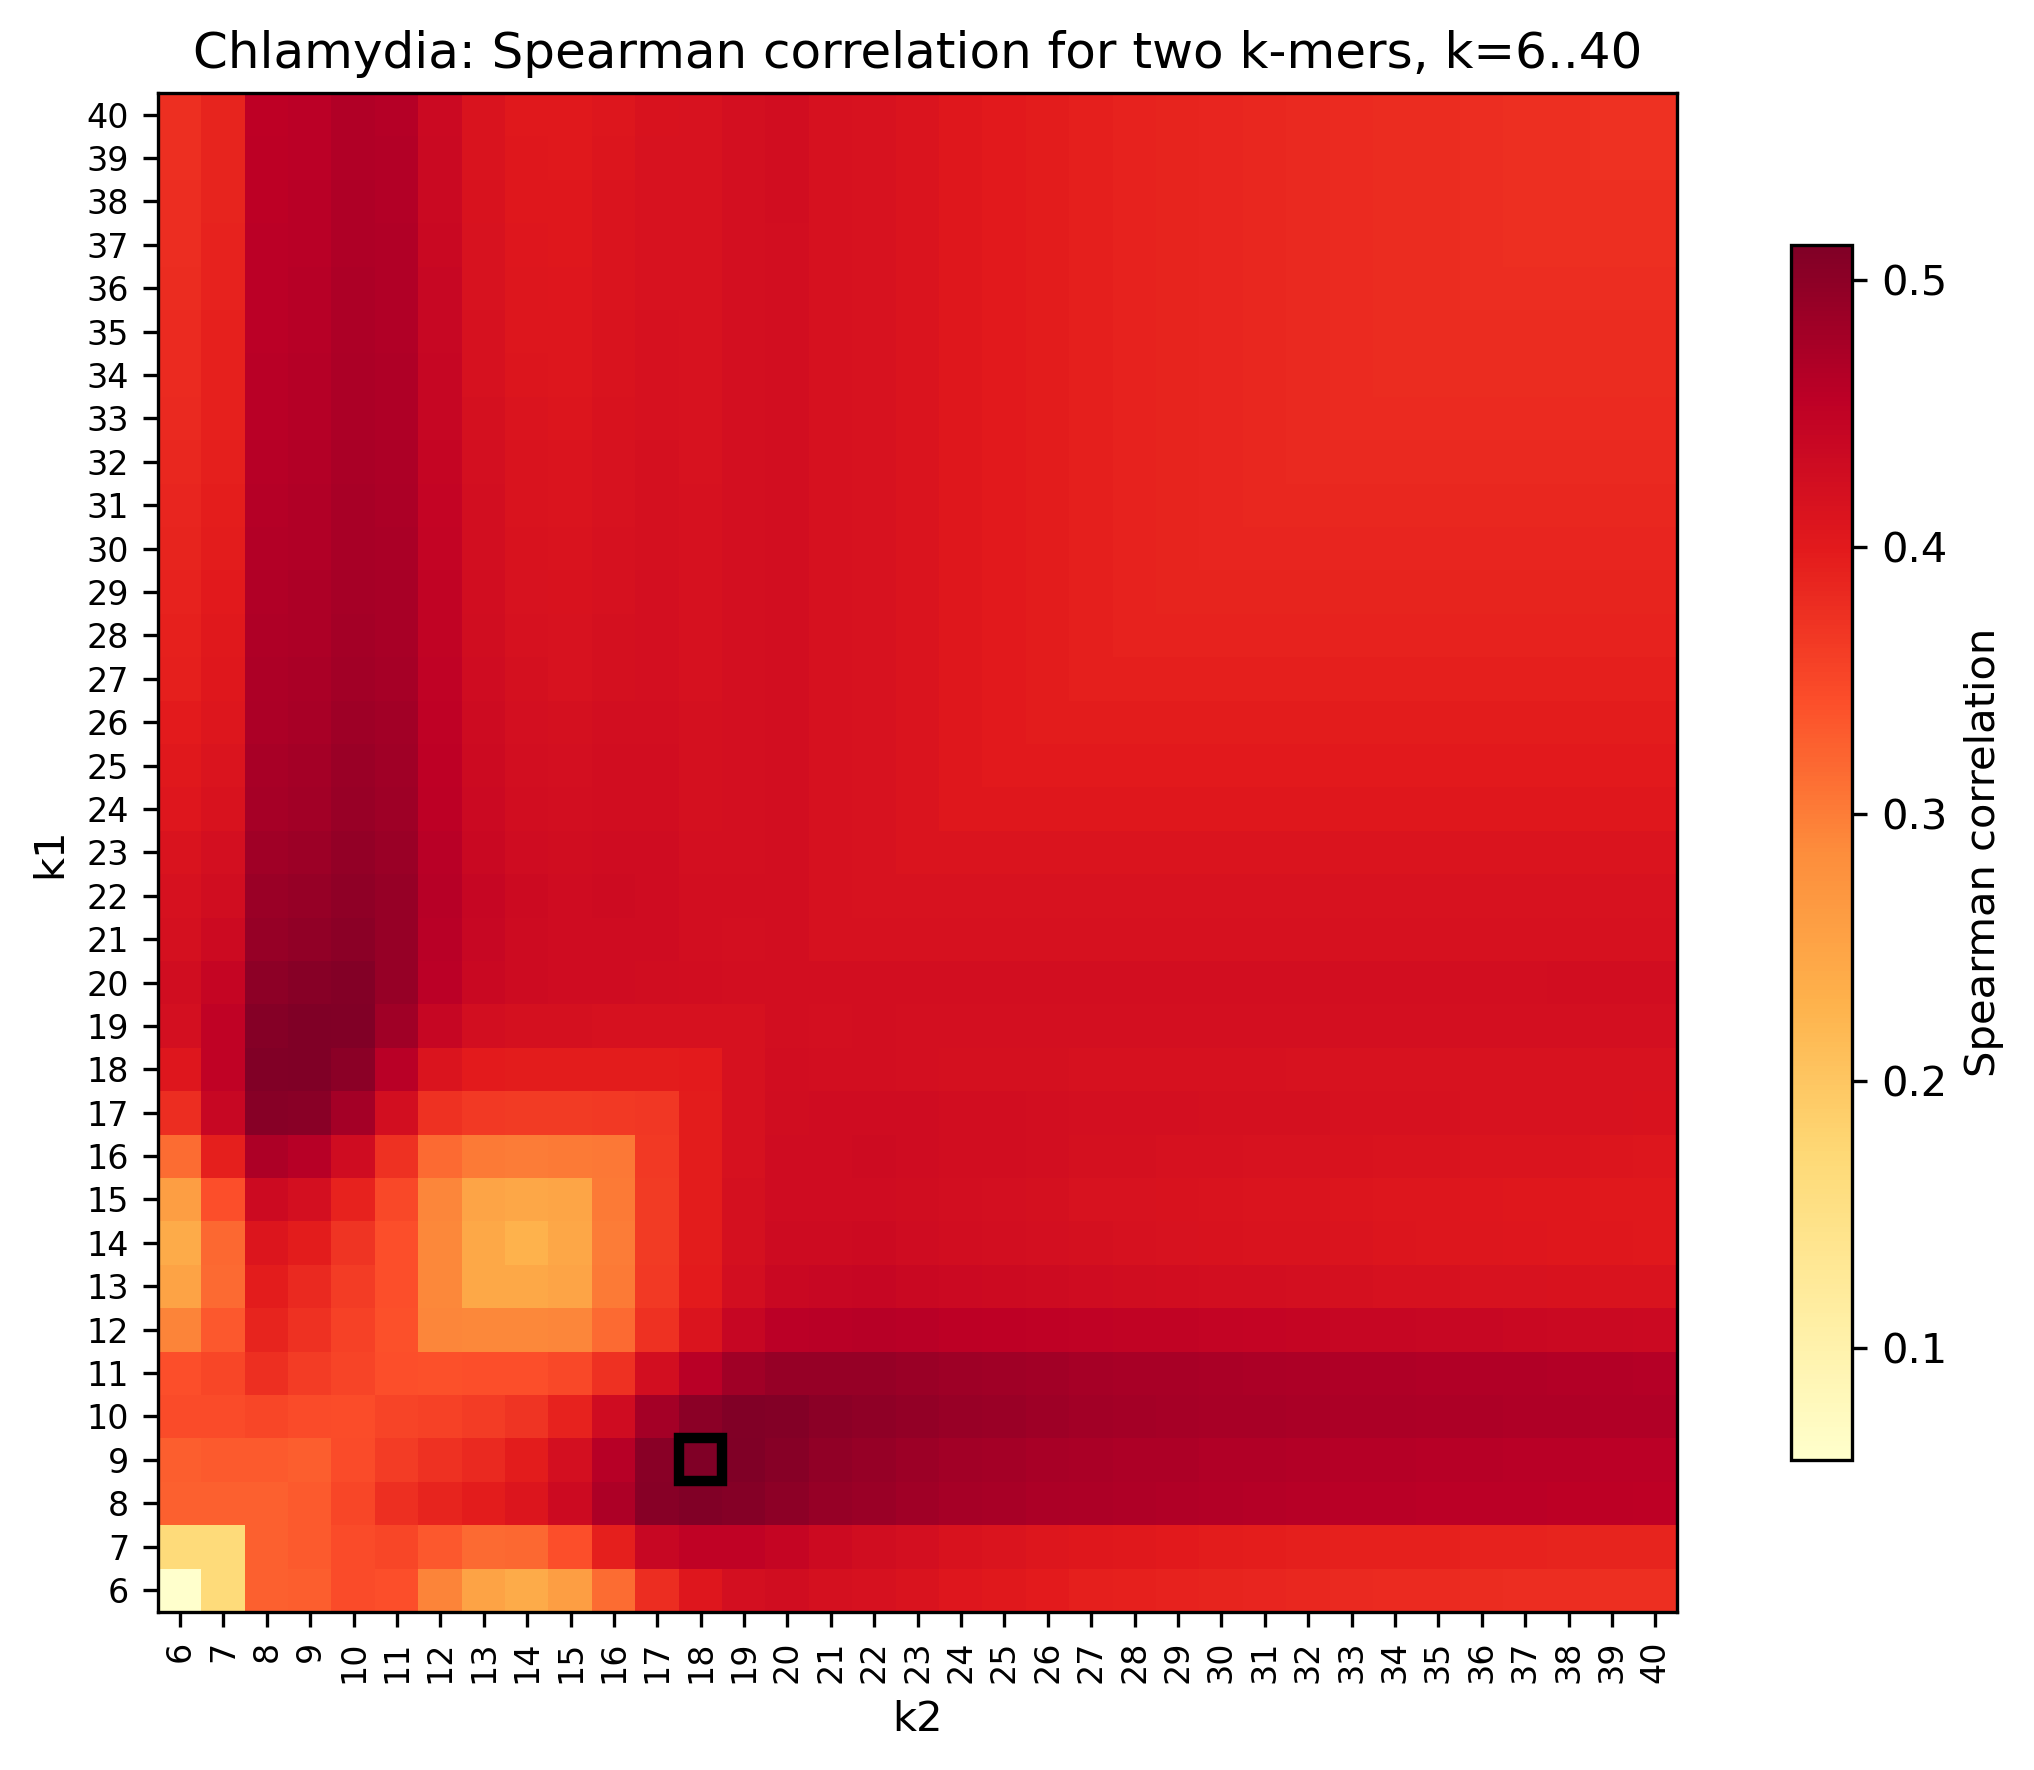


Cyano
Grid Ks: (10, 20) with weight 0.25; corr: -0.8159030261740672
(4, 14, 4)
(array([ 4, 14]), array([14,  4])) 0.8159030261740672


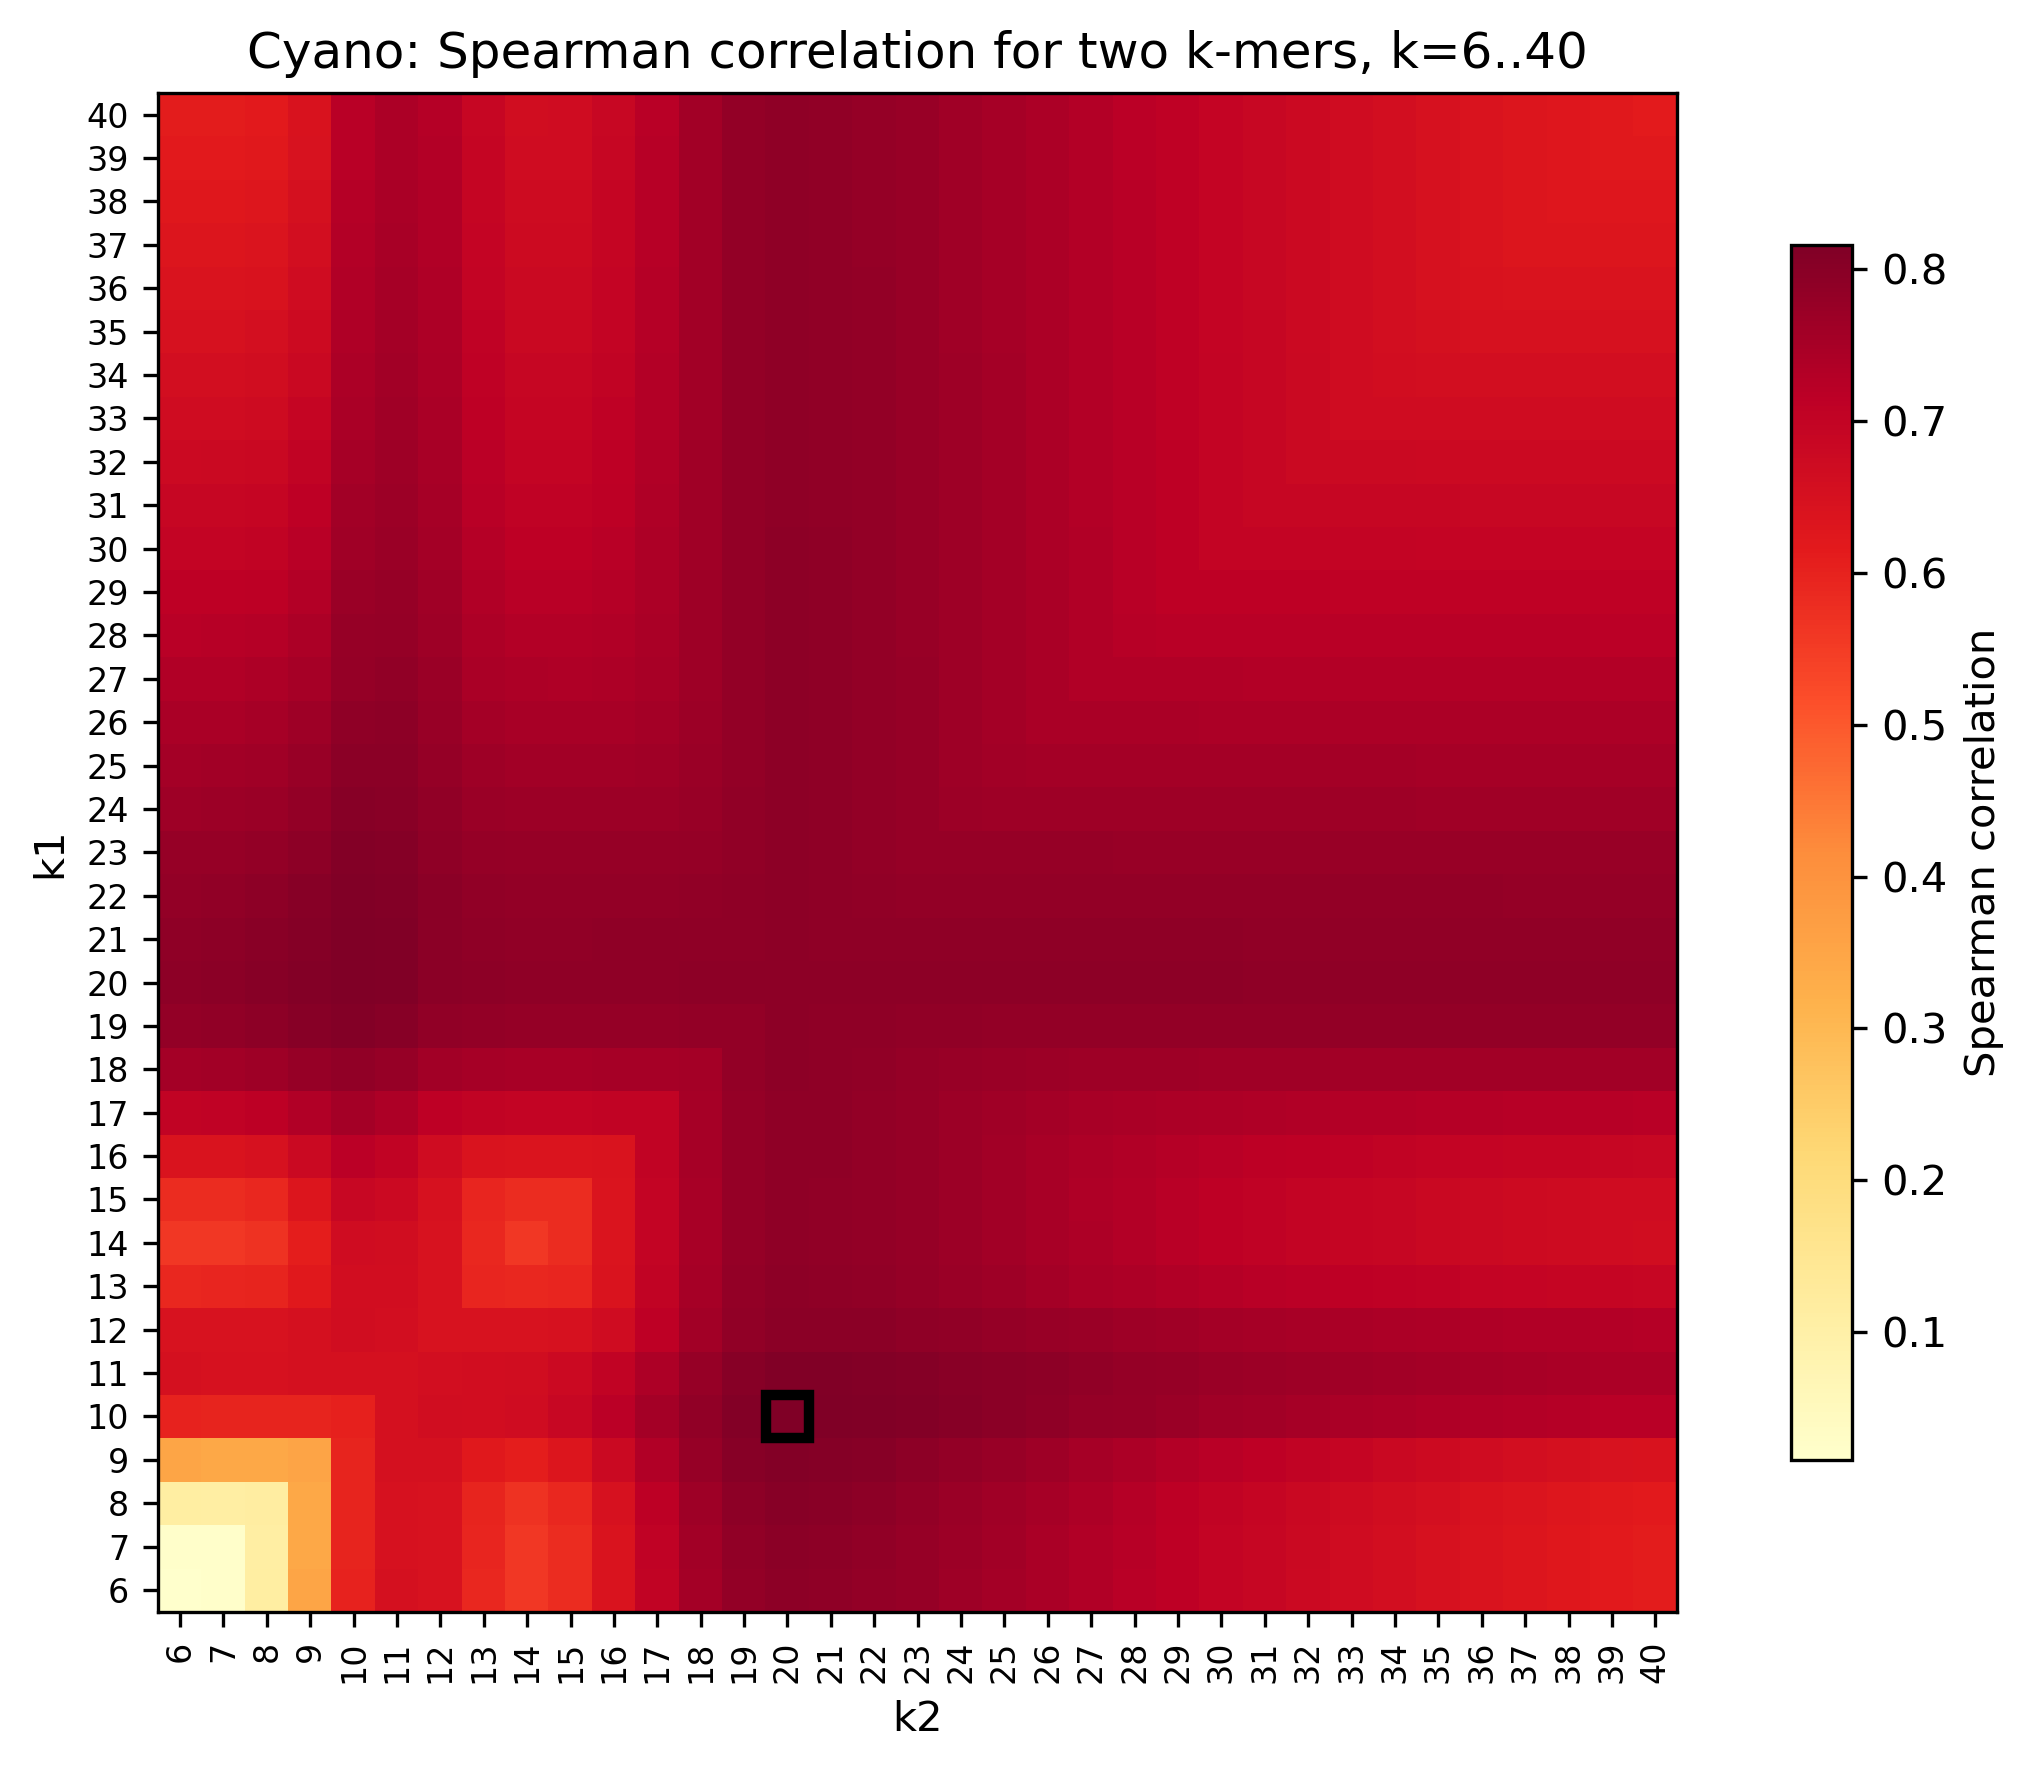


Neisseriaceae
Grid Ks: (10, 19) with weight 0.2; corr: -0.9102818641263019
(4, 13, 3)
(array([4]), array([13])) 0.9102818641263019


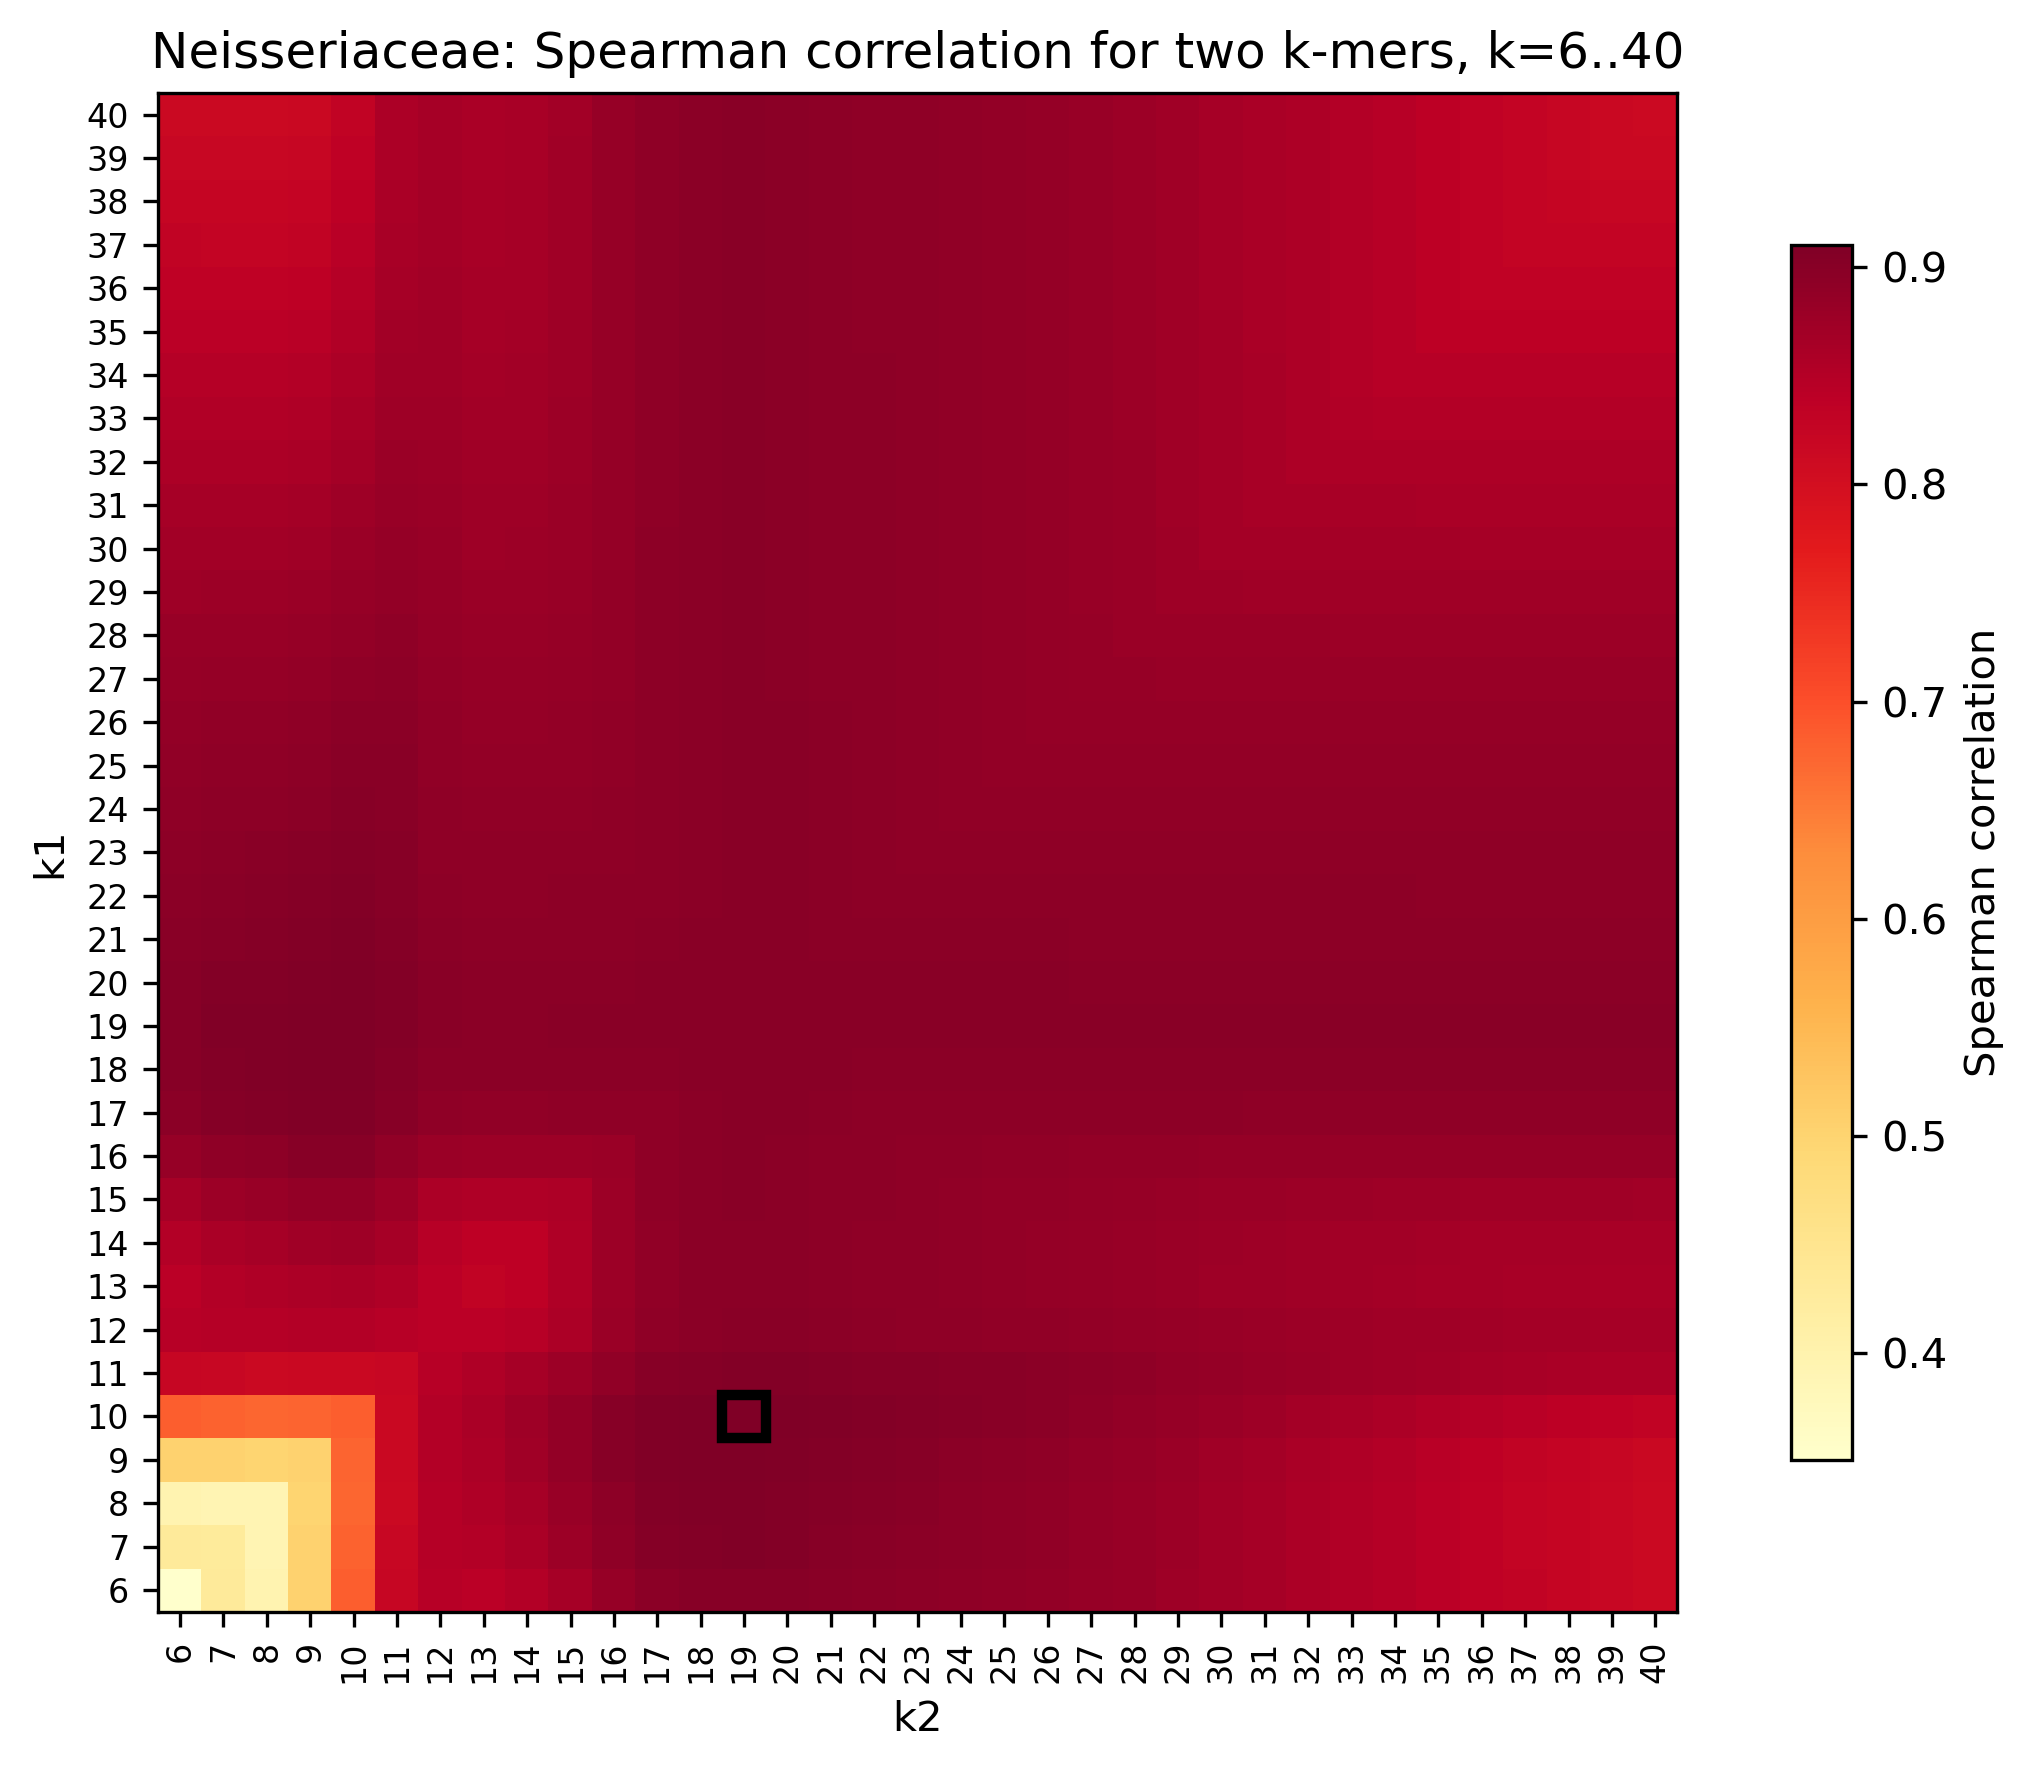

In [30]:
# Run full grid search
for name, merged_df in datasets:
    print(name)
    results_matrix, min_val, k1_min, k2_min, w_min, min_val = run_full_grid_corr(merged_df, k_low=6, k_high=40, w_low=0.05)
    results_matrix = np.abs(results_matrix)
    plot_2d_heatmap_from_results_matrix(name, results_matrix, k_low=6, k_high=40)
    print()


#### Scratch

##### One and two k-mers, fixing the best k-mer with and without weights


In [ ]:
#
## Best single-k
#def initial_corr(merged_df, iteration=0, k_low=5, k_high=32):
#    ''' Find best single value k'''
#    results_matrix = np.zeros((k_high - k_low + 1, 3 + iteration))
#    for i, k in enumerate(range(k_low, k_high + 1)):
#        k_rank = merged_df[f'k{k}_distance'].rank()
#        corr, pval = spearmanr(k_rank, merged_df['tree_distance'])
#        results_matrix[i, :] = [k, corr, pval]
#    min_idx = np.nanargmin(results_matrix[:,-2])
#    return results_matrix, (int(results_matrix[min_idx][0]), *results_matrix[min_idx][1:3])
#
## Two k-mers, fixing best and scanning for additional 2nd
#def double_k_corr(merged_df, ks, results_matrix_prev, k_low=5, k_high=32):
#    ''' Fixed first k, iterate 2nd k'''
#    num_k = len(ks) + 1
#    k_fixed_ith = ks[0]
#    results_matrix = np.zeros((k_high - k_low + 1, 2 + num_k))
#    k_fixed_rank = merged_df[f'k{k_fixed_ith}_distance'].rank()
#    nan_rows = np.unique(np.argwhere(np.isnan(results_matrix_prev))[:,0])
#    nan_ks = set(map(int, results_matrix_prev[nan_rows][:,0]))
#    for i, k in enumerate(range(k_low, k_high + 1)):
#        k_rank = merged_df[f'k{k}_distance'].rank()
#        if k in nan_ks:  # skip nan ks
#            results_matrix[i, :] = [k_fixed_ith, k, np.nan, np.nan]
#        else:
#            avg_rank = (k_fixed_rank + k_rank) / 2    # average the ranks
#            corr, pval = calc_corr(avg_rank, merged_df['tree_distance'], prnt=False)
#            # results_matrix[i, :] = [int(k_fixed_ith), int(k), corr, pval]
#            results_matrix[i, :] = [k_fixed_ith, k, corr, pval]
#    min_idx = np.nanargmin(results_matrix[:,-2])
#    return results_matrix, results_matrix[min_idx]
#
## Two k-mers, fixing best and scanning for additional 2nd with weight
#def double_k_corr_weighted(merged_df, ks, w_low=0, w_high=1, w_step=0.05):
#    ''' Fixed first k, weight 2nd k. '''
#    ws = np.arange(w_low, w_high, w_step)
#    num_k = len(ks) + 1
#    k1 = ks[0]
#    k2 = ks[1]
#    results_matrix = np.zeros((len(ws), 2 + num_k))
#    k1_rank = merged_df[f'k{k1}_distance'].rank()
#    k2_rank = merged_df[f'k{k2}_distance'].rank()
#    for i, w in enumerate(ws):
#        avg_w_rank = w * k1_rank + (1 - w) * k2_rank   # weight the ranks by w and 1-w
#        corr, pval = calc_corr(avg_w_rank, merged_df['tree_distance'], prnt=False)
#        results_matrix[i, :] = [k1, k2, w, corr, pval]
#    min_idx = np.nanargmin(results_matrix[:,-2])
#    return results_matrix[min_idx]  # return results_matrix
#
#
#def run_iterative_search(merged_df):
#    ''' Run iterative search (fixing best k-mer), with and without weights  '''
#    results_matrix_init, (k, corr, pval) = initial_corr(merged_df, k_low=5, k_high=64)
#    print('single-k:', k, corr, pval)
#
#    # double k
#    ks = [k]
#    results_matrix_double, (k1, k2, corr, pval) = double_k_corr(merged_df, ks, results_matrix_init, k_low=5, k_high=64)
#    print('double-k:', int(k1), int(k2), corr, pval)
#
#    # double k, weighted
#    ks = list(map(int, [k1, k2]))
#    k1, k2, w, corr, pval = double_k_corr_weighted(merged_df, ks)
#    print('double-k, weighted', int(k1), int(k2), w, corr, pval)
#
#
## Run for all EvANI datasets
#for name, merged_df in datasets:
#    print(name)
#    run_iterative_search(merged_df)
#    print()

##### Fix best, grid search 2nd-k and weight


In [ ]:
## Grid search with fixed initial, best K; scan 2nd k-mer; with and without weights
#
#def initial_corr(merged_df, iteration=0, k_low=5, k_high=32):
#    ''' '''
#    results_matrix = np.zeros((k_high - k_low + 1, 3 + iteration))
#    for i, k in enumerate(range(k_low, k_high + 1)):
#        k_rank = merged_df[f'k{k}_distance'].rank()
#        corr, pval = spearmanr(k_rank, merged_df['tree_distance'])
#        results_matrix[i, :] = [k, corr, pval]
#    min_idx = np.nanargmin(results_matrix[:,-2])
#    return results_matrix, (int(results_matrix[min_idx][0]), *results_matrix[min_idx][1:3])
#
#
#def grid_kw_corr(merged_df, k_fixed, k_low=5, k_high=32, w_low=0, w_high=1, w_step=0.05):
#    ''' '''
#    ws = np.arange(w_low, w_high, w_step)
#    ks = list(range(k_low, k_high + 1))
#    num_ws = len(ws)
#    results_matrix = np.zeros((k_high - k_low + 1, num_ws))
#    k_fixed_rank = merged_df[f'k{k_fixed}_distance'].rank()
#
#    for i, k in enumerate(ks):
#        k_rank = merged_df[f'k{k}_distance'].rank()
#        for j, w in enumerate(ws):
#            avg_w_rank = w * k_fixed_rank + (1 - w) * k_rank   # weight the ranks by w and 1-w
#            corr, pval = spearmanr(avg_w_rank, merged_df['tree_distance'])
#            results_matrix[i, j] = corr
#    # min_idx = np.nanargmin(results_matrix[:,-2])
#    grid_results_df = pd.DataFrame(results_matrix, index=ks, columns=ws)
#    return grid_results_df
#
#
#################################################################################
#def run_grid_search(merged_df, k_low=5, k_high=32, w_low=0, w_high=1, w_step=0.05):
#    ''' adsf '''
#    results_matrix_init, (k, corr, pval) = initial_corr(merged_df)
#    print('Best k:', k, corr, pval)
#
#    # grid search, double k weighted
#    grid_results_df = grid_kw_corr(merged_df, k, k_low, k_high, w_low, w_high, w_step)
#    min_val = grid_results_df.min().min()
#    min_col = grid_results_df.min().idxmin()    # Column where min val is
#    min_row = grid_results_df[min_col].idxmin() # Row where min val is
#    # print('Min corr:', min_val, 'with k-mers', k, min_row, 'weighted', min_col  )
#    print(f"Fixed {k}; Grid 2nd-k {min_row} and weight {min_col} with corr: {min_val}")
#    return grid_results_df, min_val, k, min_row, min_col
#
#
## Grid search with fixed initial, best K; recording the base average weight
#for name, merged_df in datasets:
#    print(name)
#    grid_results_df, min_val, k, min_row, min_col = run_grid_search(merged_df, k_low=5, k_high=64, w_low=0, w_high=1, w_step=0.05)
#    col = 0.50
#    grid_results_df = grid_results_df.dropna(axis=1) # By default, dropna() drops any row containing one or more NaN values. If you want to drop columns, you must specify axis=1.
#    min_val = grid_results_df[col].min()
#    min_row = grid_results_df[col].idxmin()
#    print(f"Fixed {k}, search {min_row} (w=0.5) with corr: {min_val}")
#    print()
#

### Three k-mers

In [37]:
# paths to datasets
aquificota_grid_path    = '/scratch4/blangme2/sjhwang/ok_k_mer/data/aquificota/grid_search/aquificota_slurm_tensor.npy'
bacillales_grid_path    = '/scratch4/blangme2/sjhwang/ok_k_mer/data/bacillales/grid_search/bacillales_slurm_tensor.npy'
caldisericia_grid_path  = '/scratch4/blangme2/sjhwang/ok_k_mer/data/caldisericia/grid_search/caldisericia_slurm_tensor.npy'
chlamydia_grid_path     = '/scratch4/blangme2/sjhwang/ok_k_mer/data/chlamydiales/grid_search/chlamydiales_slurm_tensor.npy'
cyano_grid_path         = '/scratch4/blangme2/sjhwang/ok_k_mer/data/cyanobacteriales/grid_search/cyano_slurm_tensor.npy'
neisseriaceae_grid_path = '/scratch4/blangme2/sjhwang/ok_k_mer/data/neisseriaceae/grid_search/neisseriaceae_slurm_tensor.npy'

aquificota_grid    = np.load(aquificota_grid_path)
bacillales_grid    = np.load(bacillales_grid_path)
caldisericia_grid  = np.load(caldisericia_grid_path)
chlamydia_grid     = np.load(chlamydia_grid_path)
cyano_grid         = np.load(cyano_grid_path)
neisseriaceae_grid = np.load(neisseriaceae_grid_path)

# Take absolute value of all grids to ensure all values are positive
aquificota_grid    = -1 * aquificota_grid
bacillales_grid    = -1 * bacillales_grid
caldisericia_grid  = -1 * caldisericia_grid
chlamydia_grid     = -1 * chlamydia_grid
cyano_grid         = -1 * cyano_grid
neisseriaceae_grid = -1 * neisseriaceae_grid

datasets_with_k = [
    ("Aquificota", aquificota_grid, 20),
    ("Bacillales", bacillales_grid, 24),
    ("Caldisericia", caldisericia_grid, 20),
    ("Chlamydia", chlamydia_grid, 20),
    ("Cyano", cyano_grid, 20),
    ("Neisseriaceae", neisseriaceae_grid, 19),
]


In [45]:
def plot_3k_grid_corr_k(name, grid_df, k, s, k_low, k_high):
    """
    Plot one heatmap per k1 in [k−s, …, k+s] (each 35×35, k2 × k3);
    collapse weight dims by min Spearman (matches grid objective), then negate
    so stronger associations plot as larger positive values (for YlOrRd).
    Only show every other tick for the x and y axes.
    Tick labels use a smaller font.
    In each subplot, color the best (largest) cell red.
    Across all subplots, color the overall best cell black.
    """
    planes = grid_df.max(axis=(3, 4))  # (n_k1, 35, 35); flip sign so min ρ → positive
    n_k1_full = planes.shape[0]
    half = (n_k1_full - 1) // 2
    if s > half:
        raise ValueError(f"s={s} exceeds k1 half-width {half} in grid")
    planes = planes[half - s : half + s + 1]
    n_panels = planes.shape[0]
    fig_w = 24 * n_panels / 7
    fig, axes = plt.subplots(1, n_panels, figsize=(fig_w, 3.5), constrained_layout=True, squeeze=False)
    axes = np.ravel(axes)
    pfin = planes[np.isfinite(planes)]
    vmin, vmax = float(np.min(pfin)), float(np.max(pfin))

    # k1 titles aligned with sliced panels (length must equal n_panels)
    k_subplot_labels = [k - s + i for i in range(n_panels)]
    k_axis_labels = list(range(k_low, k_high + 1))

    # Only select every other tick for the axes
    n_labels = len(k_axis_labels)
    xtick_positions = [i for i in range(n_labels) if i % 2 == 0]  # every other tick
    ytick_positions = [i for i in range(n_labels) if i % 2 == 0]
    xtick_labels = [k_axis_labels[i] for i in xtick_positions]
    ytick_labels = [k_axis_labels[i] for i in ytick_positions]

    # Overall best cell across all planes (largest after negation)
    global_max = np.nanmax(planes)
    g_indices = np.where(planes == global_max)
    if len(g_indices[0]) > 0:
        global_best_subplot = int(g_indices[0][0])
        global_best_y = int(g_indices[1][0])
        global_best_x = int(g_indices[2][0])
    else:
        global_best_subplot = global_best_y = global_best_x = None

    im = None
    tick_label_fontsize = 8  # Make tick labels smaller
    for i, ax in enumerate(axes):
        data = planes[i]

        im = ax.imshow(data, aspect="equal", origin="lower", vmin=vmin, vmax=vmax, cmap="YlOrRd")  # color: min to max
        # im = ax.imshow(data, vmin=0, origin="lower", aspect="equal", cmap="YlOrRd")                # color: 0 to max


        ax.set_xlabel("k3")
        ax.set_ylabel("k2")
        ax.set_title(f"k1={k_subplot_labels[i]}")

        # Set x/y ticks and labels at every other tick, use smaller font
        ax.set_xticks(xtick_positions)
        ax.set_xticklabels(xtick_labels, fontsize=tick_label_fontsize)
        ax.set_yticks(ytick_positions)
        ax.set_yticklabels(ytick_labels, fontsize=tick_label_fontsize)

        # Highlight the best (largest) cell in the plane with a red rectangle or marker,
        # but only if there is at least one finite value.
        if np.any(np.isfinite(data)):
            max_val = np.nanmax(data)
            ys, xs = np.where(data == max_val)
            if len(ys) > 0:
                y, x = ys[0], xs[0]
                # If this cell is ALSO the global best, color it black. Otherwise, red.
                if i == global_best_subplot and y == global_best_y and x == global_best_x:
                    rect = plt.Rectangle((x - 0.5, y - 0.5), 1, 1,
                                        linewidth=2.5, edgecolor='#000000', facecolor='none')       # #00BFFF for blue
                    ax.add_patch(rect)
                # else:
                    # rect = plt.Rectangle((x - 0.5, y - 0.5), 1, 1,
                    #                     linewidth=2.5, edgecolor='red', facecolor='none')
                    # ax.add_patch(rect)

    # fig.suptitle(f"{name}: Spearman correlation for three k-mers, k={k_low}..{k_high}", fontsize=18)
    fig.suptitle(f"{name}: Spearman correlation for three k-mers, k={k_low}..{k_high}")

    # Move the colorbar (legend) more to the left by reducing the pad
    # You can use the ax argument as a list, but use the 'fraction' and 'pad' kwargs to move it left
    cbar = fig.colorbar(im, ax=axes.ravel().tolist(), shrink=0.85, location="right", label="Spearman corr", pad=0.02)
    plt.show()


Aquificota 20


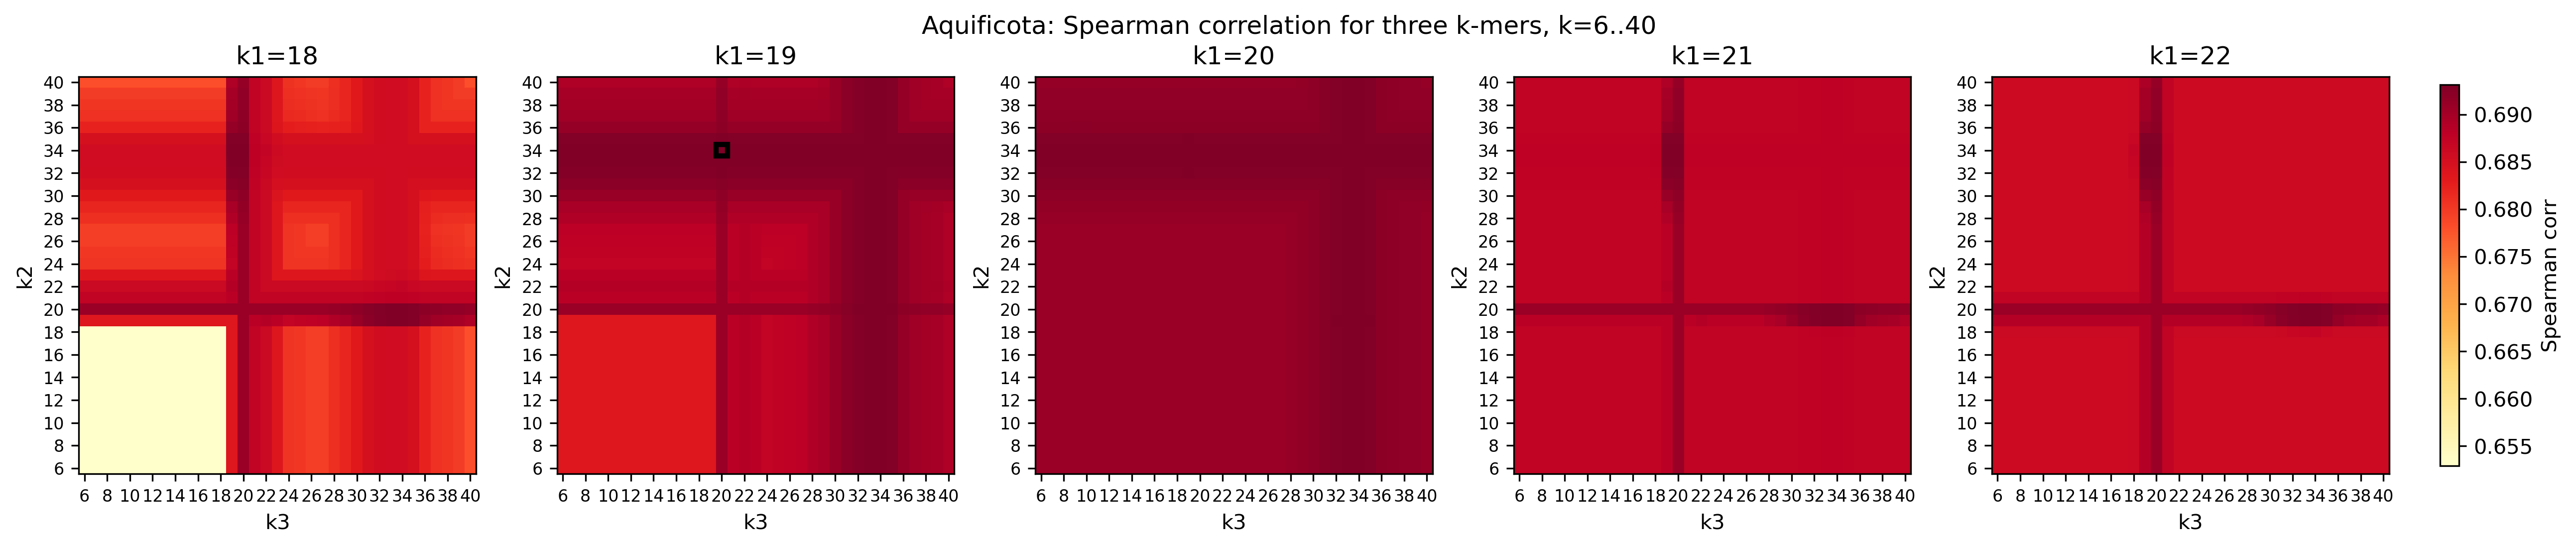


Bacillales 24


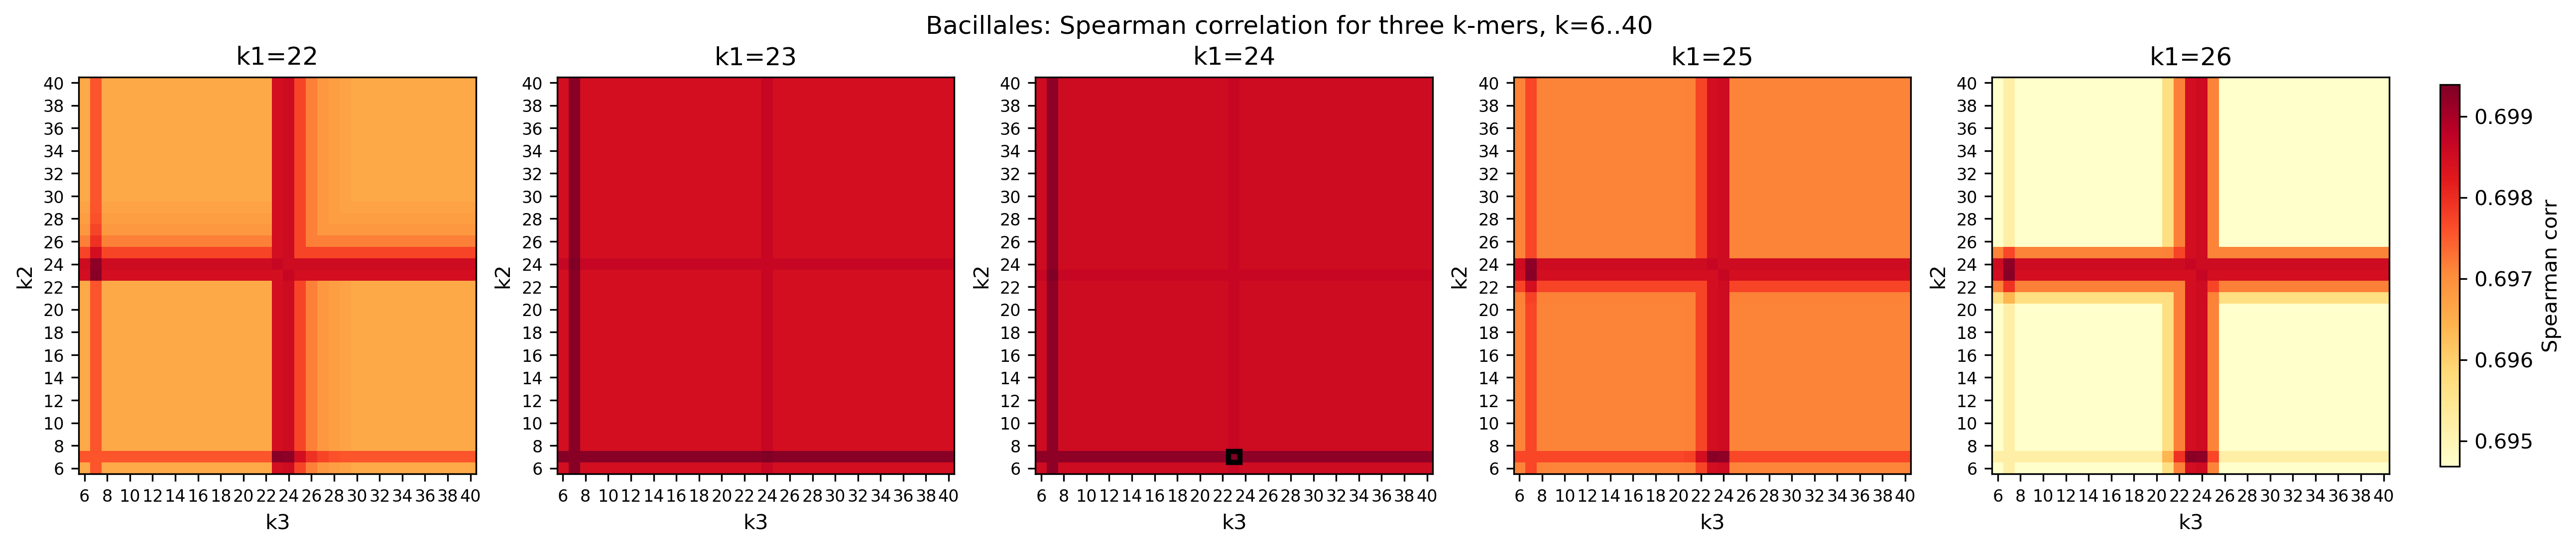


Caldisericia 20


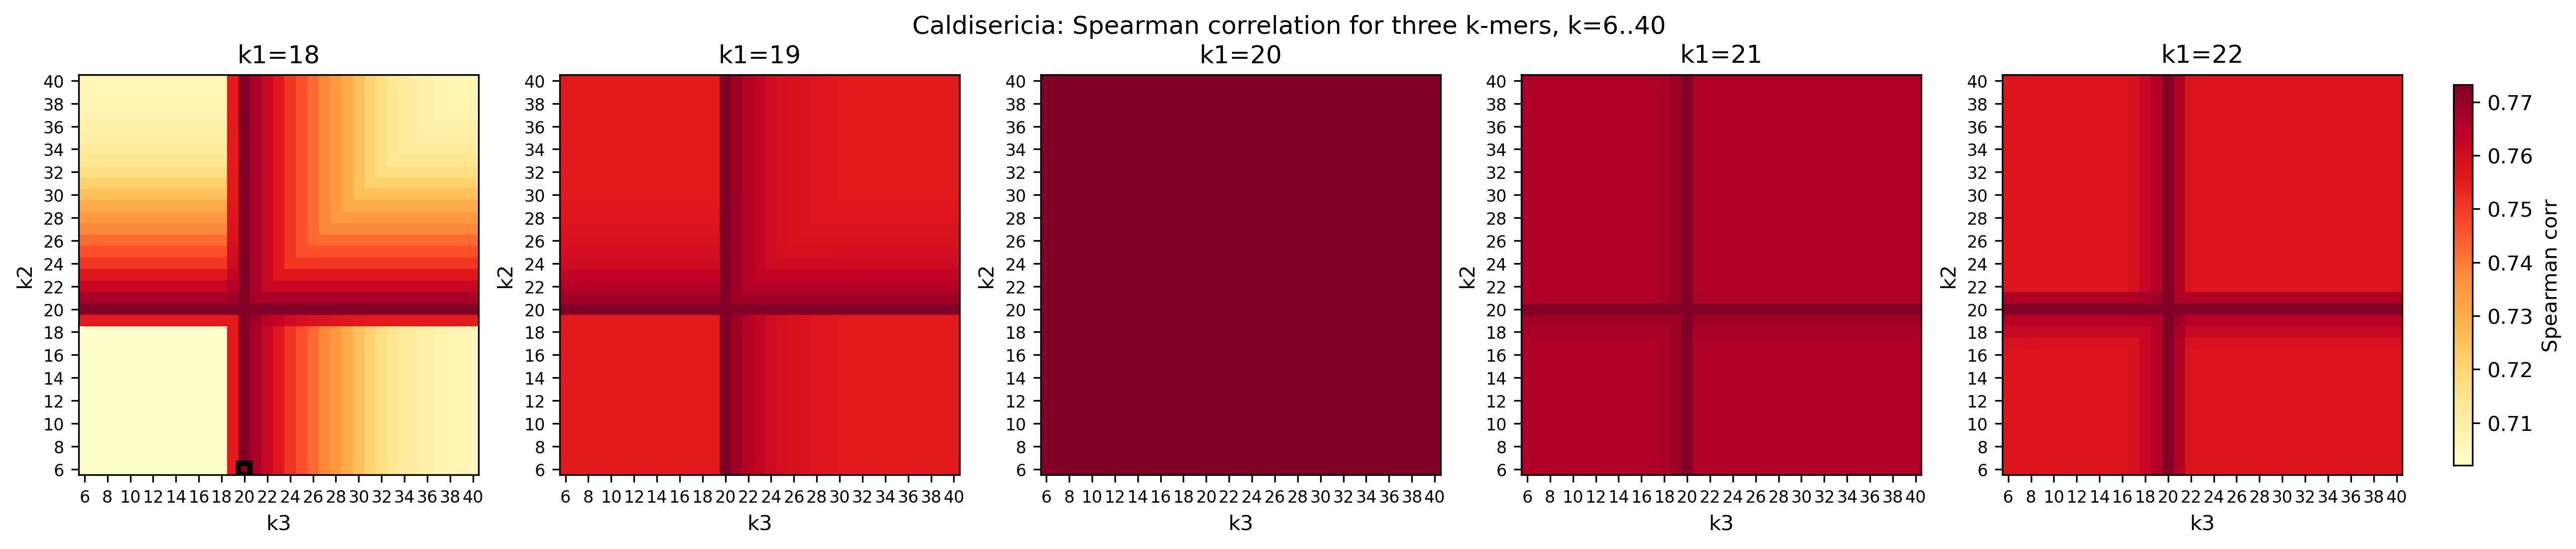


Chlamydia 20


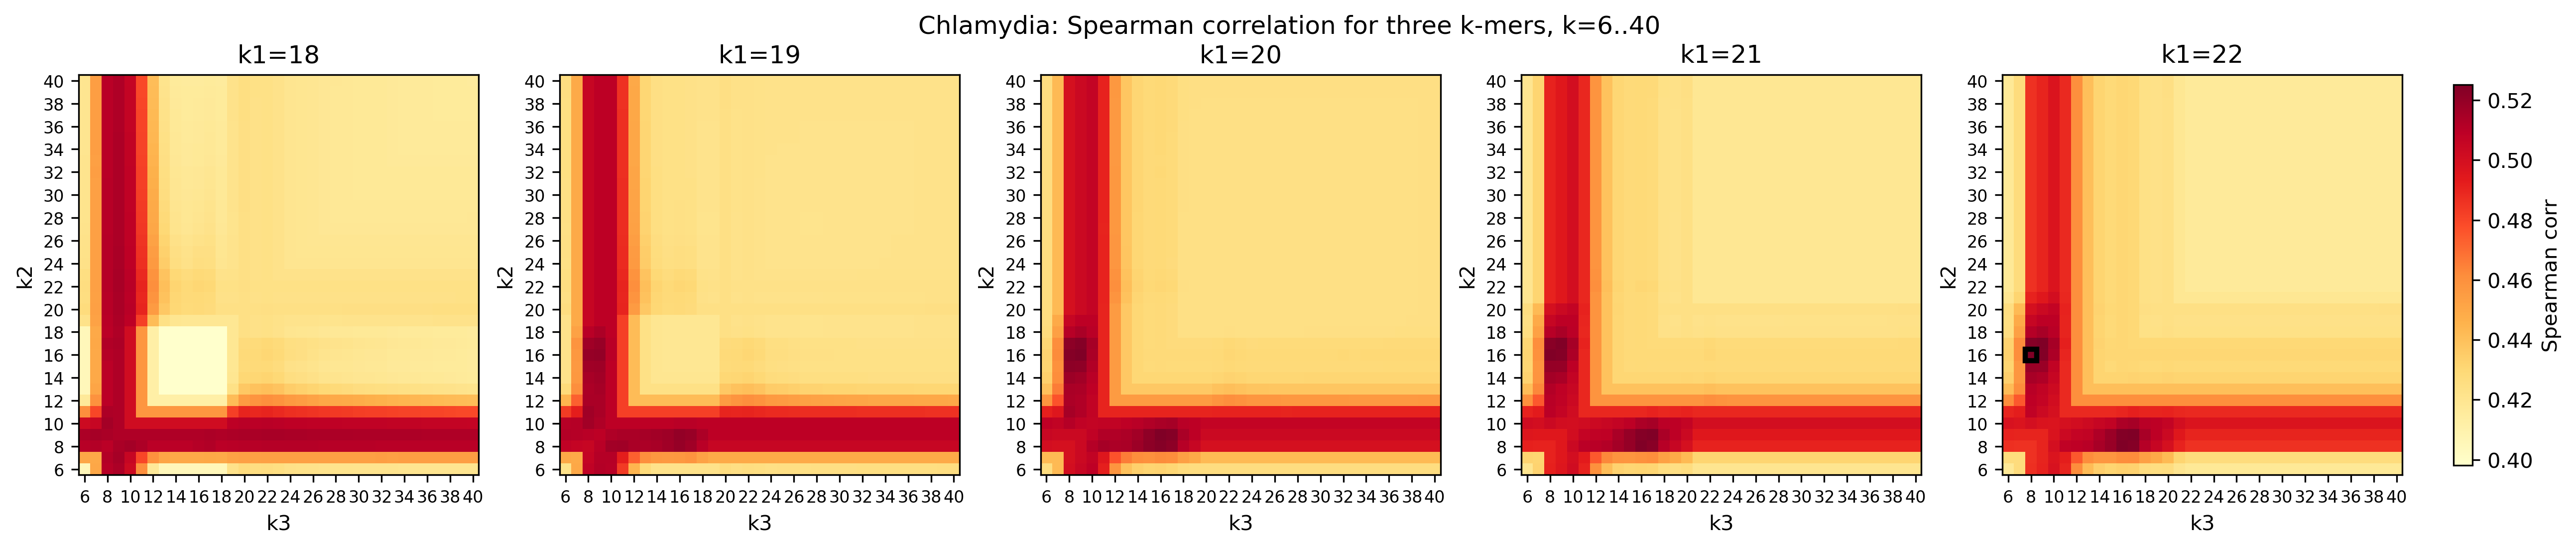


Cyano 20


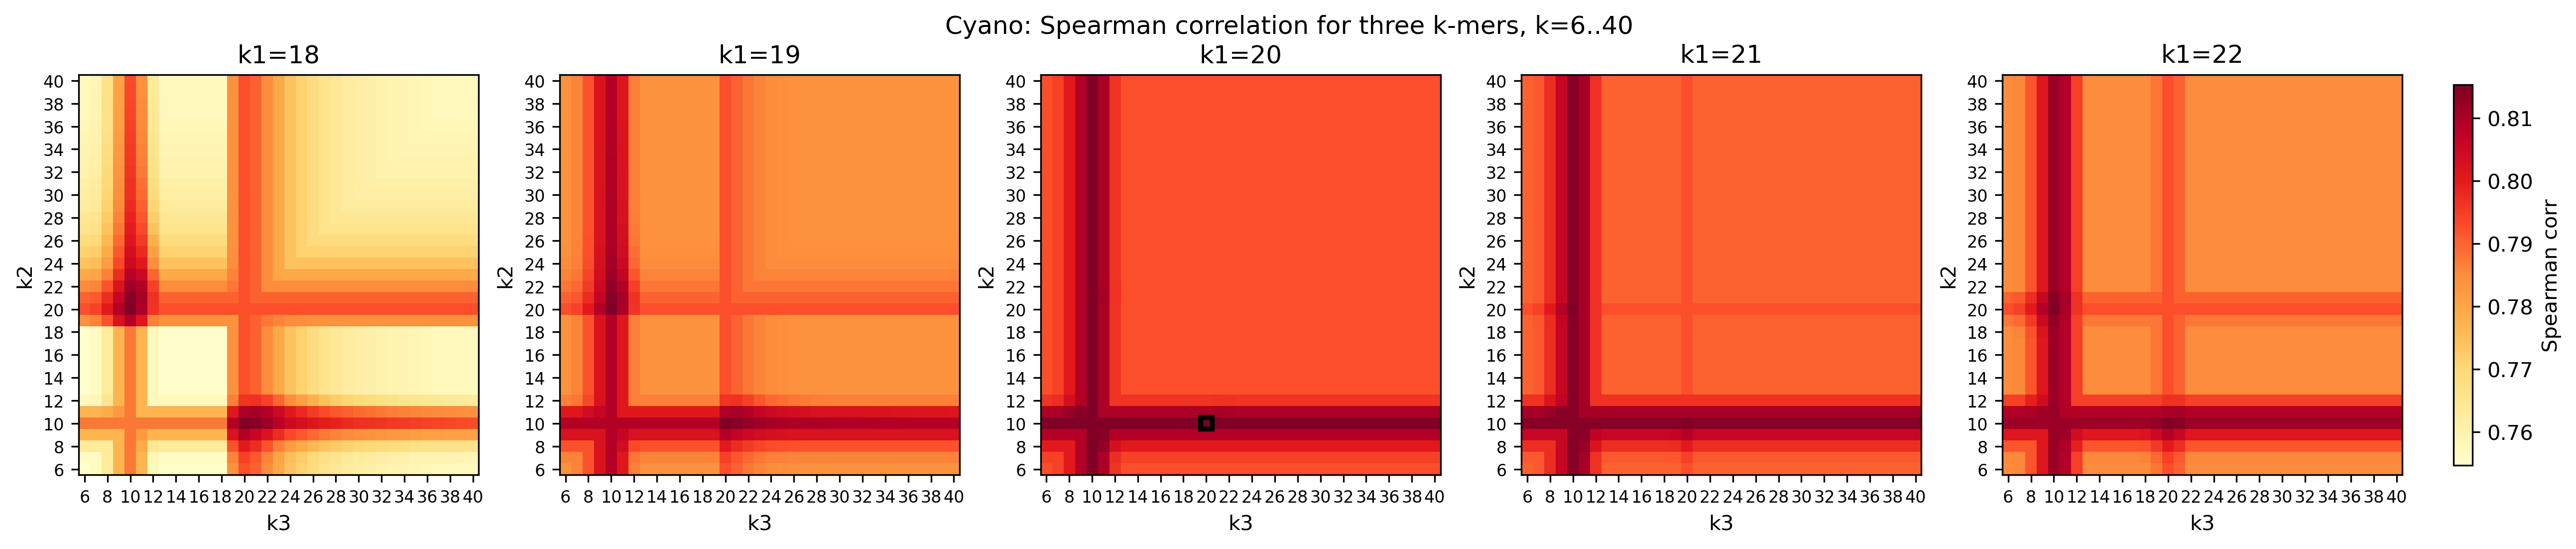


Neisseriaceae 19


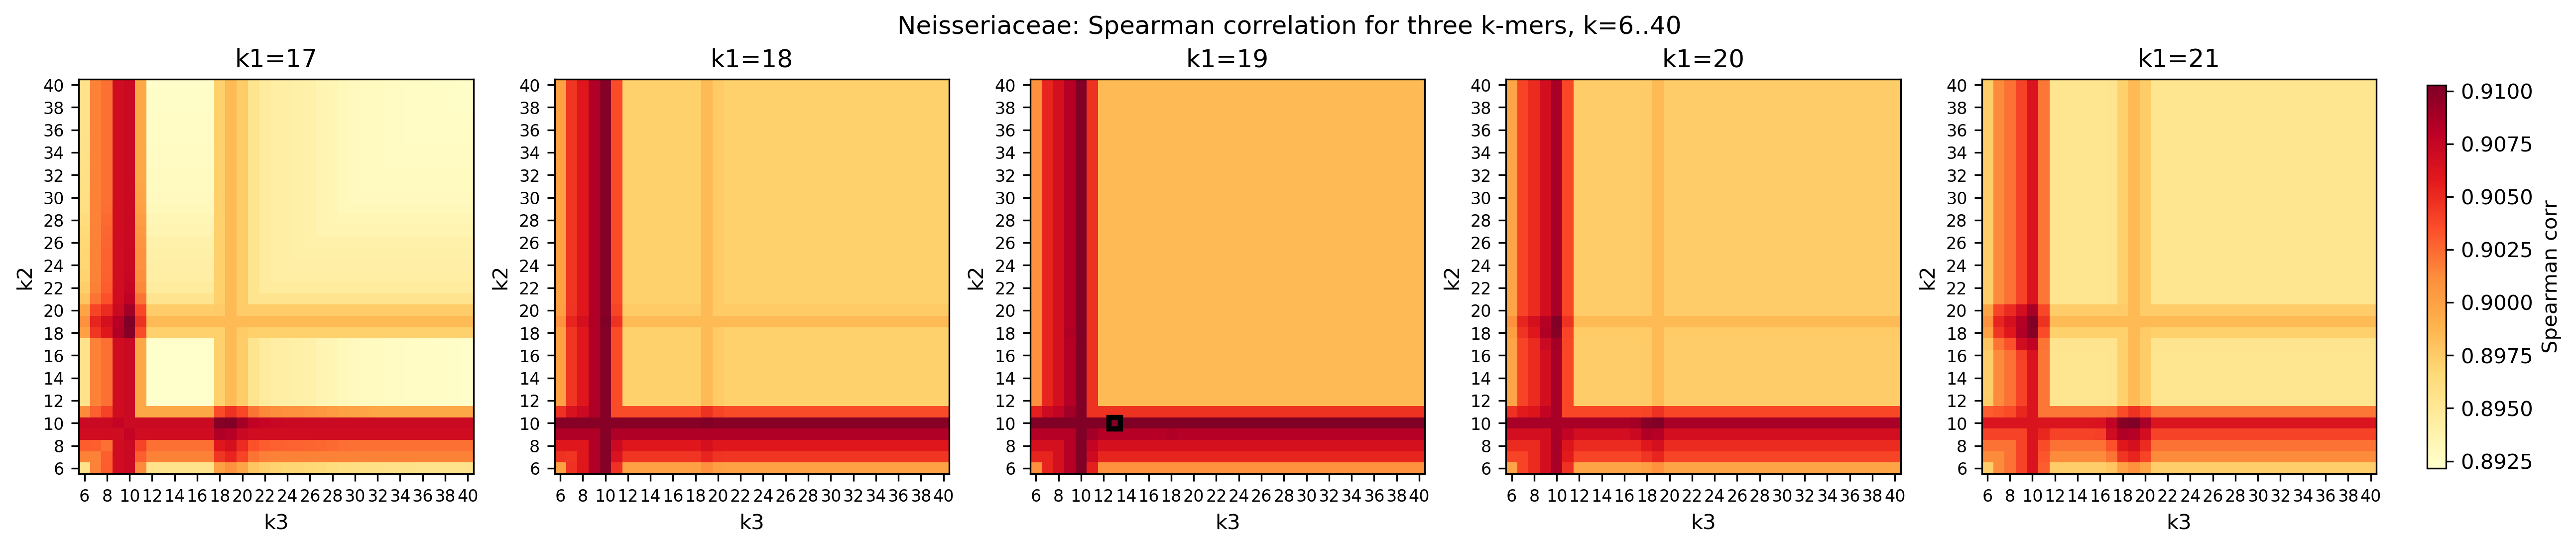

In [46]:
# Run across all datasets

s = 2 # s = 3
k_low = 6
k_high = 40

# Run 3-kmer grid search
for name, grid_df, k_best in datasets_with_k:
    print(name, k_best)
    results = plot_3k_grid_corr_k(name, grid_df, k_best, s=s, k_low=k_low, k_high=k_high)
    print()


## Full grid search: 3 k-mers, 2 weights

### full grid, serial

In [ ]:
def run_full_3k_grid_corr(merged_df, k_low=5, k_high=32, w1_low=0, w1_high=1, w2_low=0, w2_high=1, w_step=0.05):
    """
    SERIAL

    Full grid search: pick 3 ks (k1, k2, k3), and two weights (w1, w2).
    The 3-way weighted rank: w1*k1_rank + w2*k2_rank + (1-w1-w2)*k3_rank.
    w1 in (w1_low, w1_high), w2 in (w2_low, w2_high), with w1+w2 <= 1, all steps in w_step.
    """
    ws = np.round(np.arange(0, 1 + w_step, w_step), 3)
    ks = list(range(k_low, k_high + 1))
    num_ks = len(ks)
    num_ws = len(ws)

    # results_matrix shape: (k1_idx, k2_idx, k3_idx, w1_idx, w2_idx)
    results_matrix = np.full((num_ks, num_ks, num_ks, num_ws, num_ws), np.nan)

    for k1_idx, k1 in enumerate(ks):
        k1_rank = merged_df[f'k{k1}_distance'].rank()
        for k2_idx, k2 in enumerate(ks):
            k2_rank = merged_df[f'k{k2}_distance'].rank()
            for k3_idx, k3 in enumerate(ks):
                k3_rank = merged_df[f'k{k3}_distance'].rank()
                for w1_idx, w1 in enumerate(ws):
                    for w2_idx, w2 in enumerate(ws):
                        # Make sure w1 + w2 <= 1 (and >=0)
                        if 0 <= w1 <= 1 and 0 <= w2 <= 1 and (w1 + w2) <= 1:
                            w3 = 1 - w1 - w2
                            avg_rank = w1 * k1_rank + w2 * k2_rank + w3 * k3_rank
                            corr, pval = spearmanr(avg_rank, merged_df['tree_distance'])
                            results_matrix[k1_idx, k2_idx, k3_idx, w1_idx, w2_idx] = corr

    results_matrix = np.nan_to_num(results_matrix, nan=np.inf)  # So nan are not considered as minima (use np.inf)
    min_val = np.min(results_matrix)
    min_idx = np.unravel_index(np.argmin(results_matrix), results_matrix.shape)
    k1_min, k2_min, k3_min = ks[min_idx[0]], ks[min_idx[1]], ks[min_idx[2]]
    w1_min, w2_min = ws[min_idx[3]], ws[min_idx[4]]
    w3_min = 1 - w1_min - w2_min
    print(f"Grid Ks: ({k1_min}, {k2_min}, {k3_min}) with weights (w1={w1_min}, w2={w2_min}, w3={w3_min}); corr: {min_val}")
    return results_matrix, min_val, k1_min, k2_min, k3_min, w1_min, w2_min, w3_min, min_val


In [ ]:
merged_df = caldisericia_merged_df
results = run_full_3k_grid_corr(merged_df, k_low=6, k_high=32, w1_low=0, w1_high=1, w2_low=0, w2_high=1, w_step=0.1)
results

Grid Ks: (6, 6, 20) with weights (w1=0.0, w2=0.0, w3=1.0); corr: -0.7732939230754757


(array([[[[[-3.08776241e-02, -3.08776241e-02, -3.08776241e-02, ...,
            -3.08776241e-02, -3.08776241e-02, -3.08776241e-02],
           [-3.08776241e-02, -3.08776241e-02, -3.08776241e-02, ...,
            -3.08776241e-02, -3.08776241e-02,             inf],
           [-3.08776241e-02, -3.08776241e-02, -3.08776241e-02, ...,
            -3.08776241e-02,             inf,             inf],
           ...,
           [-3.08776241e-02, -3.08776241e-02, -3.08776241e-02, ...,
                        inf,             inf,             inf],
           [-3.08776241e-02, -3.08776241e-02,             inf, ...,
                        inf,             inf,             inf],
           [-3.08776241e-02,             inf,             inf, ...,
                        inf,             inf,             inf]],
 
          [[ 7.79391351e-02,  7.71143653e-02,  7.65999998e-02, ...,
             7.69836938e-02,  7.69836938e-02, -3.08776241e-02],
           [ 7.71143653e-02,  7.65999998e-02,  7.76874473

In [ ]:
# Run 3-kmer grid search
for name, merged_df in datasets:
    print(name)
    results = run_full_3k_grid_corr(merged_df, k_low=6, k_high=32, w1_low=0, w1_high=1, w2_low=0, w2_high=1, w_step=0.1)
    print()


### semi-fixed, grid

In [ ]:

def run_full_3k_grid_corr_k_main(merged_df, k1_main, s=2, k_low=5, k_high=32, w1_low=0, w1_high=1, w2_low=0, w2_high=1, w_step=0.05):
    """
    SEMI-FIXED GRID search

    Limited grid search: user supplies k1_main, and ks are restricted to ±s of that k1 (optionally clipped by k_low/k_high).

    Full grid search: pick 3 ks (k1, k2, k3), and two weights (w1, w2).
    The 3-way weighted rank: w1*k1_rank + w2*k2_rank + (1-w1-w2)*k3_rank.
    w1 in (w1_low, w1_high), w2 in (w2_low, w2_high), with w1+w2 <= 1, all steps in w_step.

    k1_main : int
        The main k-mer length around which to search.
    s : int
        The radius of the window for k-mer search (default 2).
    """
    ws = np.round(np.arange(0, 1 + w_step, w_step), 3)
    ks_main = [k for k in range(max(k_low, k1_main - s), min(k_high, k1_main + s)+1)]
    ks = list(range(k_low, k_high + 1))
    num_ks_main = len(ks_main)
    num_ks = len(ks)
    num_ws = len(ws)
    # results_matrix shape: (k1_idx, k2_idx, k3_idx, w1_idx, w2_idx)
    results_matrix = np.full((num_ks_main, num_ks, num_ks, num_ws, num_ws), np.nan)

    for k1_idx, k1 in enumerate(ks_main):
        k1_rank = merged_df[f'k{k1}_distance'].rank()
        for k2_idx, k2 in enumerate(ks):
            k2_rank = merged_df[f'k{k2}_distance'].rank()
            for k3_idx, k3 in enumerate(ks):
                k3_rank = merged_df[f'k{k3}_distance'].rank()
                for w1_idx, w1 in enumerate(ws):
                    for w2_idx, w2 in enumerate(ws):
                        # Make sure w1 + w2 <= 1 (and >=0)
                        if 0 <= w1 <= 1 and 0 <= w2 <= 1 and (w1 + w2) <= 1:
                            w3 = 1 - w1 - w2
                            avg_rank = w1 * k1_rank + w2 * k2_rank + w3 * k3_rank
                            corr, pval = spearmanr(avg_rank, merged_df['tree_distance'])
                            results_matrix[k1_idx, k2_idx, k3_idx, w1_idx, w2_idx] = corr

    results_matrix = np.nan_to_num(results_matrix, nan=np.inf)  # So nan are not considered as minima (use np.inf)
    min_val = np.min(results_matrix)
    min_idx = np.unravel_index(np.argmin(results_matrix), results_matrix.shape)
    k1_min, k2_min, k3_min = ks[min_idx[0]], ks[min_idx[1]], ks[min_idx[2]]
    w1_min, w2_min = ws[min_idx[3]], ws[min_idx[4]]
    w3_min = 1 - w1_min - w2_min
    print(f"Grid Ks: ({k1_min}, {k2_min}, {k3_min}) with weights (w1={w1_min}, w2={w2_min}, w3={w3_min}); corr: {min_val}")
    return results_matrix, min_val, k1_min, k2_min, k3_min, w1_min, w2_min, w3_min, min_val


In [31]:
# test single (cald) dataset

k_main = 20
s = 3
merged_df = caldisericia_merged_df
results = run_full_3k_grid_corr_k_main(merged_df, k_main, s=s, k_low=6, k_high=64, w_step=0.1)

Grid Ks: (6, 6, 20) with weights (w1=0.0, w2=0.0, w3=1.0); corr: -0.7732939230754757


In [32]:
# Run across all datasets

# Prepare a list of all available merged_dfs and their names
#   manually put in best kl
datasets_with_k = [
    ("Aquificota", aquificota_merged_df, 20),
    ("Bacillales", bacillales_merged_df, 24),
    ("Caldisericia", caldisericia_merged_df, 20),
    ("Chlamydia", chlamydia_merged_df, 20),
    ("Cyano", cyano_merged_df, 20),
    ("Neisseriaceae", neisseriaceae_merged_df, 19),
]


s = 3

# Run 3-kmer grid search
for name, merged_df, k_main in datasets_with_k:
    print(name, k_main)
    results = run_full_3k_grid_corr_k_main(merged_df, k_main, s=s, k_low=6, k_high=40, w_step=0.1)
    print()

Aquificota 20


KeyboardInterrupt: 

### semi-fixed, grid, parallel by multiprocessing
(Using the Parallel was not any faster)

In [21]:

def _single_3k_grid_spearman(args):
    """
    Helper for parallel 3-k grid search.
    """
    merged_df, ks_main, ks, ws, k1_idx, k2_idx, k3_idx, w1_idx, w2_idx = args
    k1 = ks_main[k1_idx]
    k2 = ks[k2_idx]
    k3 = ks[k3_idx]
    w1 = ws[w1_idx]
    w2 = ws[w2_idx]
    if not (0 <= w1 <= 1 and 0 <= w2 <= 1 and (w1 + w2) <= 1):
        return (k1_idx, k2_idx, k3_idx, w1_idx, w2_idx, np.nan)
    w3 = 1 - w1 - w2
    k1_rank = merged_df[f'k{k1}_distance'].rank()
    k2_rank = merged_df[f'k{k2}_distance'].rank()
    k3_rank = merged_df[f'k{k3}_distance'].rank()
    avg_rank = w1 * k1_rank + w2 * k2_rank + w3 * k3_rank
    corr, pval = spearmanr(avg_rank, merged_df['tree_distance'])
    return (k1_idx, k2_idx, k3_idx, w1_idx, w2_idx, corr)

def _pool_initializer_limit_native_threads():
    """
    Pin each worker process to one CPU core to avoid core oversubscription.
    """
    try:
        worker_identity = mp.current_process()._identity
        worker_idx = (worker_identity[0] - 1) if worker_identity else 0
        available_cpus = sorted(os.sched_getaffinity(0))
        if available_cpus:
            target_cpu = available_cpus[worker_idx % len(available_cpus)]
            os.sched_setaffinity(0, {target_cpu})
    except Exception:
        pass

def run_full_3k_grid_corr_k_main_parallel(
    merged_df, k1_main, s=2, k_low=5, k_high=32, w1_low=0, w1_high=1, w2_low=0, w2_high=1, w_step=0.05, num_threads=None
):
    """
    Limited grid search: user supplies k1_main, and ks are restricted to ±s of that k1 (optionally clipped by k_low/k_high).

    Full grid search: pick 3 ks (k1, k2, k3), and two weights (w1, w2).
    The 3-way weighted rank: w1*k1_rank + w2*k2_rank + (1-w1-w2)*k3_rank.
    w1 in (w1_low, w1_high), w2 in (w2_low, w2_high), with w1+w2 <= 1, all steps in w_step.

    k1_main : int
        The main k-mer length around which to search.
    s : int
        The radius of the window for k-mer search (default 2).
    num_threads : int or None
        Number of worker processes to use. If None, uses all available CPUs.
    """
    ws = np.round(np.arange(0, 1 + w_step, w_step), 3)
    ks_main = [k for k in range(max(k_low, k1_main - s), min(k_high, k1_main + s)+1)]
    ks = list(range(k_low, k_high + 1))
    num_ks_main = len(ks_main)
    num_ks = len(ks)
    num_ws = len(ws)

    results_matrix = np.full((num_ks_main, num_ks, num_ks, num_ws, num_ws), np.nan)

    # Prepare argument list for multiprocessing
    args = []
    for k1_idx in range(num_ks_main):
        for k2_idx in range(num_ks):
            for k3_idx in range(num_ks):
                for w1_idx in range(num_ws):
                    for w2_idx in range(num_ws):
                        args.append((merged_df, ks_main, ks, ws, k1_idx, k2_idx, k3_idx, w1_idx, w2_idx))

    # Respect requested worker count and prevent native oversubscription.
    num_workers = mp.cpu_count() if num_threads is None else int(num_threads)
    num_workers = max(1, num_workers)
    with mp.Pool(processes=num_workers, initializer=_pool_initializer_limit_native_threads) as pool:
        results = pool.map(_single_3k_grid_spearman, args)

    for k1_idx, k2_idx, k3_idx, w1_idx, w2_idx, corr in results:
        results_matrix[k1_idx, k2_idx, k3_idx, w1_idx, w2_idx] = corr

    results_matrix = np.nan_to_num(results_matrix, nan=np.inf)
    min_val = np.min(results_matrix)
    min_idx = np.unravel_index(np.argmin(results_matrix), results_matrix.shape)
    k1_min = ks_main[min_idx[0]]
    k2_min = ks[min_idx[1]]
    k3_min = ks[min_idx[2]]
    w1_min = ws[min_idx[3]]
    w2_min = ws[min_idx[4]]
    w3_min = 1 - w1_min - w2_min
    print(f"Grid Ks: ({k1_min}, {k2_min}, {k3_min}) with weights (w1={w1_min}, w2={w2_min}, w3={w3_min}); corr: {min_val}")
    return results_matrix, min_val, k1_min, k2_min, k3_min, w1_min, w2_min, w3_min, min_val

In [ ]:
# trying to get this to run with only X threads... seems to always run with all the available cores
# !export MKL_NUM_THREADS=16
# !export NUMEXPR_NUM_THREADS=16
# !export OMP_NUM_THREADS=16

In [22]:
# Run across all datasets

# Prepare a list of all available merged_dfs and their names
#   manually put in best kl
datasets_with_k = [
    ("Aquificota", aquificota_merged_df, 20),
    ("Bacillales", bacillales_merged_df, 24),
    ("Caldisericia", caldisericia_merged_df, 20),
    ("Chlamydia", chlamydia_merged_df, 20),
    ("Cyano", cyano_merged_df, 20),
    ("Neisseriaceae", neisseriaceae_merged_df, 19),
]


s = 3
threads = 16

# Run 3-kmer grid search
for name, merged_df, k_main in datasets_with_k:
    print(name, k_main)
    results = run_full_3k_grid_corr_k_main_parallel(merged_df, k_main, s=s, k_low=6, k_high=40, w_step=0.1, num_threads=threads)
    print()

Aquificota 20
Grid Ks: (19, 34, 20) with weights (w1=0.5, w2=0.3, w3=0.2); corr: -0.693142406997179

Bacillales 24
Grid Ks: (24, 7, 23) with weights (w1=0.4, w2=0.2, w3=0.39999999999999997); corr: -0.6993896120999316

Caldisericia 20
Grid Ks: (17, 6, 20) with weights (w1=0.0, w2=0.0, w3=1.0); corr: -0.7732939230754757

Chlamydia 20
Grid Ks: (22, 16, 8) with weights (w1=0.3, w2=0.3, w3=0.39999999999999997); corr: -0.5252762634393853

Cyano 20
Grid Ks: (20, 10, 20) with weights (w1=0.7, w2=0.3, w3=5.551115123125783e-17); corr: -0.8153414039716017

Neisseriaceae 19
Grid Ks: (19, 10, 13) with weights (w1=0.8, w2=0.2, w3=-5.551115123125783e-17); corr: -0.9102824200452518



### Plot semi-fixed, grid scatter plots
k-sub-plots for each dataset, each subplot scatter plot of the k3 vs k2 values colored by correlation.

In [58]:
# paths to datasets

aquificota_grid_path    = '/scratch4/blangme2/sjhwang/ok_k_mer/data/aquificota/grid_search/aquificota_slurm_tensor.npy'
bacillales_grid_path    = '/scratch4/blangme2/sjhwang/ok_k_mer/data/bacillales/grid_search/bacillales_slurm_tensor.npy'
caldisericia_grid_path  = '/scratch4/blangme2/sjhwang/ok_k_mer/data/caldisericia/grid_search/caldisericia_slurm_tensor.npy'
chlamydia_grid_path     = '/scratch4/blangme2/sjhwang/ok_k_mer/data/chlamydiales/grid_search/chlamydiales_slurm_tensor.npy'
cyano_grid_path         = '/scratch4/blangme2/sjhwang/ok_k_mer/data/cyanobacteriales/grid_search/cyano_slurm_tensor.npy'
neisseriaceae_grid_path = '/scratch4/blangme2/sjhwang/ok_k_mer/data/neisseriaceae/grid_search/neisseriaceae_slurm_tensor.npy'

aquificota_grid    = np.load(aquificota_grid_path)
bacillales_grid    = np.load(bacillales_grid_path)
caldisericia_grid  = np.load(caldisericia_grid_path)
chlamydia_grid     = np.load(chlamydia_grid_path)
cyano_grid         = np.load(cyano_grid_path)
neisseriaceae_grid = np.load(neisseriaceae_grid_path)

# Take absolute value of all grids to ensure all values are positive
aquificota_grid    = np.abs(aquificota_grid)
bacillales_grid    = np.abs(bacillales_grid)
caldisericia_grid  = np.abs(caldisericia_grid)
chlamydia_grid     = np.abs(chlamydia_grid)
cyano_grid         = np.abs(cyano_grid)
neisseriaceae_grid = np.abs(neisseriaceae_grid)



In [ ]:
# aquificota_grid    = np.abs(aquificota_grid)
# bacillales_grid    = np.abs(bacillales_grid)
# caldisericia_grid  = np.abs(caldisericia_grid)
# chlamydia_grid     = np.abs(chlamydia_grid)
# cyano_grid         = np.abs(cyano_grid)
# neisseriaceae_grid = np.abs(neisseriaceae_grid)

In [48]:
def plot_grid_heatmaps_no_annot(name, grid_df, k, s, k_low, k_high):
    """
    Plot 7 heatmaps (one per k1 slice), each 35×35 (k2 × k3);
    collapse weight dims by min Spearman (matches grid objective).
    Only show every other tick for the x and y axes.
    Makes x and y tick labels smaller for better visualization.
    """
    planes = grid_df.min(axis=(3, 4))  # (7, 35, 35)
    fig, axes = plt.subplots(1, 7, figsize=(24, 3.5), constrained_layout=True)
    pfin = planes[np.isfinite(planes)]
    vmin, vmax = float(np.min(pfin)), float(np.max(pfin))

    # Make k_labels for k1 axis: [k-s, ..., k, ..., k+s]
    k_subplot_labels = [k + offset for offset in range(-s, s + 1)]
    k_axis_labels = list(range(k_low, k_high + 1))

    # Only select every other label for ticks
    n_labels = len(k_axis_labels)
    xticks = list(range(n_labels))
    yticks = list(range(n_labels))
    xtick_skip = 2
    ytick_skip = 2

    xtick_positions = xticks[::xtick_skip]
    xtick_labels = [k_axis_labels[i] for i in xtick_positions]
    ytick_positions = yticks[::ytick_skip]
    ytick_labels = [k_axis_labels[i] for i in ytick_positions]

    im = None
    tick_label_fontsize = 8  # Make tick labels smaller
    for i, ax in enumerate(axes):
        im = ax.imshow(planes[i], aspect="equal", origin="lower", vmin=vmin, vmax=vmax, cmap="viridis_r")
        # im = ax.imshow(planes[i], aspect="equal", origin="lower", vmin=0, vmax=1, cmap="YlOrRd")
        # im = ax.imshow(planes[i], aspect="auto", origin="lower", vmin=0, vmax=1, cmap="YlOrRd")
        # im = ax.imshow(heatmap, aspect="auto", origin="lower", cmap="YlOrRd", vmin=0, vmax=1)

        ax.set_xlabel("k3")
        ax.set_ylabel("k2")
        ax.set_title(f"k1={k_subplot_labels[i]}")

        # Set ticks and labels for axes, but plot every other one, with smaller fonts
        ax.set_xticks(xtick_positions)
        ax.set_xticklabels(xtick_labels, fontsize=tick_label_fontsize)
        ax.set_yticks(ytick_positions)
        ax.set_yticklabels(ytick_labels, fontsize=tick_label_fontsize)

    fig.suptitle(f"{name}: k2×k3 correlation (min over w1,w2); center k≈{k}")
    fig.colorbar(im, ax=axes.ravel().tolist(), shrink=0.85, location="right", label="Spearman corr")
    plt.show()

# Usage example:
# plot_grid_heatmaps(name, grid_df, k, s, k_low, k_high)

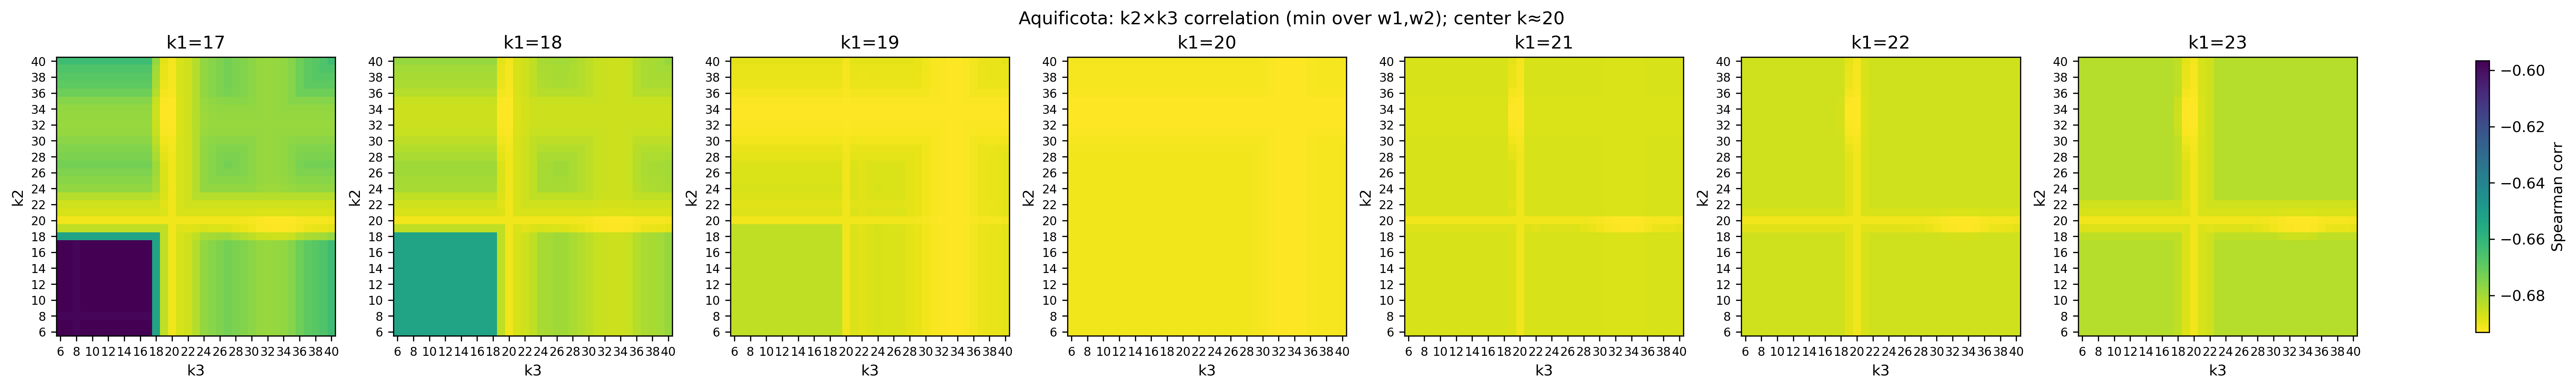

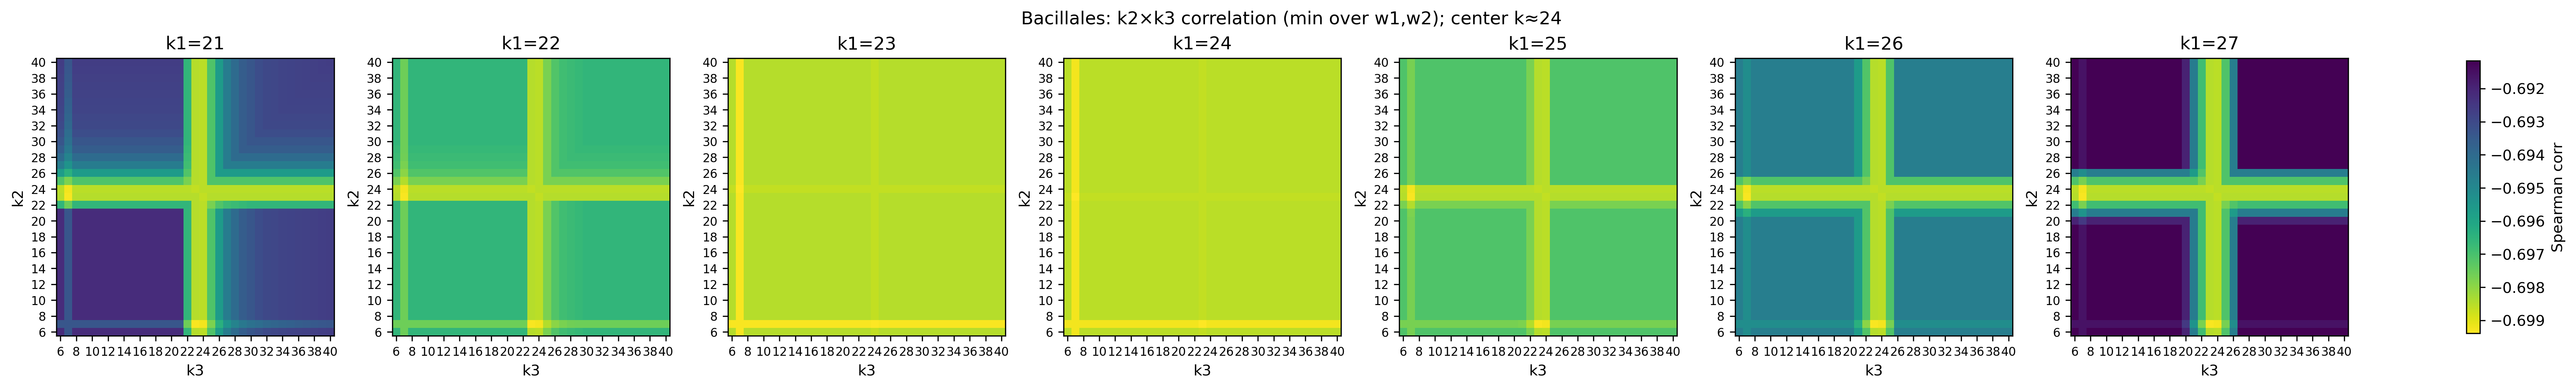

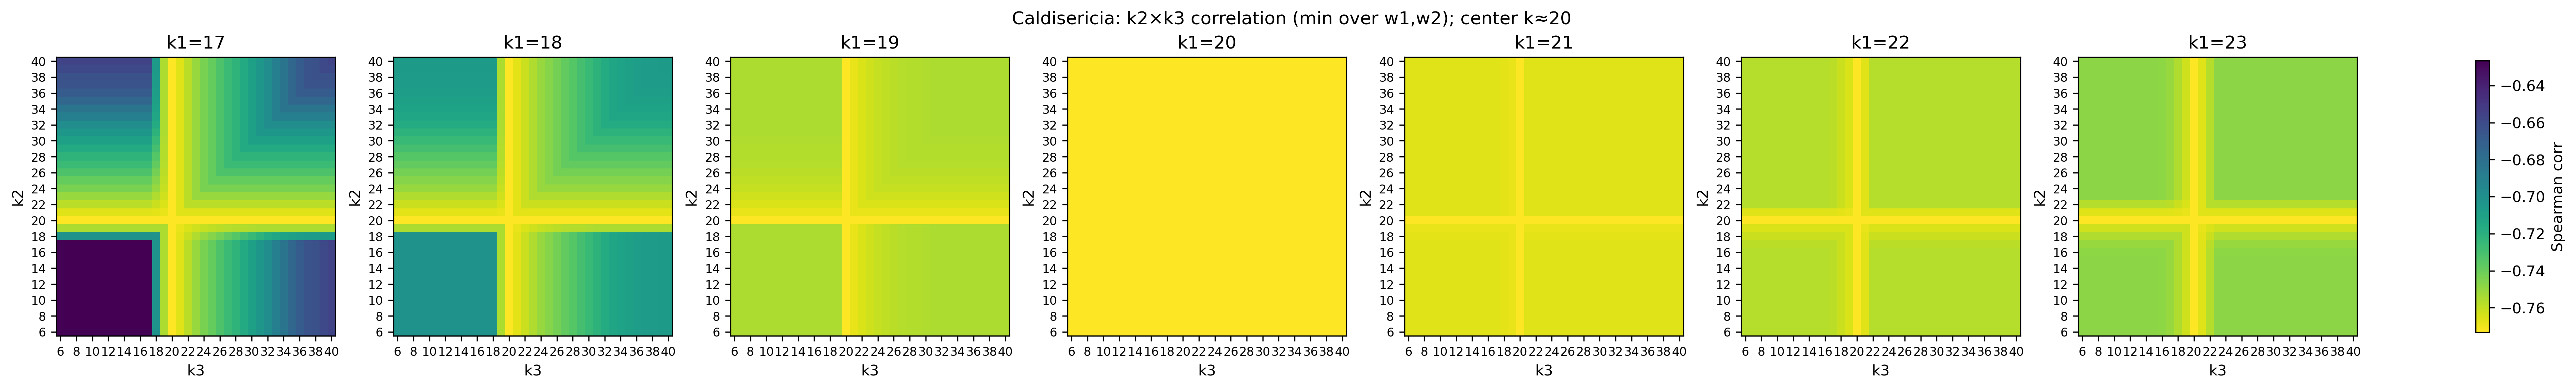

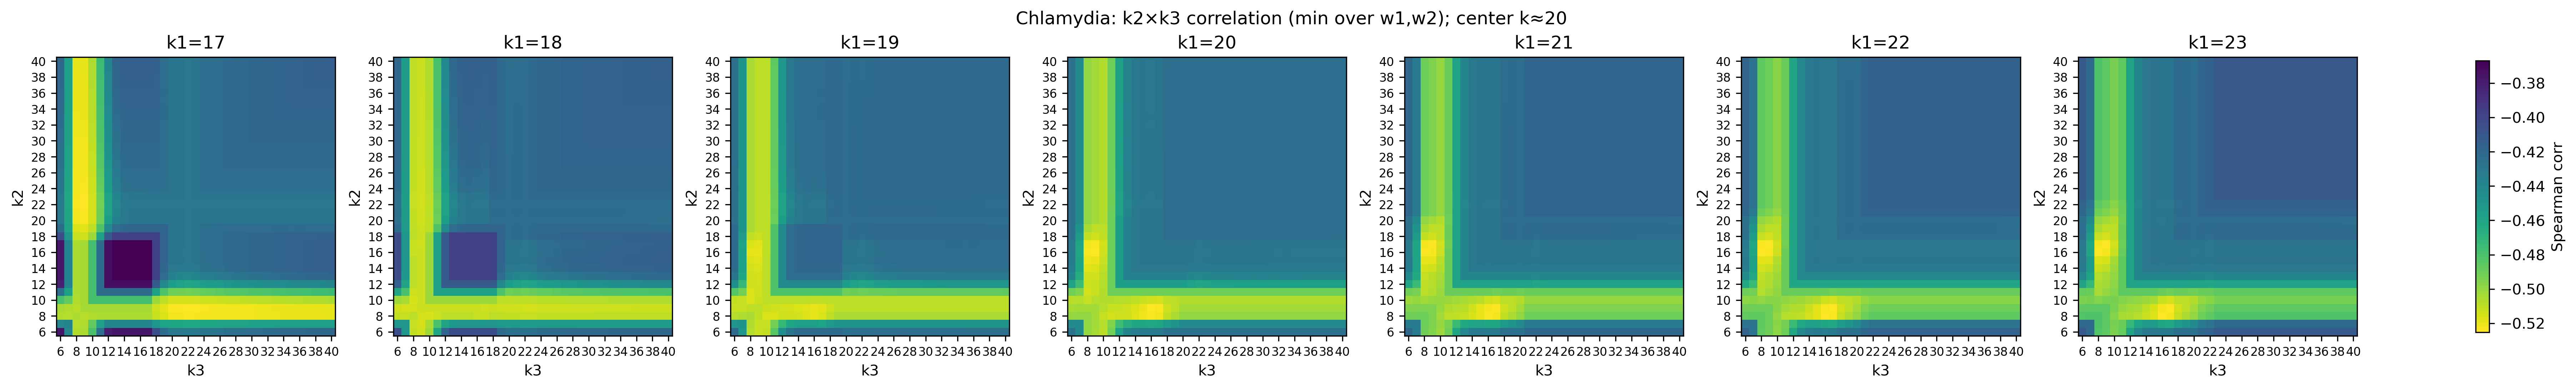

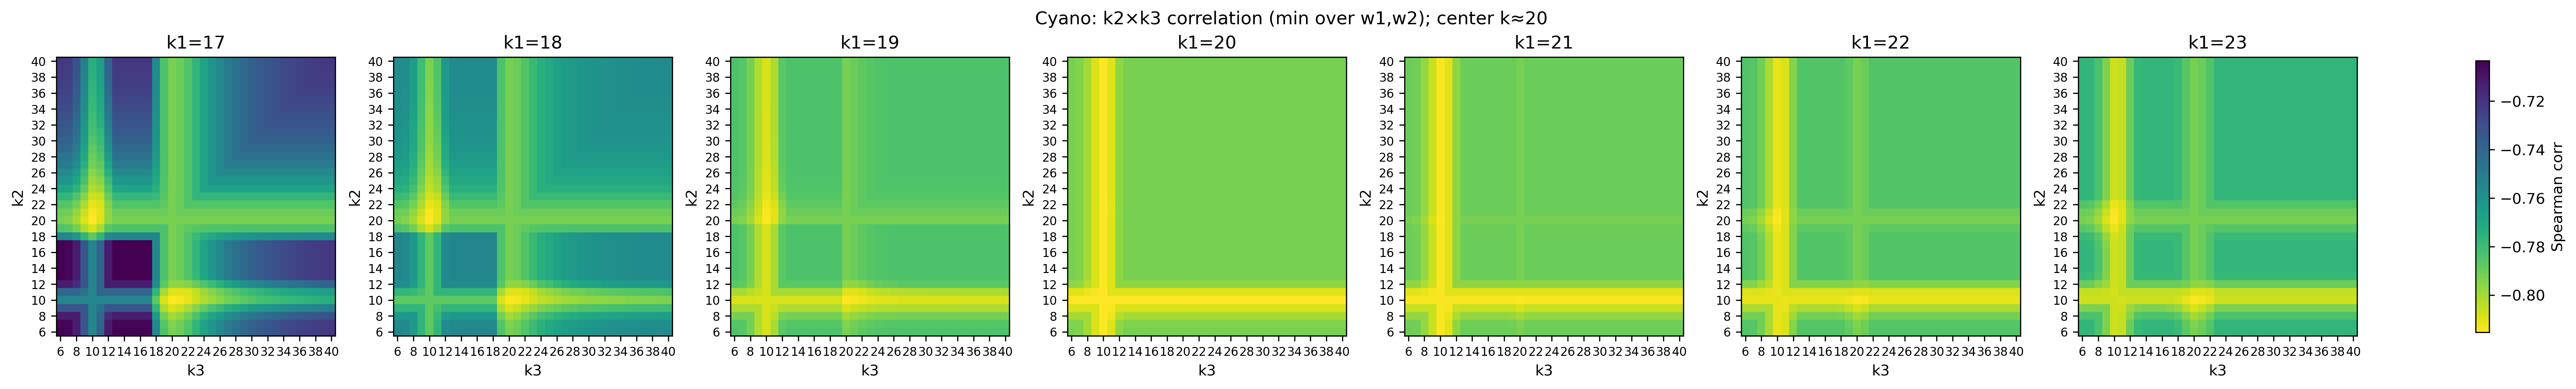

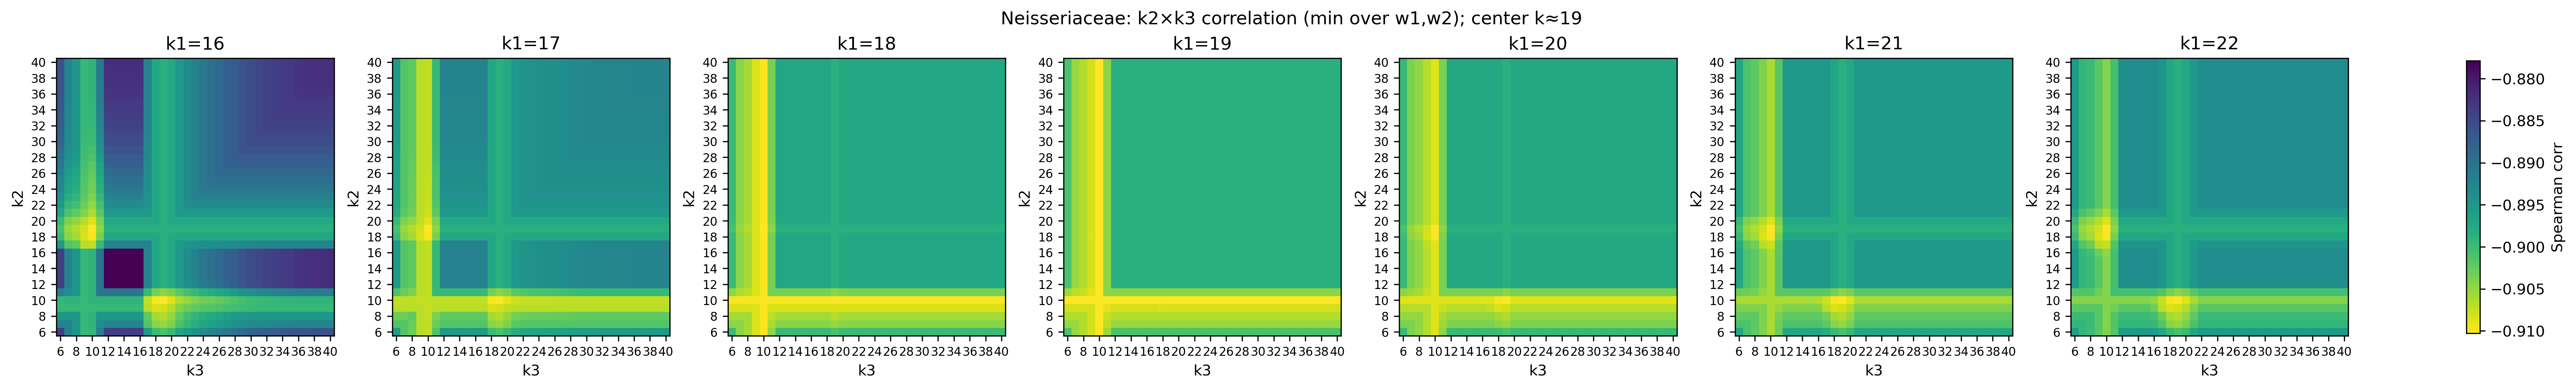

In [49]:
grid_datasets_with_k = [
    ("Aquificota", aquificota_grid, 20),
    ("Bacillales", bacillales_grid, 24),
    ("Caldisericia", caldisericia_grid, 20),
    ("Chlamydia", chlamydia_grid, 20),
    ("Cyano", cyano_grid, 20),
    ("Neisseriaceae", neisseriaceae_grid, 19),
]

s = 3
k_low = 6
k_high = 40

for name, grid_df, k in grid_datasets_with_k:
    plot_grid_heatmaps_no_annot(name, grid_df, k, s, k_low, k_high)

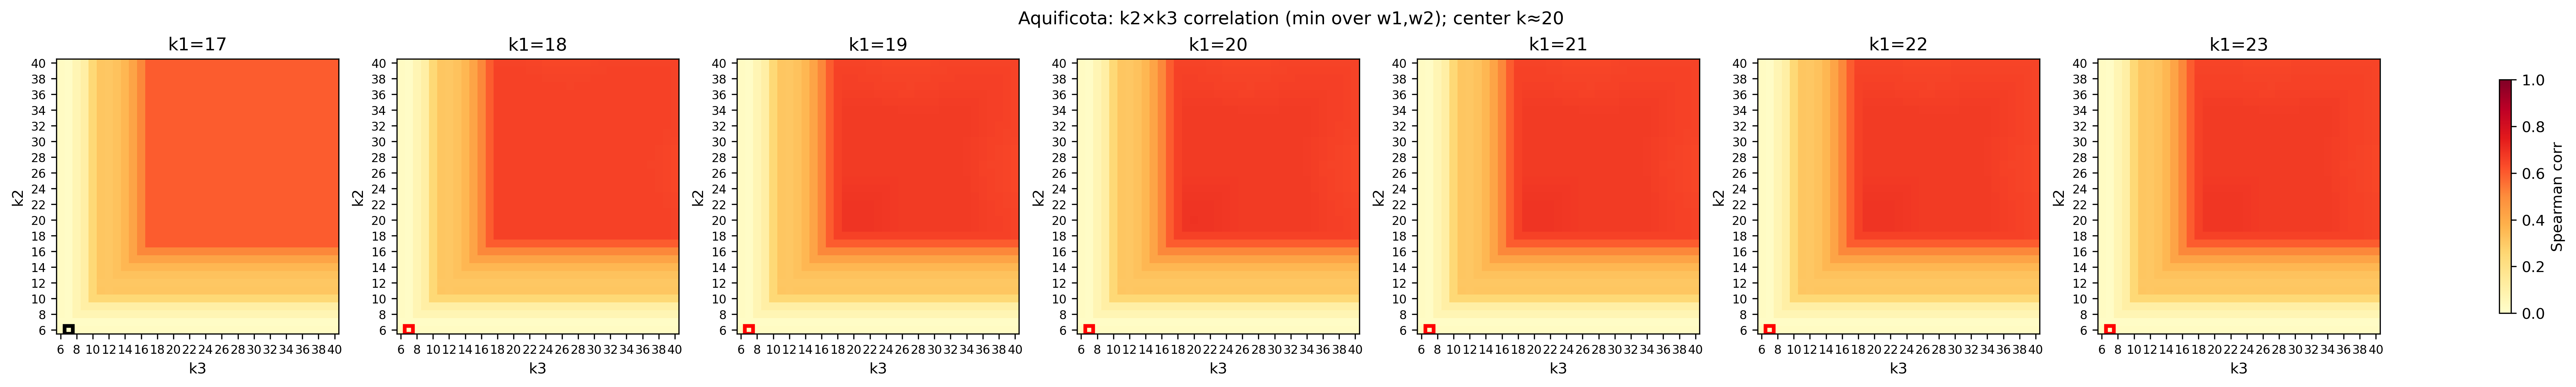

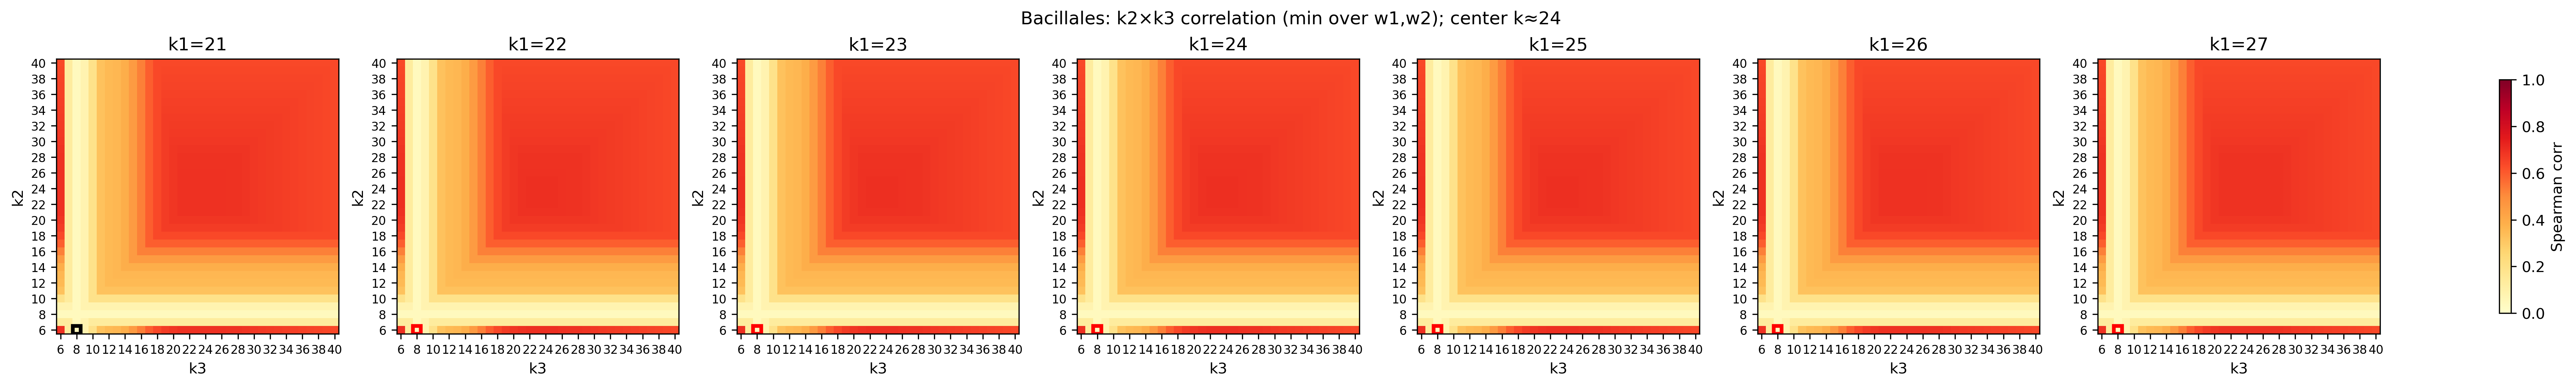

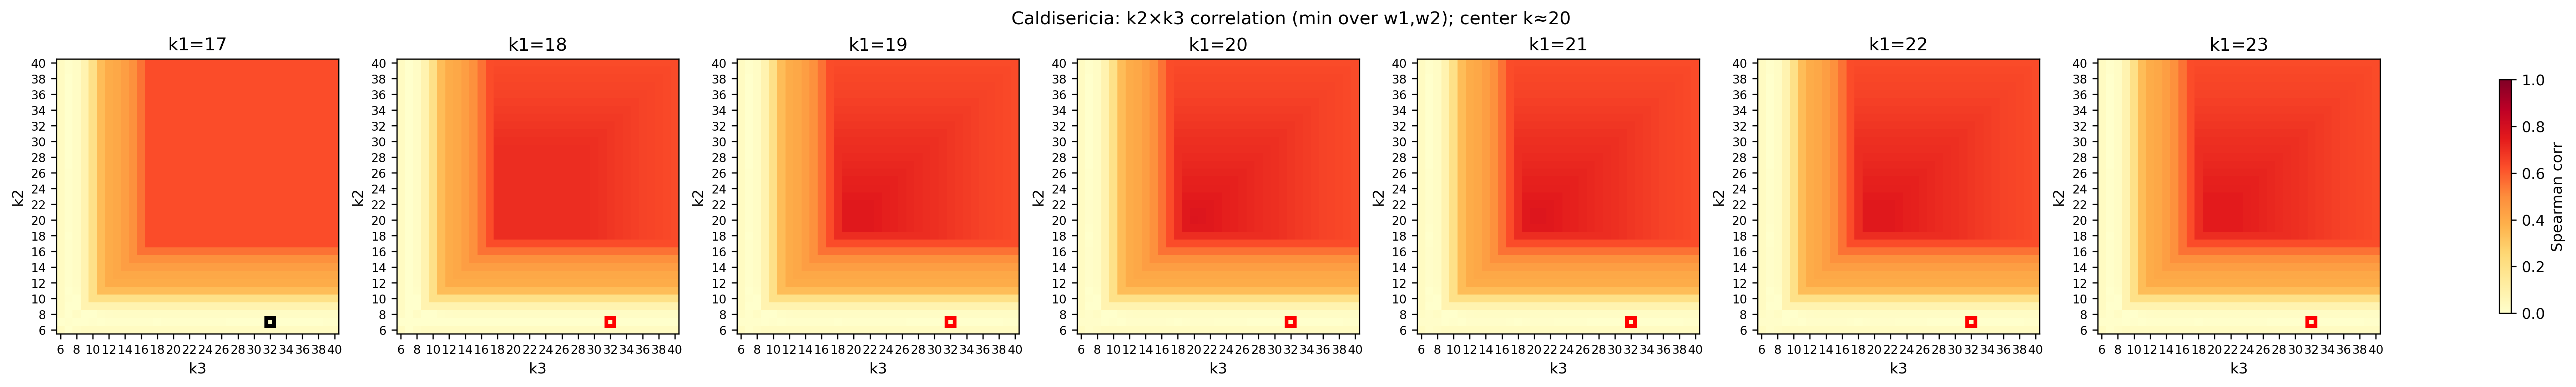

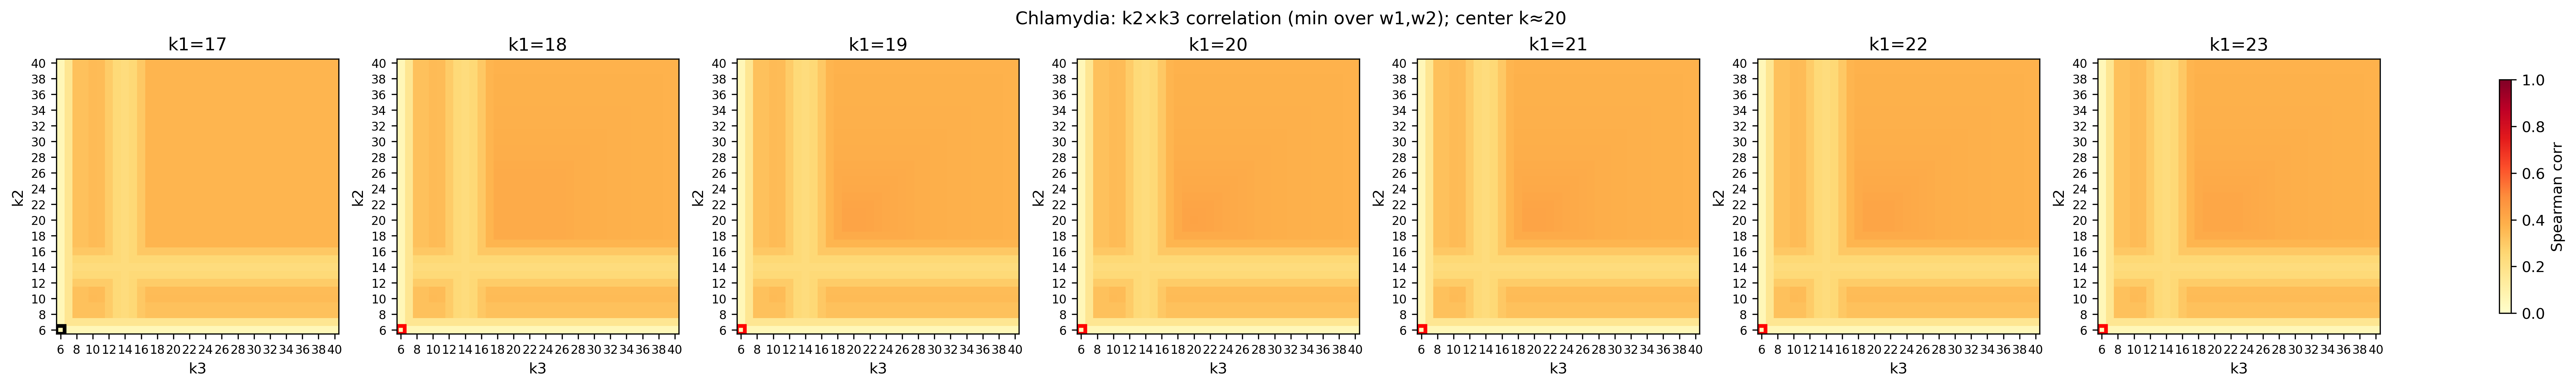

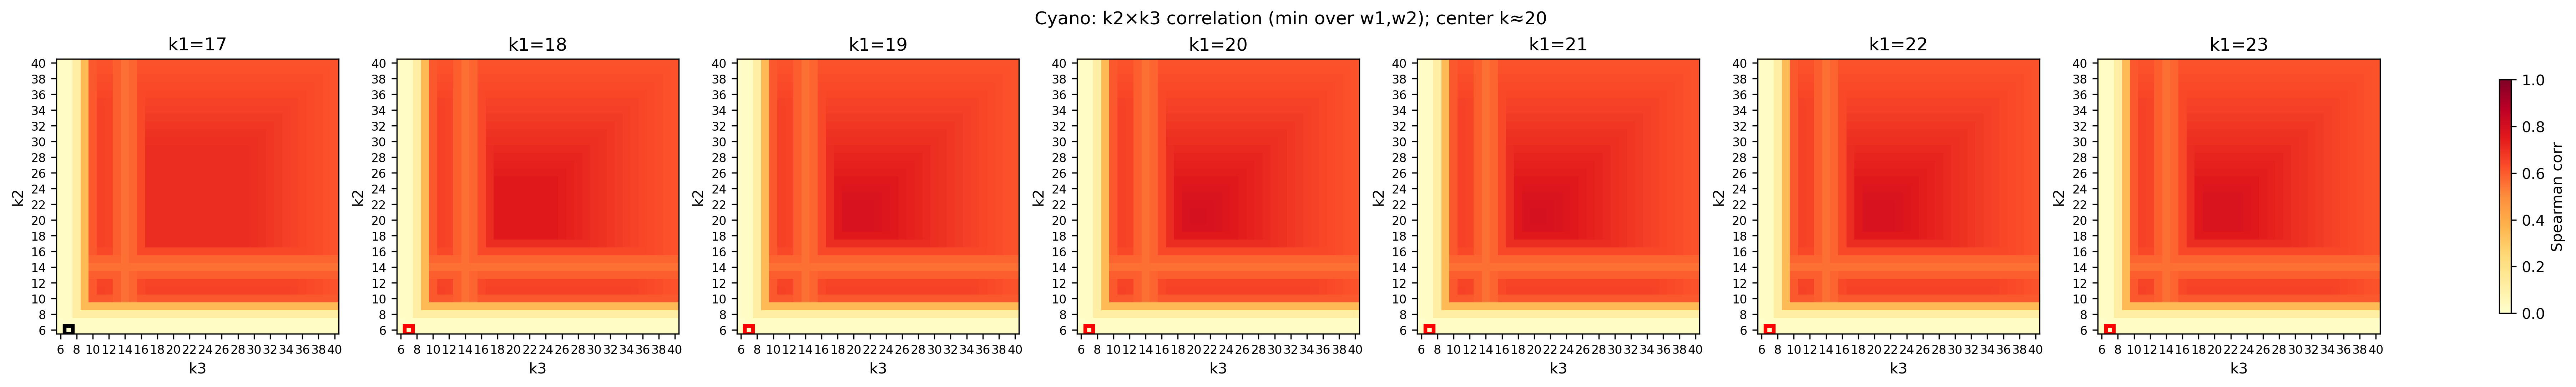

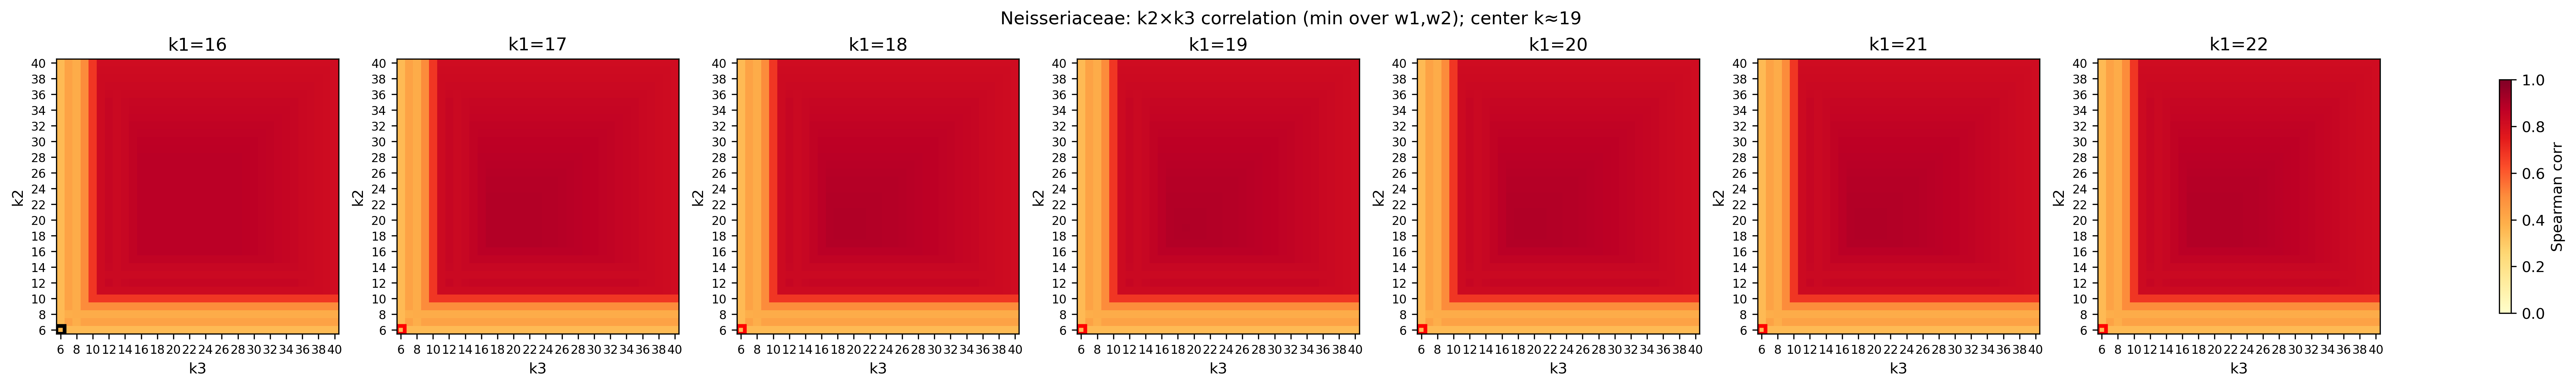

In [63]:

def plot_grid_heatmaps(name, grid_df, k, s, k_low, k_high):
    """
    Plot 7 heatmaps (one per k1 slice), each 35×35 (k2 × k3);
    collapse weight dims by min Spearman (matches grid objective).
    Only show every other tick for the x and y axes.
    Makes x and y tick labels smaller for better visualization.
    In each subplot, color the best (most negative correlation) cell red.
    Between each subplot (i.e., across all subplots), color the overall best (most negative correlation out of all subplots) cell black.
    """
    planes = grid_df.min(axis=(3, 4))  # (7, 35, 35)
    fig, axes = plt.subplots(1, 7, figsize=(24, 3.5), constrained_layout=True)
    pfin = planes[np.isfinite(planes)]
    vmin, vmax = float(np.min(pfin)), float(np.max(pfin))

    # Make k_labels for k1 axis: [k-s, ..., k, ..., k+s]
    k_subplot_labels = [k + offset for offset in range(-s, s + 1)]
    k_axis_labels = list(range(k_low, k_high + 1))

    # Only select every other label for ticks
    n_labels = len(k_axis_labels)
    xticks = list(range(n_labels))
    yticks = list(range(n_labels))
    xtick_skip = 2
    ytick_skip = 2

    xtick_positions = xticks[::xtick_skip]
    xtick_labels = [k_axis_labels[i] for i in xtick_positions]
    ytick_positions = yticks[::ytick_skip]
    ytick_labels = [k_axis_labels[i] for i in ytick_positions]

    # Find the overall most negative cell across all planes
    global_min = np.nanmin(planes)
    g_indices = np.where(planes == global_min)
    if len(g_indices[0]) > 0:
        global_best_subplot = int(g_indices[0][0])
        global_best_y = int(g_indices[1][0])
        global_best_x = int(g_indices[2][0])
    else:
        global_best_subplot = global_best_y = global_best_x = None

    im = None
    tick_label_fontsize = 8  # Make tick labels smaller
    for i, ax in enumerate(axes):
        data = planes[i]
        # im = ax.imshow(data, aspect="equal", origin="lower", vmin=vmin, vmax=vmax, cmap="viridis_r") # og
        # im = ax.imshow(data, aspect="equal", origin="lower", vmin=vmin, vmax=vmax, cmap="YlOrRd")
        # im = ax.imshow(planes[i], aspect="auto", origin="lower", vmin=0, vmax=1, cmap="YlOrRd")
        im = ax.imshow(data, aspect="auto", origin="lower", vmin=0, vmax=1, cmap="YlOrRd")

        ax.set_xlabel("k3")
        ax.set_ylabel("k2")
        ax.set_title(f"k1={k_subplot_labels[i]}")

        # Set ticks and labels for axes, but plot every other one, with smaller fonts
        ax.set_xticks(xtick_positions)
        ax.set_xticklabels(xtick_labels, fontsize=tick_label_fontsize)
        ax.set_yticks(ytick_positions)
        ax.set_yticklabels(ytick_labels, fontsize=tick_label_fontsize)

        # Highlight the best (most negative) cell in the plane with a red rectangle or marker,
        # but only if there is at least one finite value.
        if np.any(np.isfinite(data)):
            min_val = np.nanmin(data)
            # Could be multiple cells tied; pick the first
            ys, xs = np.where(data == min_val)
            if len(ys) > 0:
                y, x = ys[0], xs[0]
                # If this cell is ALSO the global best, color it black. Otherwise, red.
                if i == global_best_subplot and y == global_best_y and x == global_best_x:
                    rect = plt.Rectangle((x - 0.5, y - 0.5), 1, 1,
                                        linewidth=2.5, edgecolor='black', facecolor='none')
                else:
                    rect = plt.Rectangle((x - 0.5, y - 0.5), 1, 1,
                                        linewidth=2.5, edgecolor='red', facecolor='none')
                ax.add_patch(rect)
                # Optionally, overlay a dot at the center
                # if i == global_best_subplot and y == global_best_y and x == global_best_x:
                #     ax.plot(x, y, marker="o", color="black", markersize=6)
                # else:
                #     ax.plot(x, y, marker="o", color="red", markersize=6)

    fig.suptitle(f"{name}: k2×k3 correlation (min over w1,w2); center k≈{k}")
    fig.colorbar(im, ax=axes.ravel().tolist(), shrink=0.85, location="right", label="Spearman corr")
    plt.show()

# Usage example:
# plot_grid_heatmaps(name, grid_df, k, s, k_low, k_high)


grid_datasets_with_k_and_best = [
    ("Aquificota", aquificota_grid, 20),
    ("Bacillales", bacillales_grid, 24),
    ("Caldisericia", caldisericia_grid, 20),
    ("Chlamydia", chlamydia_grid, 20),
    ("Cyano", cyano_grid, 20),
    ("Neisseriaceae", neisseriaceae_grid, 19),
]

s = 3
k_low = 6
k_high = 40

for name, grid_df, k in grid_datasets_with_k_and_best:
    plot_grid_heatmaps(name, grid_df, k, s, k_low, k_high)


        # im = ax.imshow(planes[i], aspect="auto", origin="lower", vmin=0, vmax=1, cmap="YlOrRd")

## Plotting k-mer dist botxplot across k-mer lengths
For each genome-pair, plot dist from Dragen across k-kmers 5 -> 64.

In [16]:
def plot_kmer_dashing_distances(merged_df, k_min=5, k_max=64):
    """
    Plot k-mer distances boxplots for columns k{k}_distance in merged_df.

    Parameters
    ----------
    merged_df : pandas.DataFrame
        DataFrame containing columns like 'k5_distance', ..., 'k64_distance'.
    k_min : int, optional
        Minimum k to start from (default is 5).
    k_max : int, optional
        Maximum k to end at (default is 64).
    """
    data = []
    labels = []
    for k in range(k_min, k_max + 1):
        col = f"k{k}_distance"
        if col in merged_df.columns:
            data.append(merged_df[col].dropna())
            labels.append(f"k{k}")

    plt.figure(figsize=(max(12, len(labels) * 0.4), 6))
    plt.boxplot(data, labels=labels, showfliers=False)
    plt.xticks(rotation=90)
    plt.ylabel("k-mer distance")
    plt.title(f"k-mer distances (k = {k_min}..{k_max})")
    plt.tight_layout()
    plt.show()


Plotting k-mer distances for Aquificota


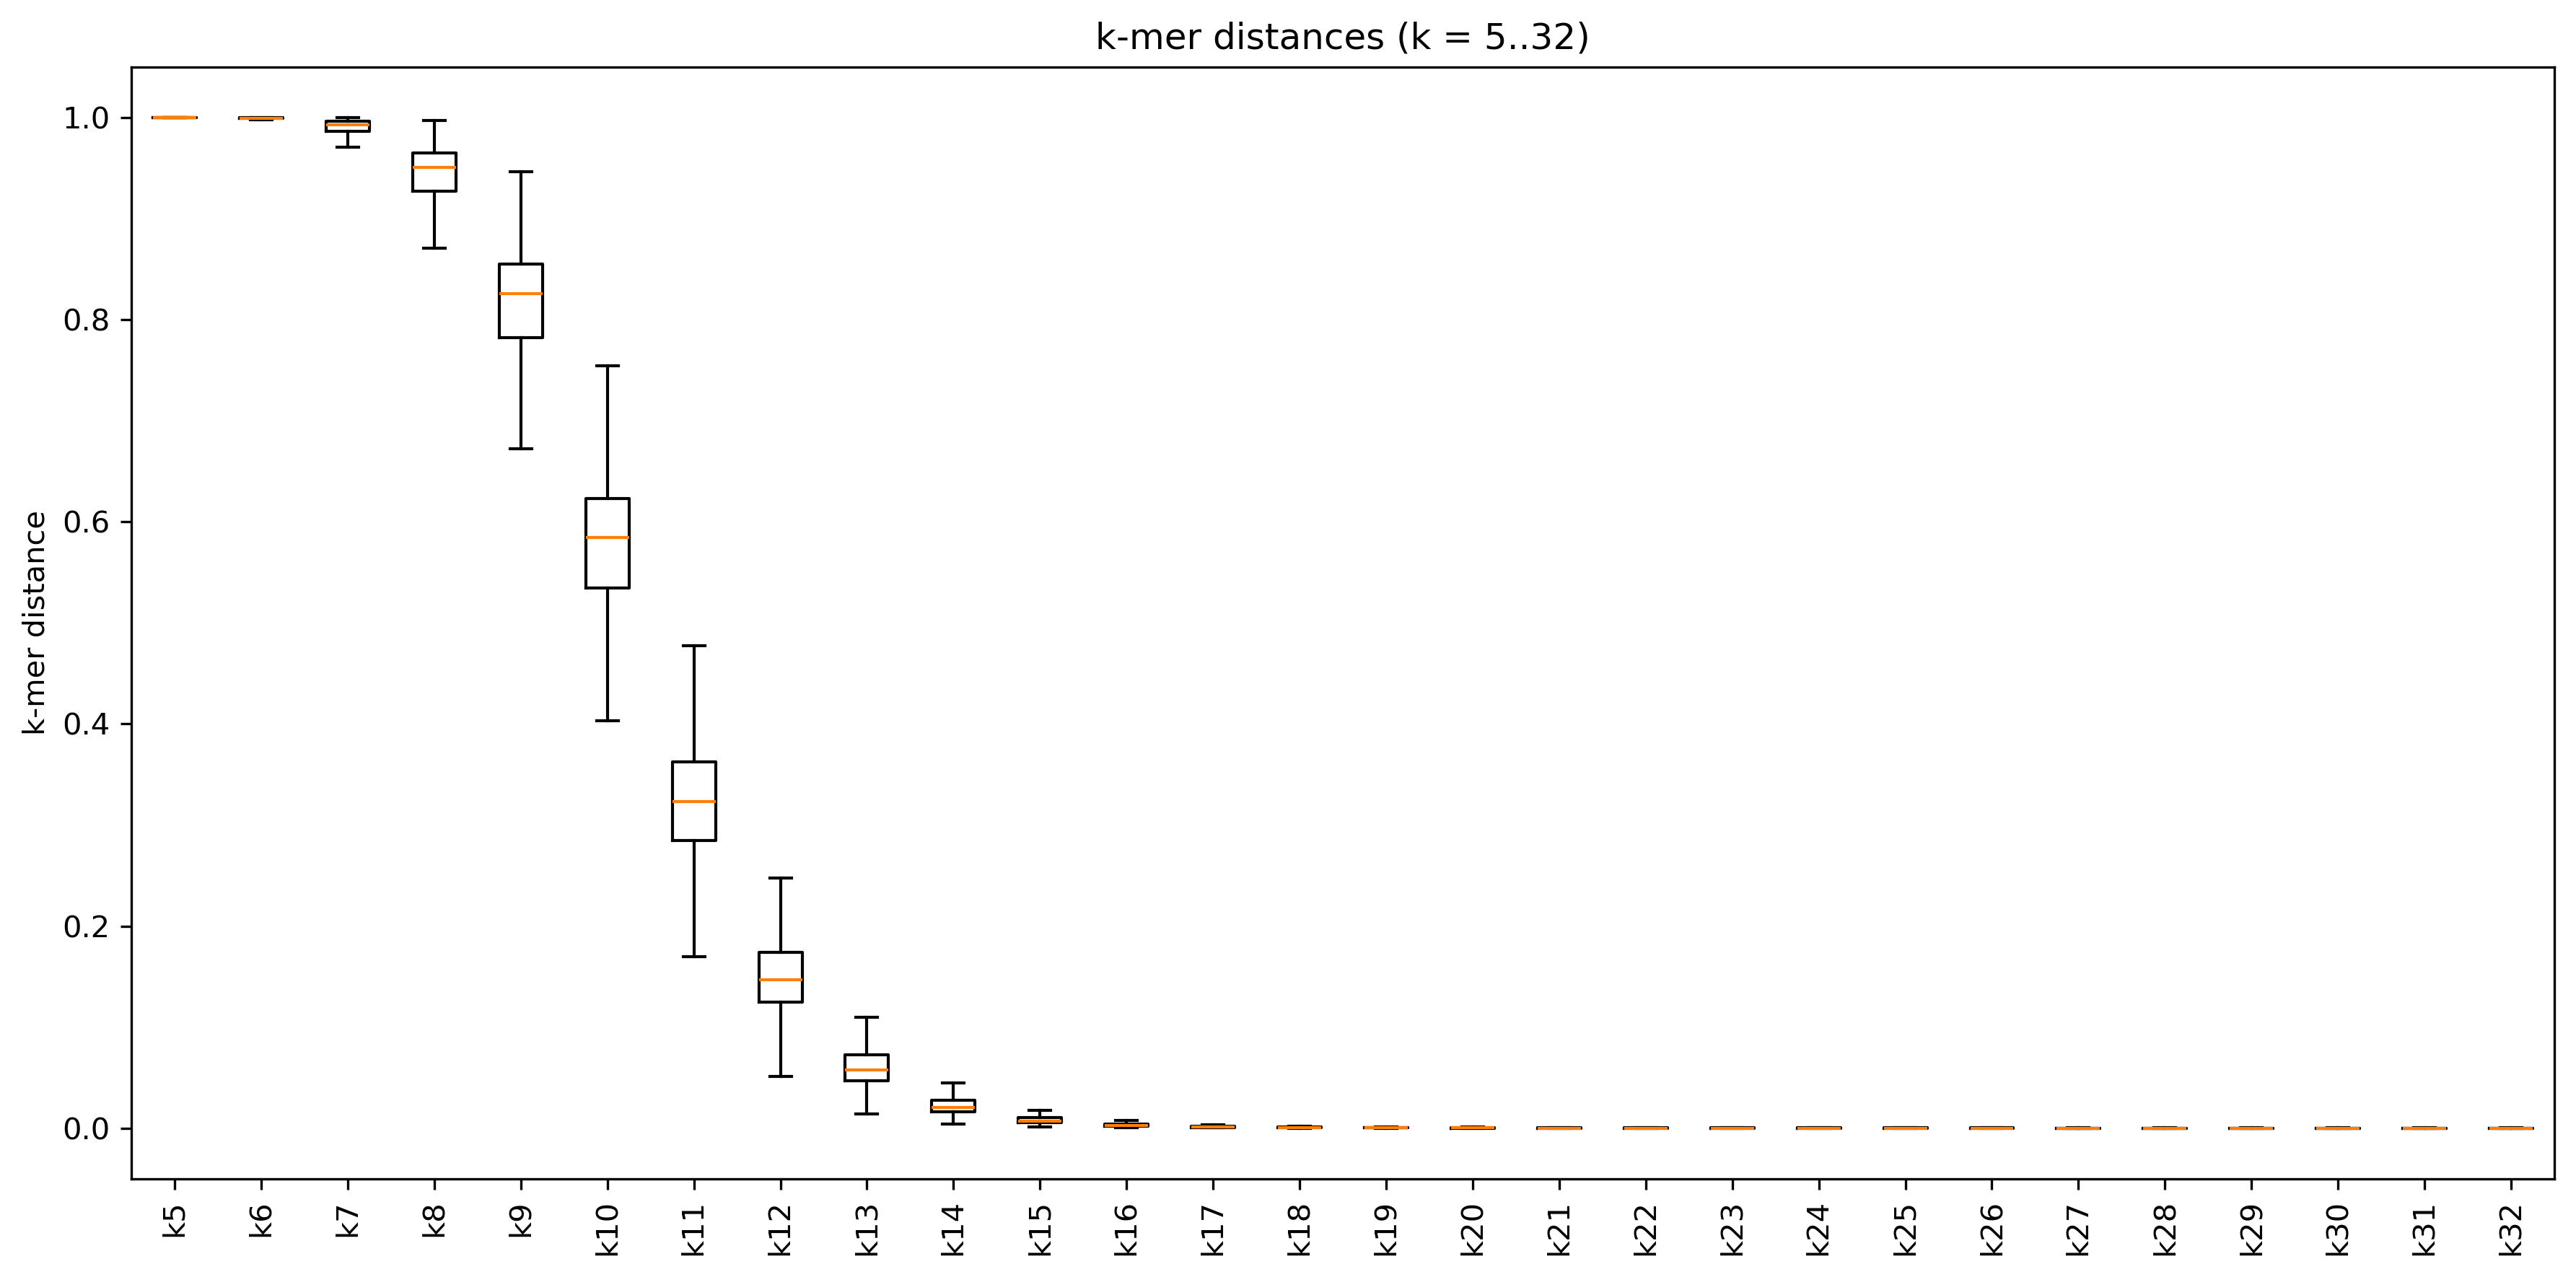

Plotting k-mer distances for Bacillales


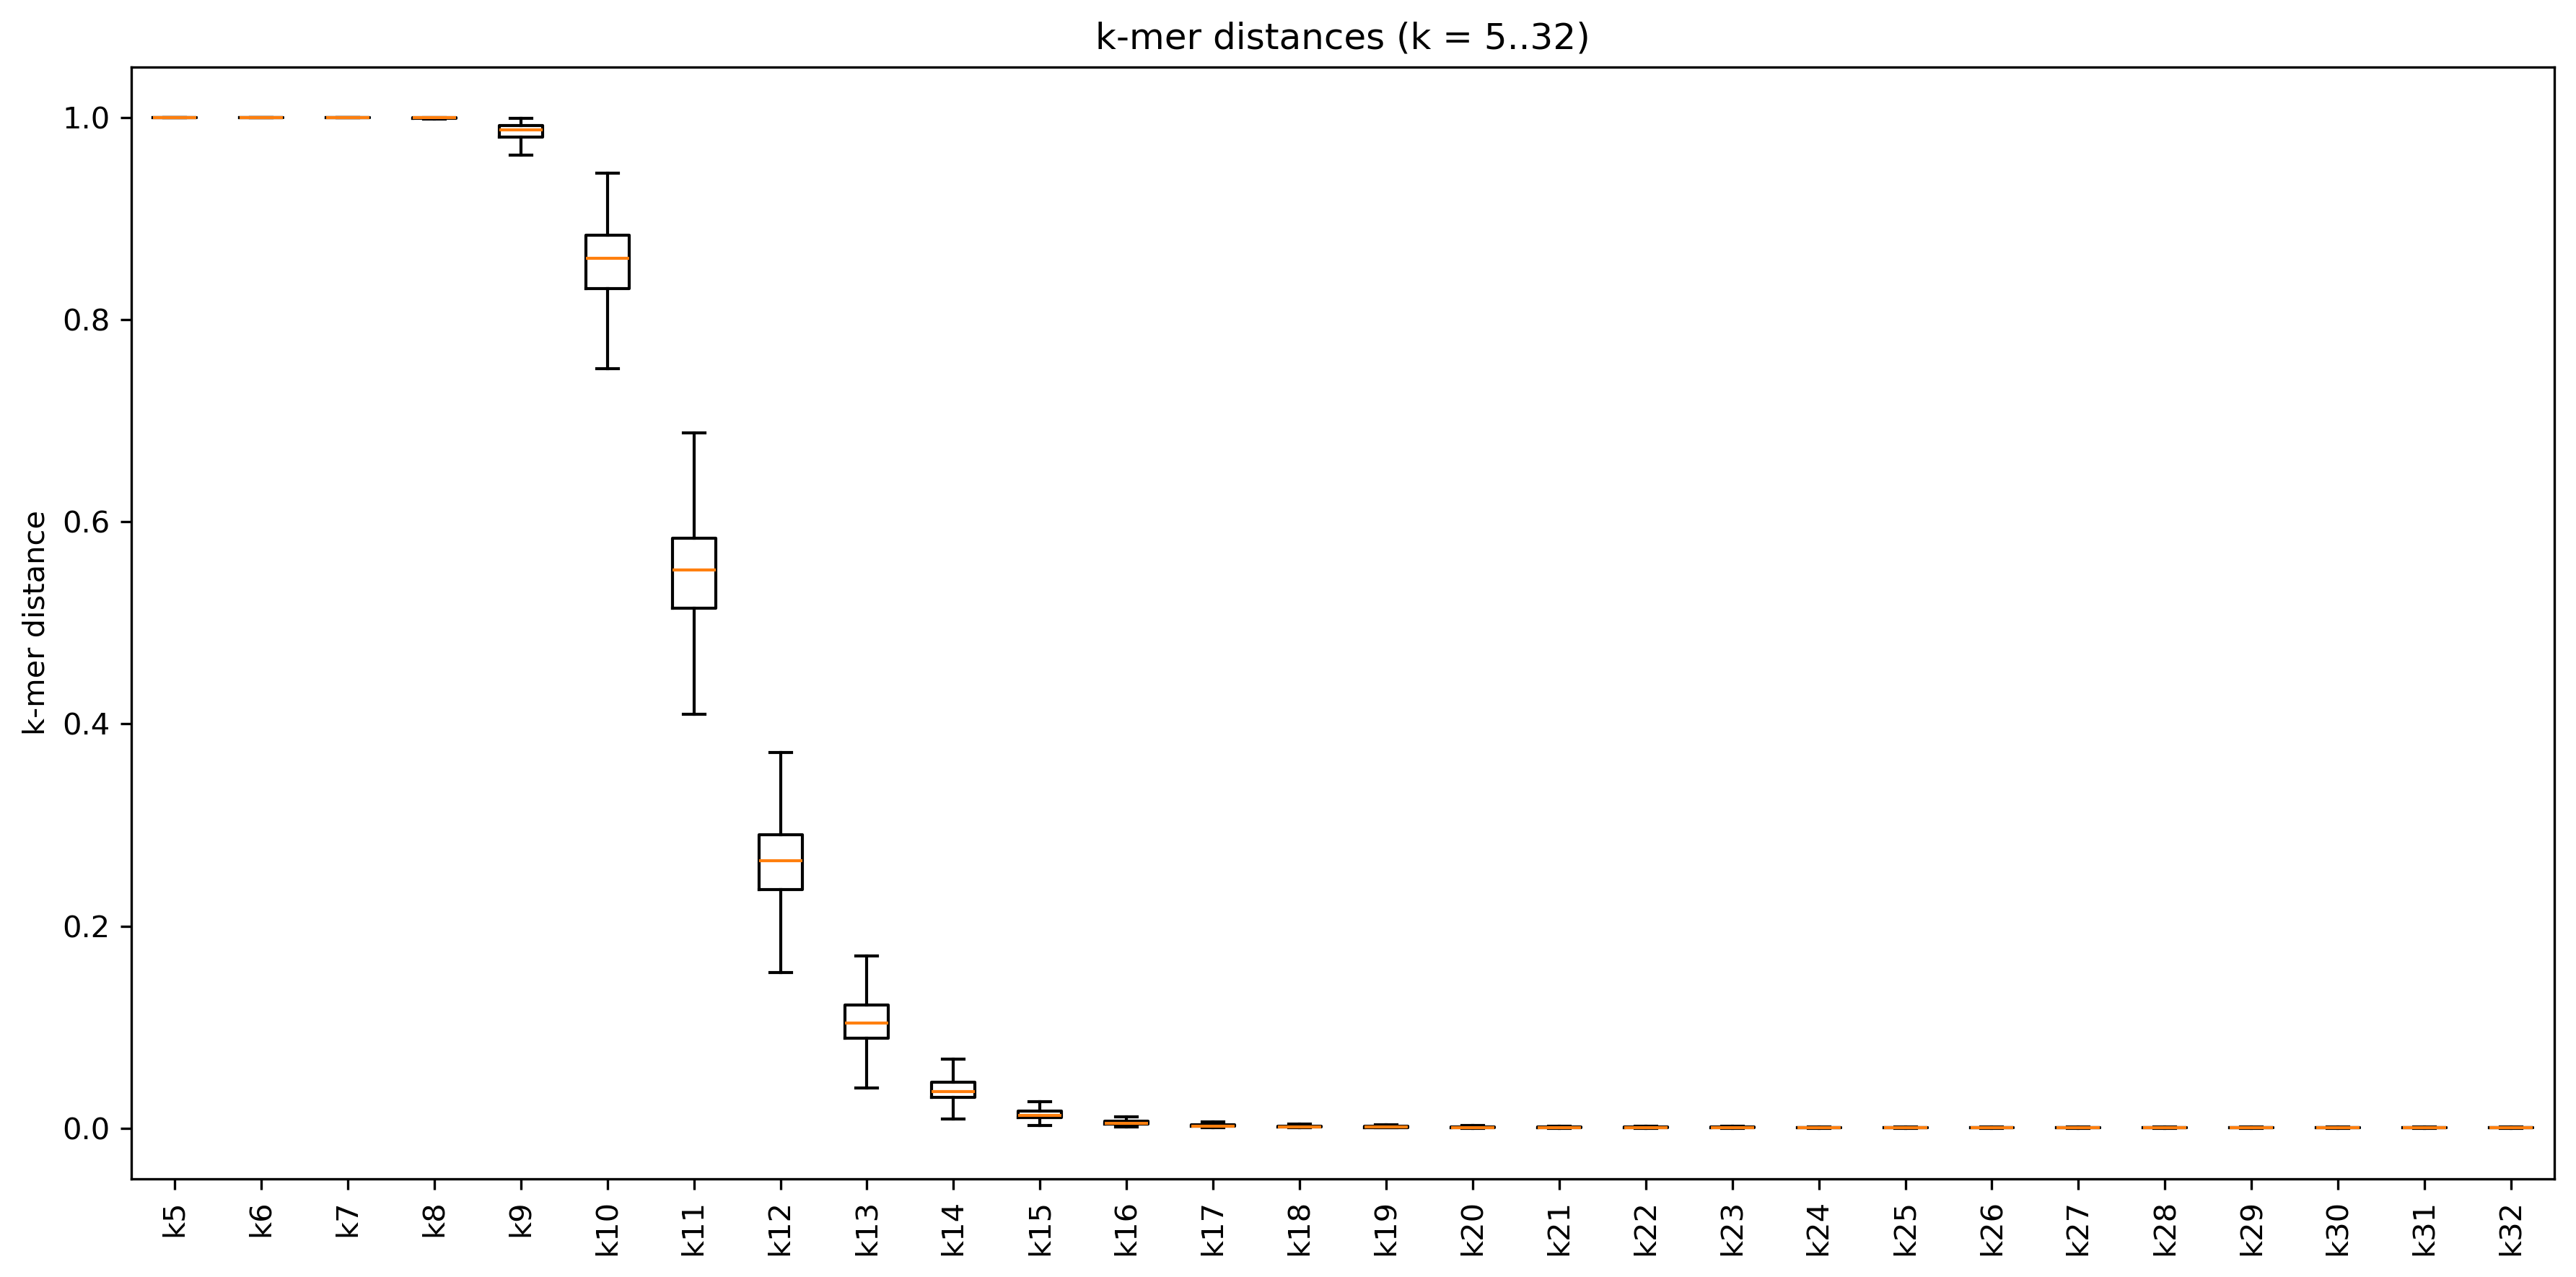

Plotting k-mer distances for Caldisericia


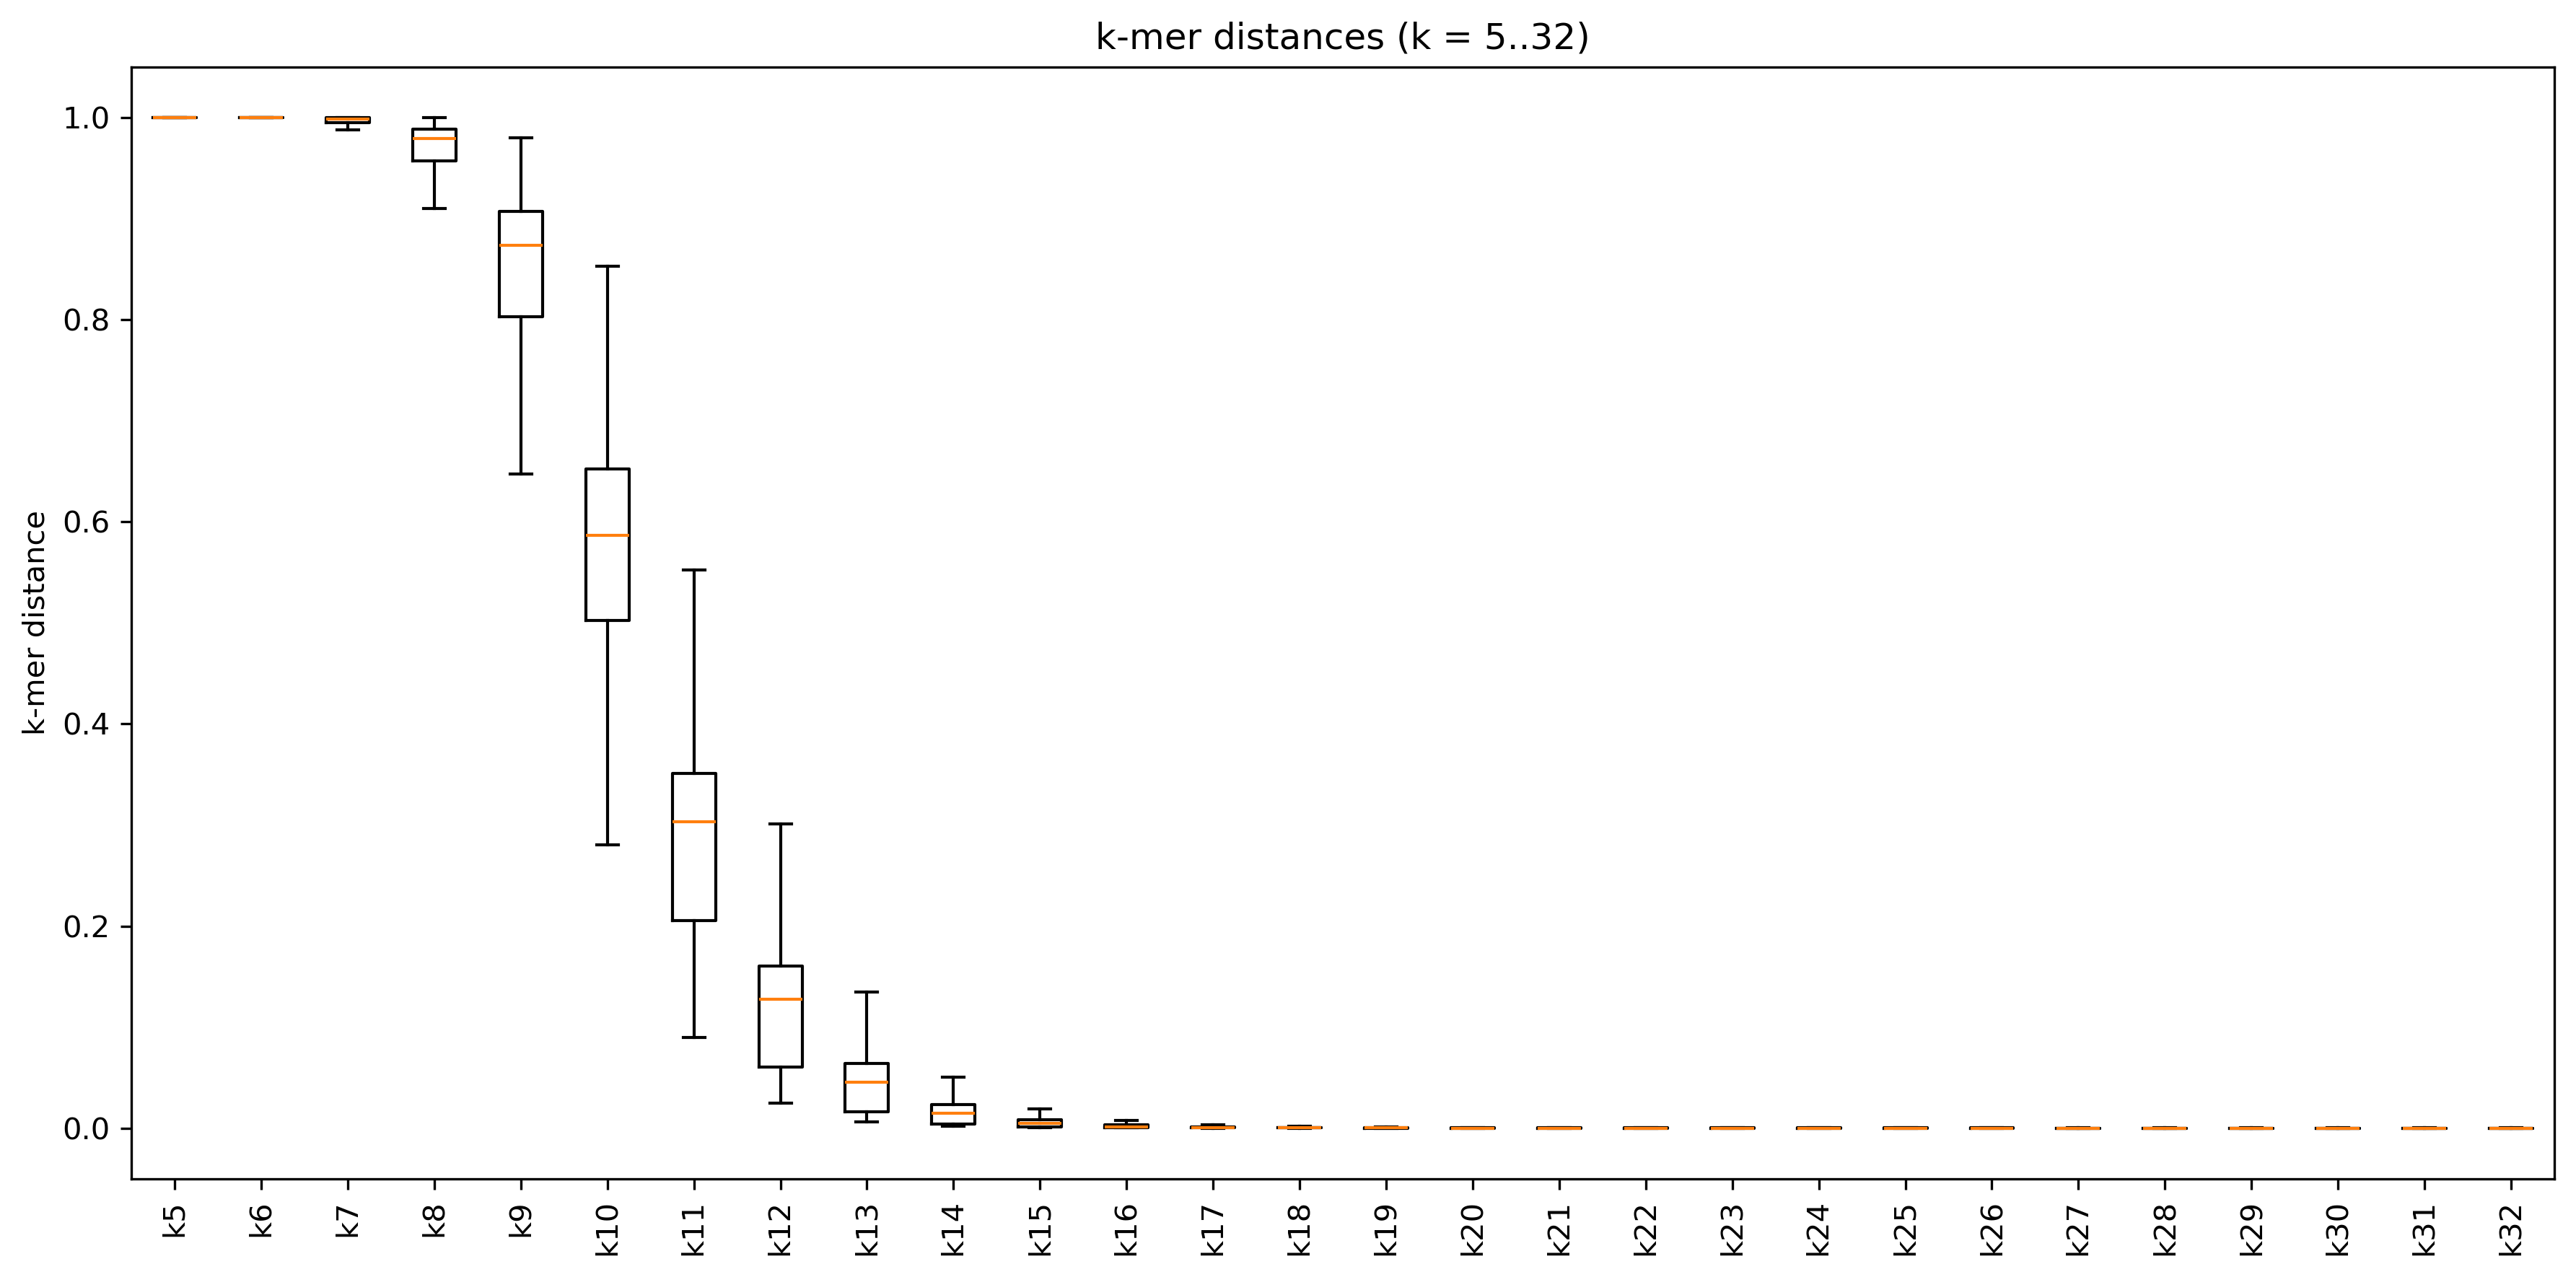

Plotting k-mer distances for Chlamydia


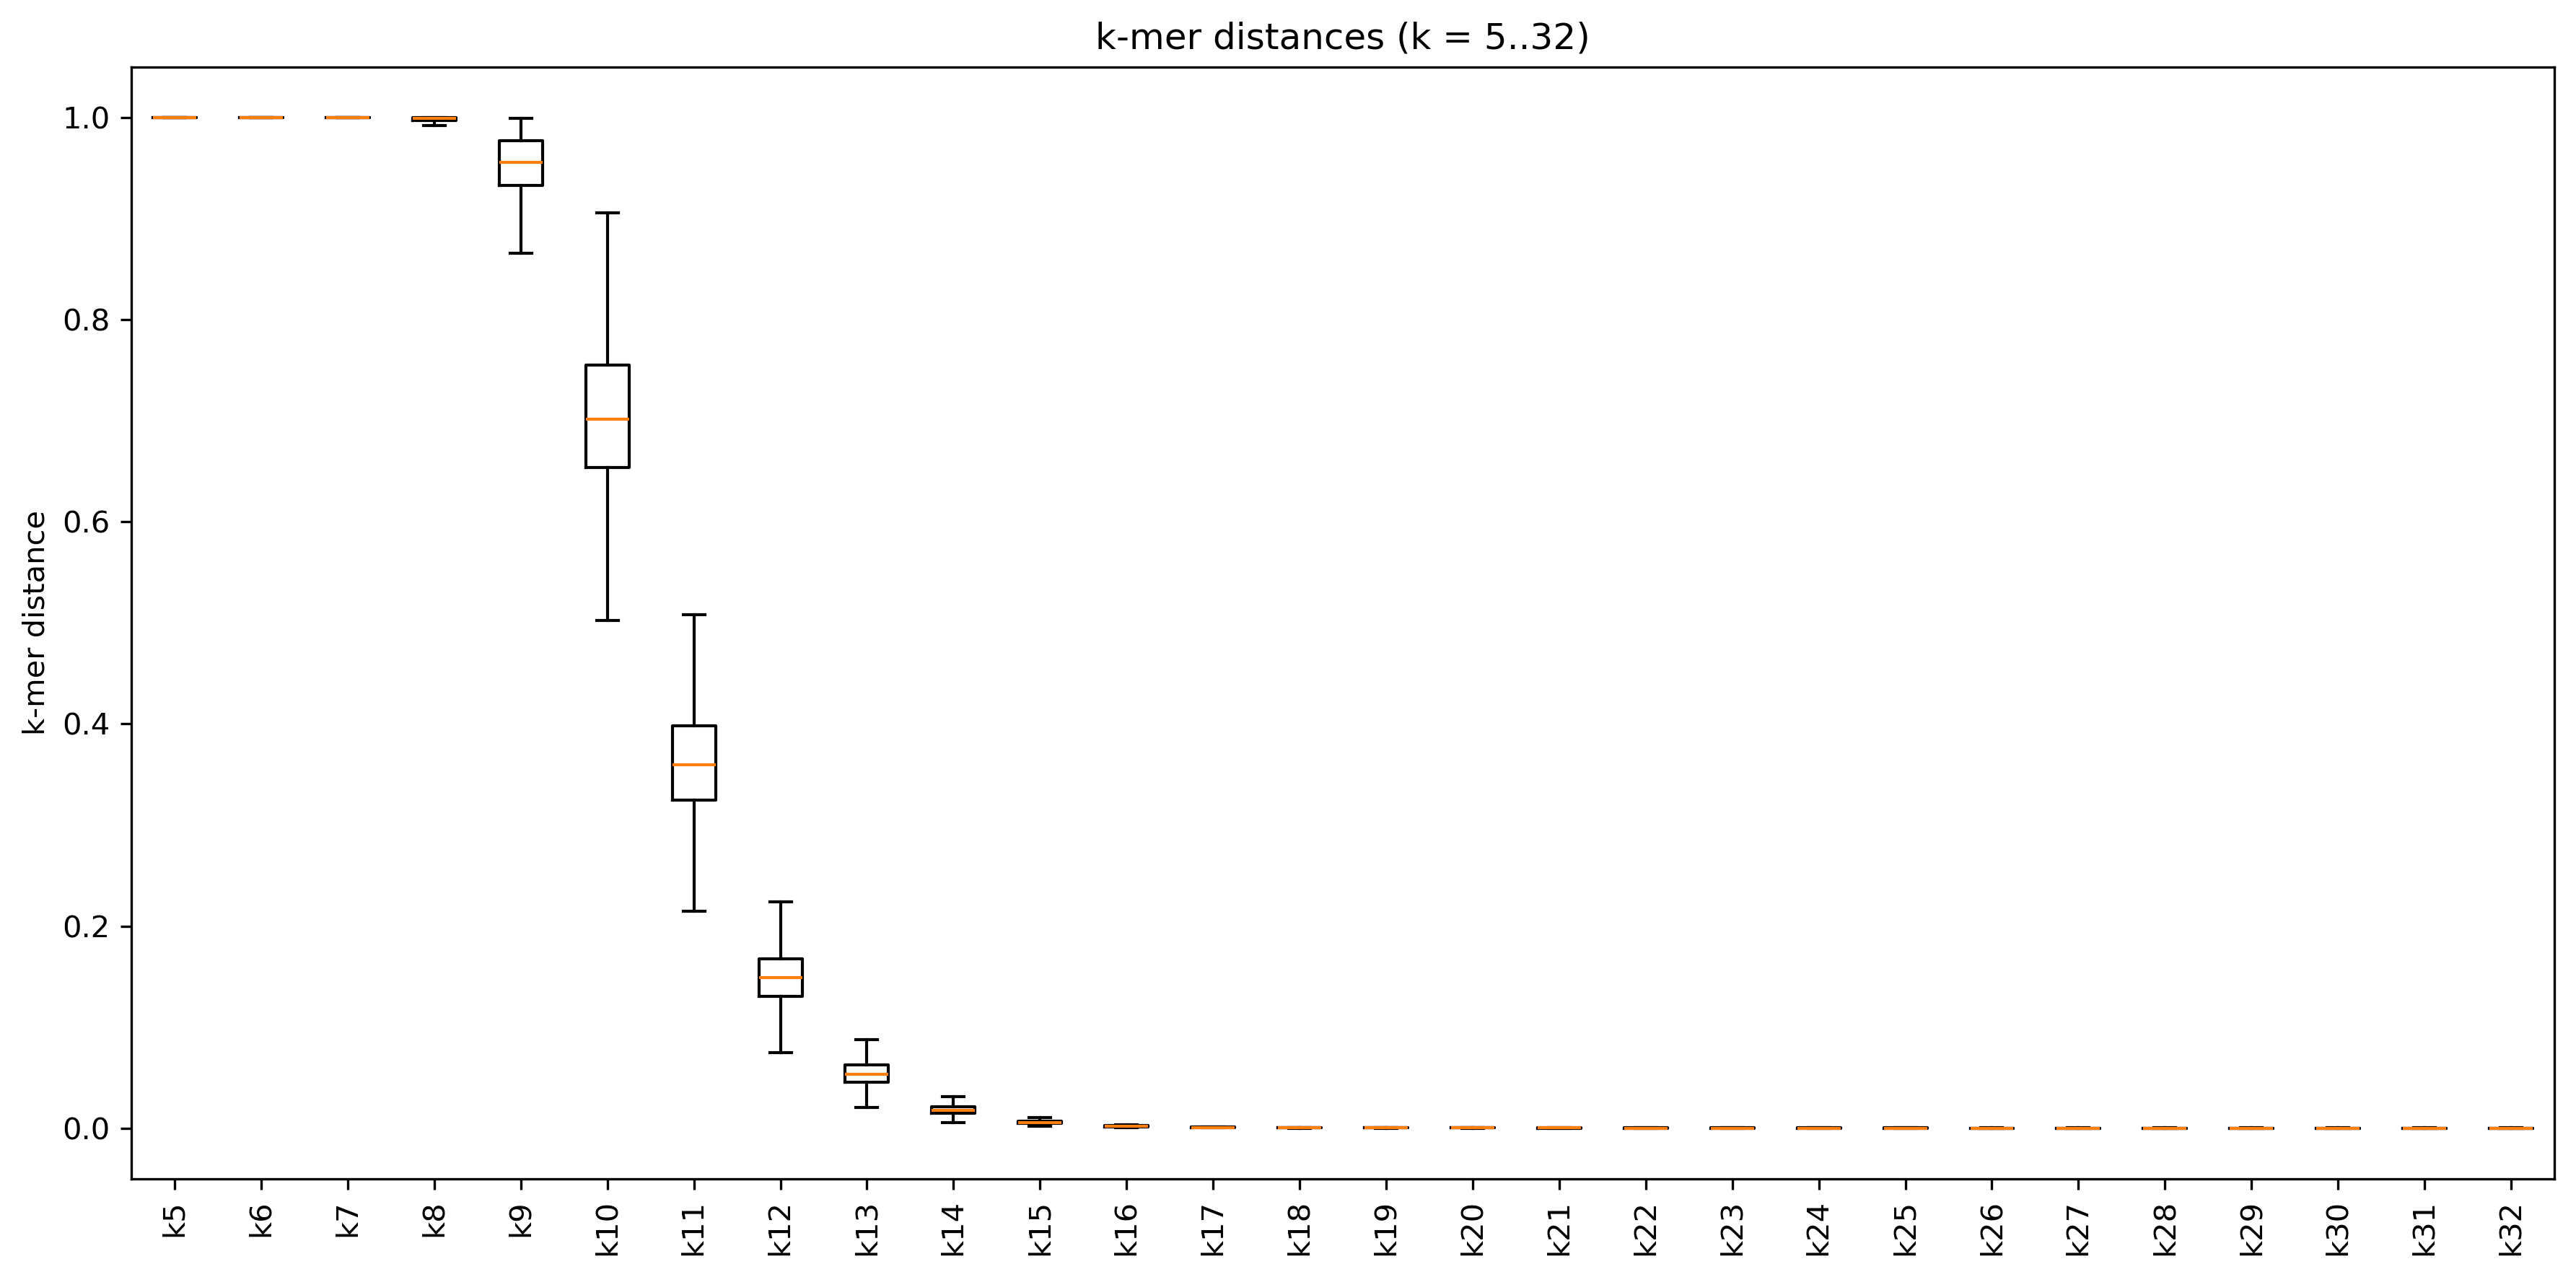

Plotting k-mer distances for Cyano


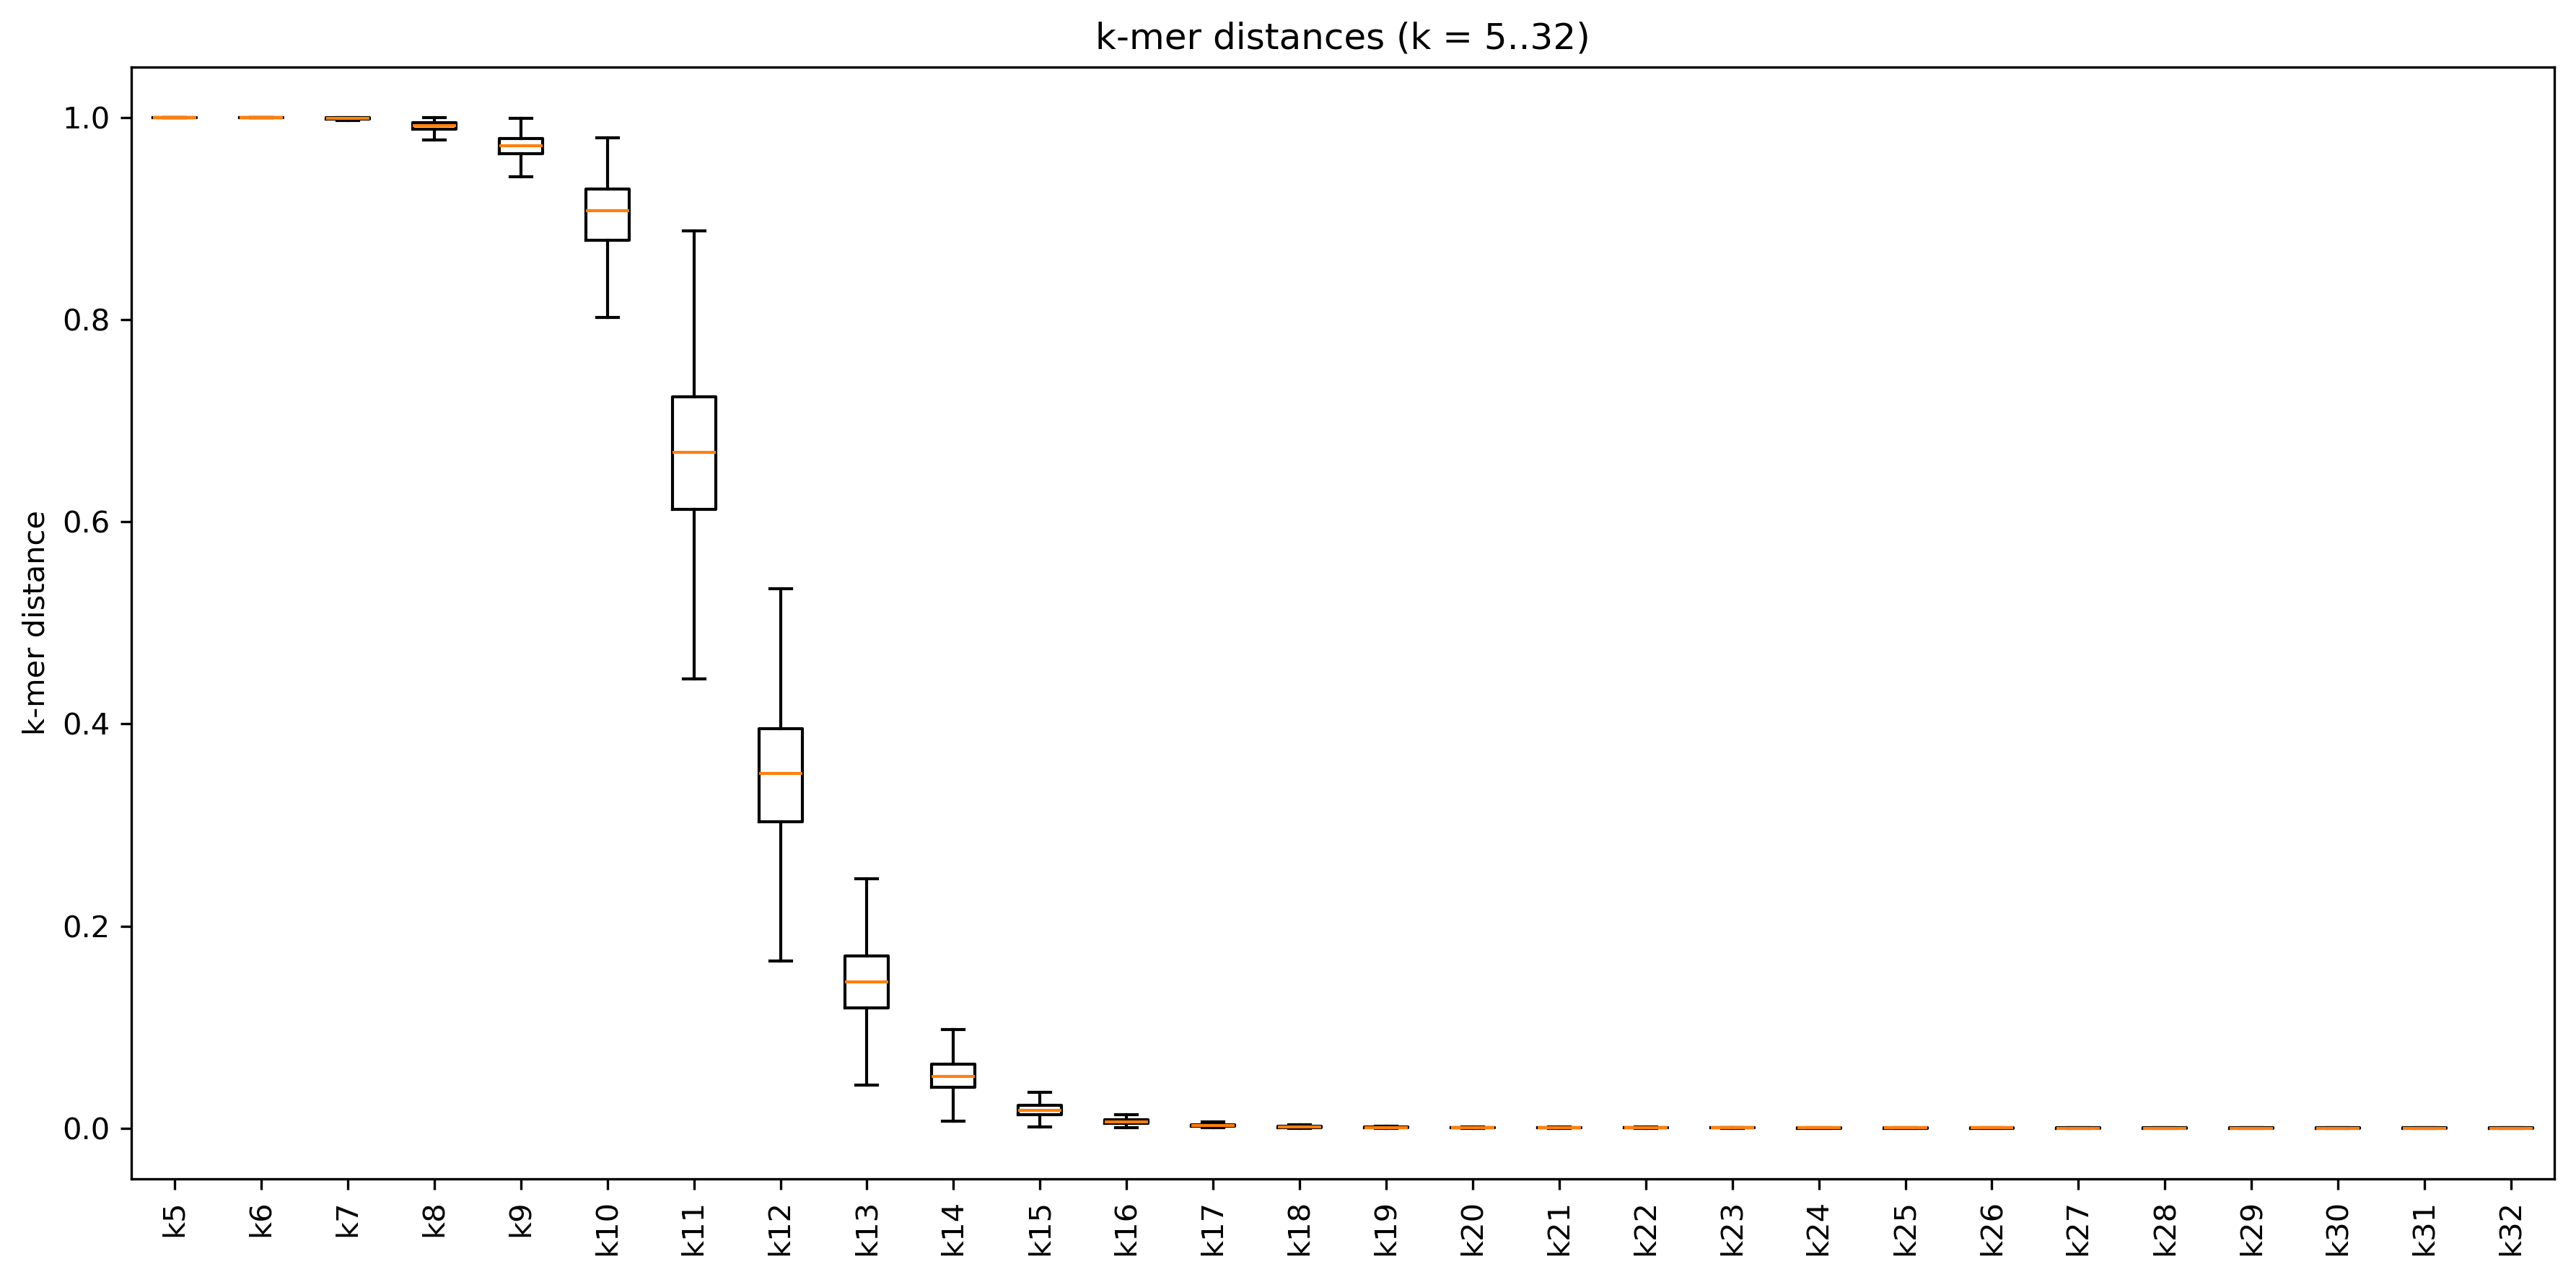

Plotting k-mer distances for Neisseriaceae


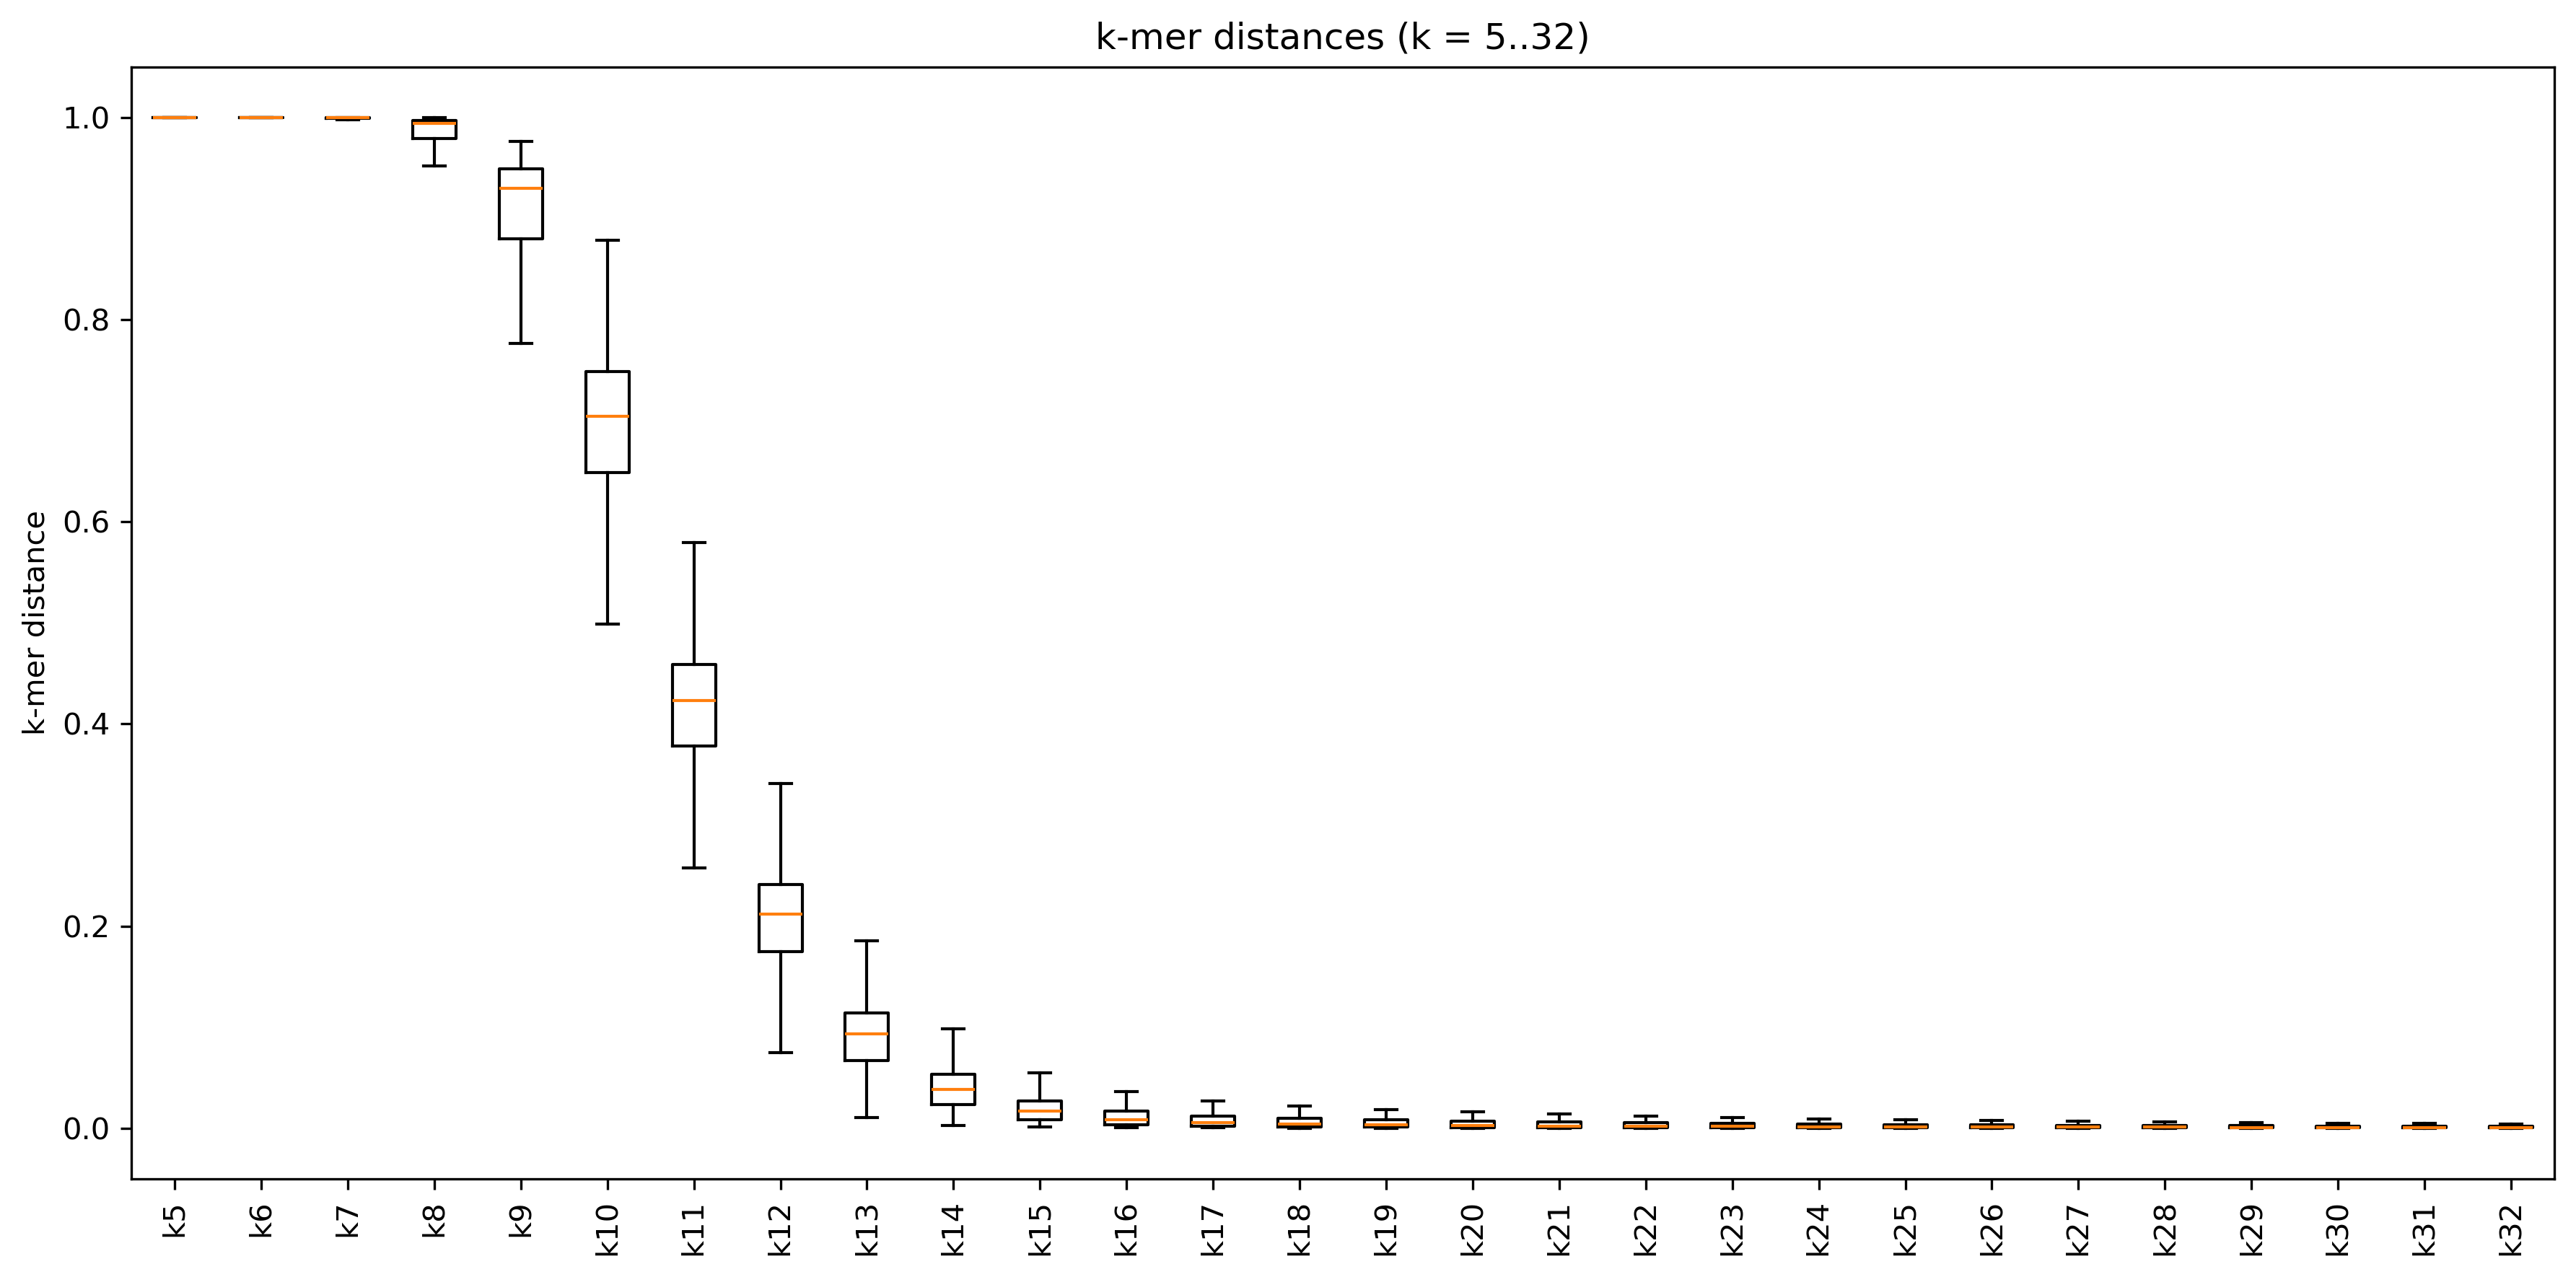

In [17]:
for name, df in datasets:
    print(f"Plotting k-mer distances for {name}")
    plot_kmer_dashing_distances(df, k_min=5, k_max=32)


In [18]:
def calc_k_medians(merged_df, k_min=5, k_max=64):
    """
    For each k in range k_min to k_max, calculate the median k-mer distance
    and return a dictionary with k as key and median as value.
    """
    k_medians = {}
    for k in range(k_min, k_max + 1):
        col = f"k{k}_distance"
        if col in merged_df.columns:
            median_val = merged_df[col].dropna().median()
            k_medians[k] = median_val
    return k_medians


Plotting k-mer distances for Aquificota
Plotting k-mer distances for Bacillales
Plotting k-mer distances for Caldisericia
Plotting k-mer distances for Chlamydia
Plotting k-mer distances for Cyano
Plotting k-mer distances for Neisseriaceae


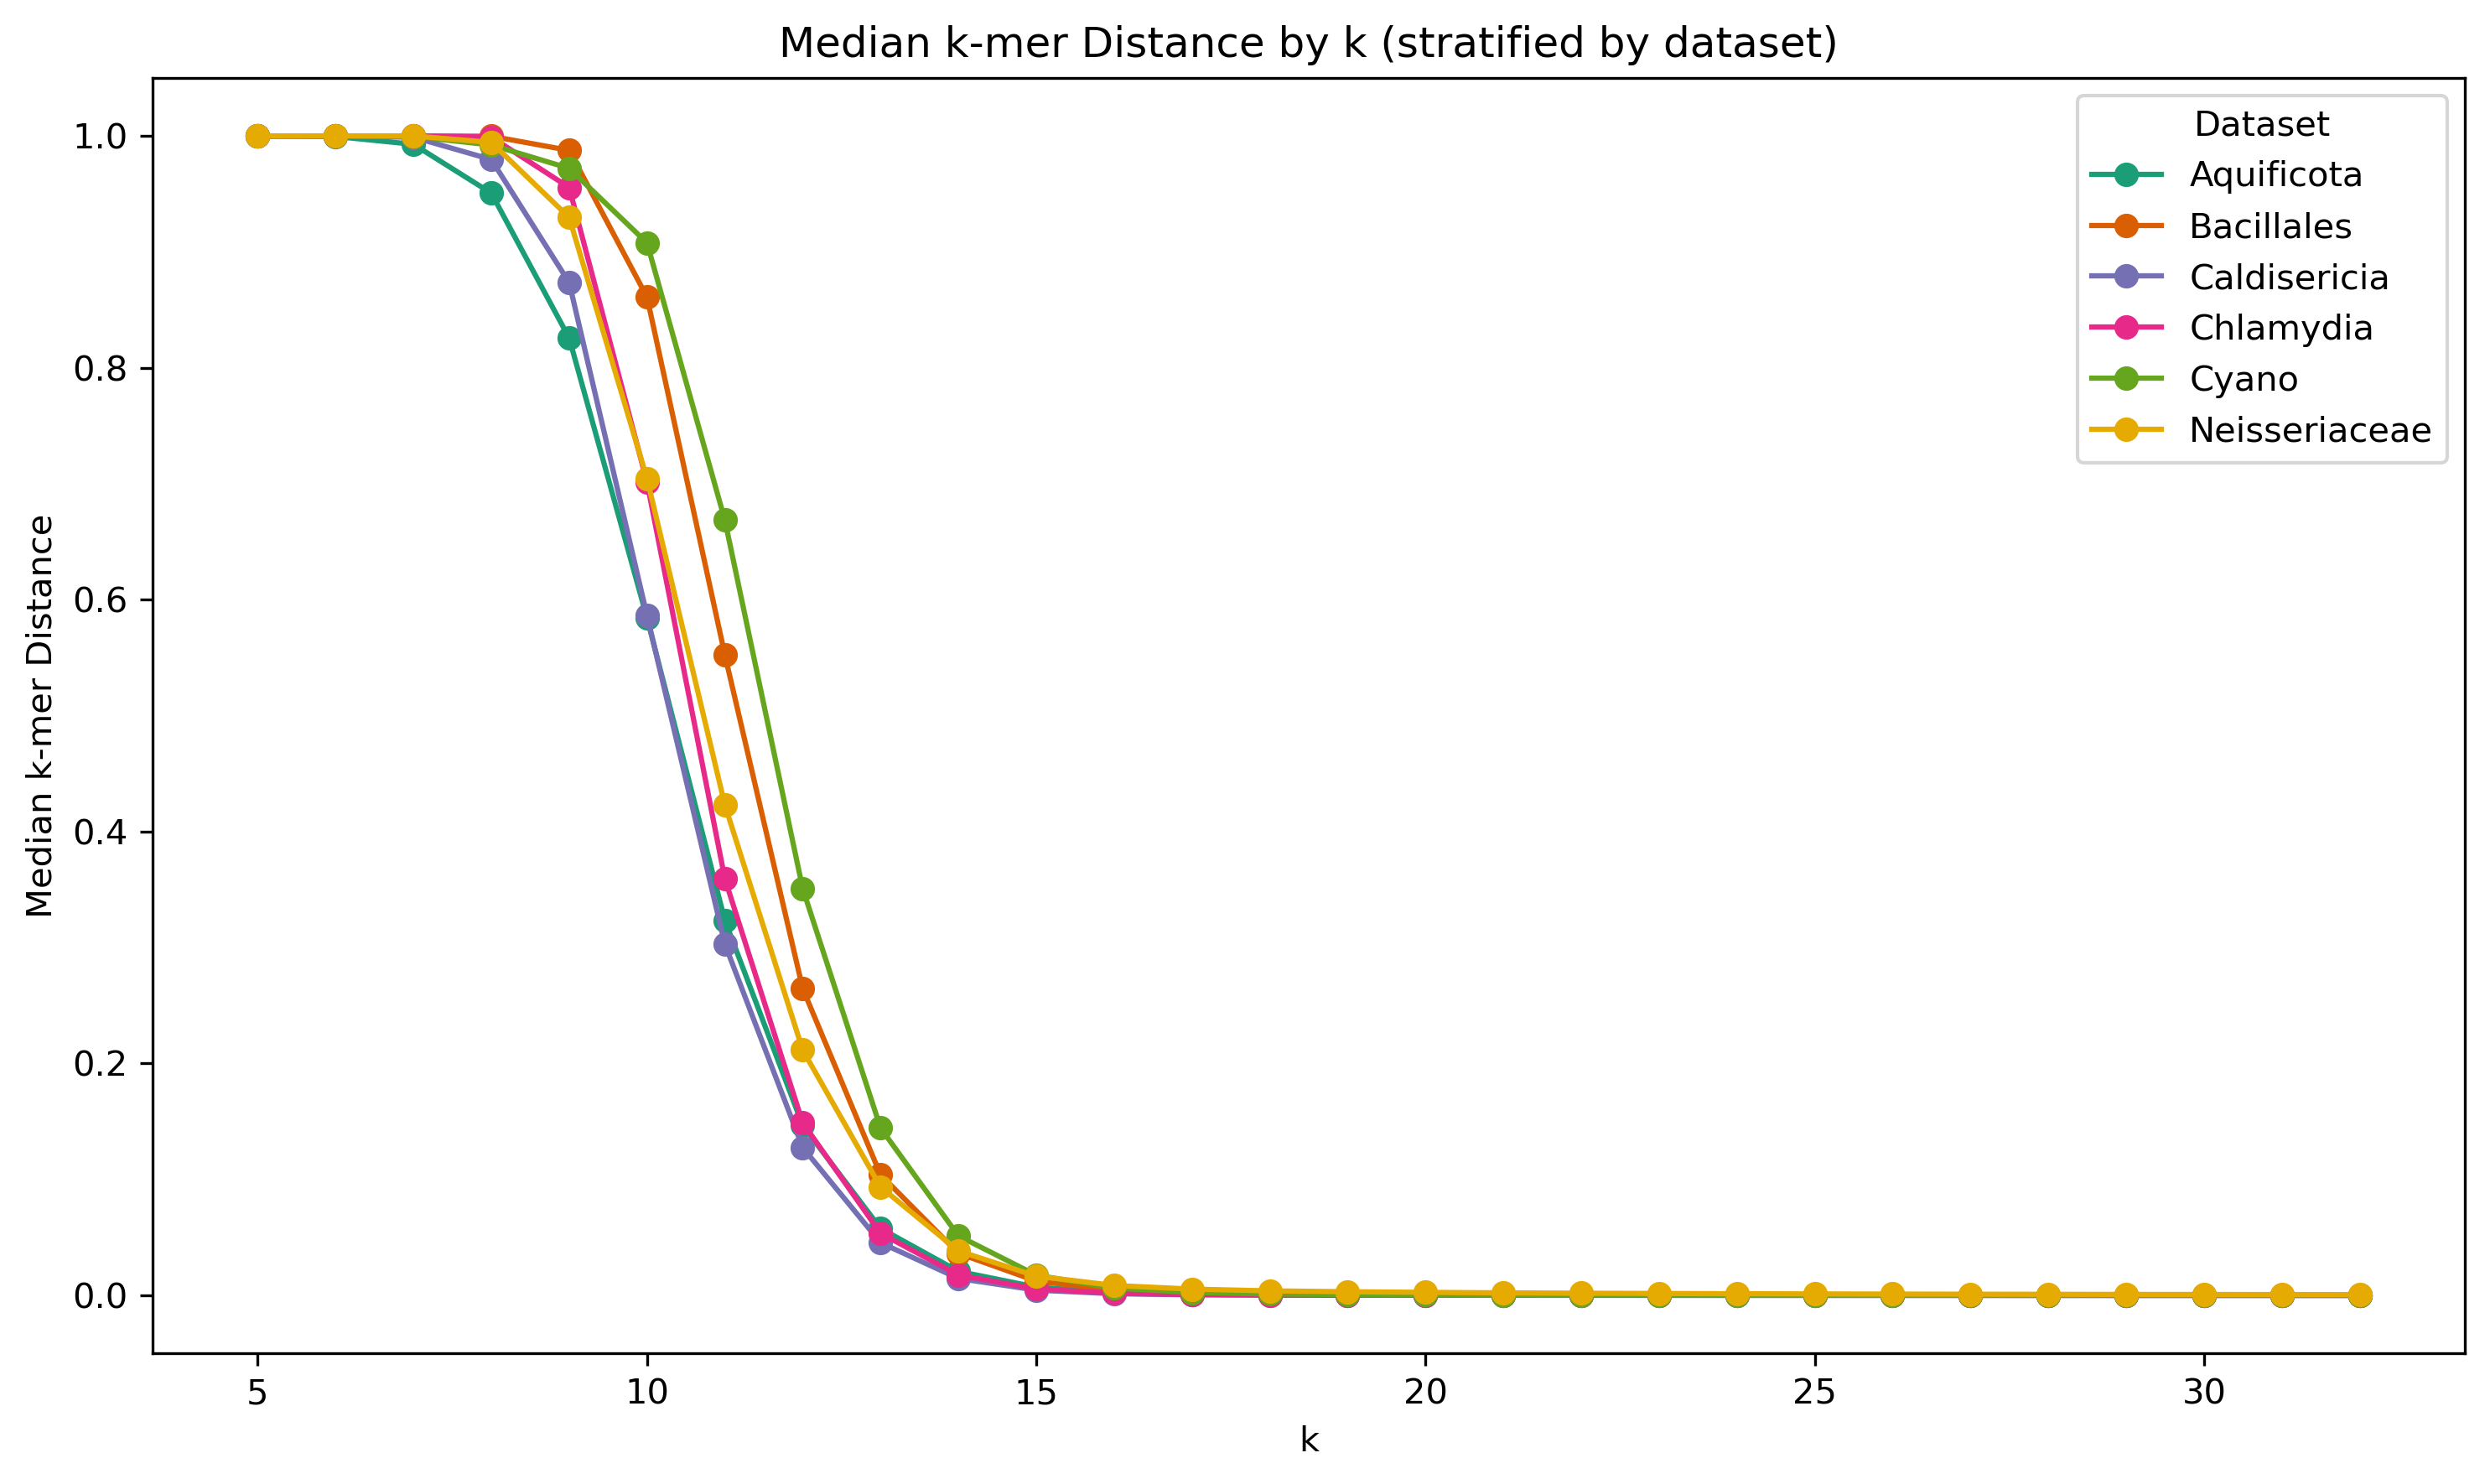

In [19]:
k_medians_records = []
for name, df in datasets:
    print(f"Plotting k-mer distances for {name}")
    medians = calc_k_medians(df, k_min=5, k_max=32)
    for k, median_val in medians.items():
        k_medians_records.append({"dataset": name, "k": k, "median": median_val})

k_medians_df = pd.DataFrame(k_medians_records)

################################################################################
# plot medians

colors = [ "#1b9e77", "#d95f02", "#7570b3", "#e7298a", "#66a61e", "#e6ab02" ]

fig, ax = plt.subplots(figsize=(10, 6))

for i, (dataset_name, df_subset) in enumerate(k_medians_df.groupby('dataset')):
    color = colors[i % len(colors)]
    ax.plot(df_subset['k'], df_subset['median'], marker='o', label=dataset_name, color=color)

ax.set_xlabel('k')
ax.set_ylabel('Median k-mer Distance')
ax.set_title('Median k-mer Distance by k (stratified by dataset)')
ax.legend(title='Dataset')
plt.tight_layout()
plt.show()


## Load and plot k-mer cardinality
f(G1, G2, k) = G1(k) U G2(k) / 4**k


In [14]:

def parse_union_cardinality_dashing_dfs(dir_path):
    """
    Parses all distance_* files in the given directory into a dictionary of pandas DataFrames.
    Each DataFrame skips the first line, assumes tab-separation and adjusts indices and columns as expected.

    Args:
        dir_path (str): Path to the directory containing distance_* files.

    Returns:
        dict: Dictionary mapping filename to corresponding DataFrame.
    """

    # Get list of files in directory that start with 'distance_'
    files = [f for f in os.listdir(dir_path) if os.path.isfile(os.path.join(dir_path, f)) and f.startswith('union_')]

    # Create a dictionary to store dataframes
    dashing_dfs = {}

    # Read each file into a dataframe, skipping first line
    for file in files:
        file_path = os.path.join(dir_path, file)
        try:
            # Skip first line and read tab-separated data
            df = pd.read_csv(file_path, sep='\t', header=None, skiprows=3)
            df.index = df.iloc[:, 0].str.replace('genomes_ncbi/', '')
            df = df.iloc[:, 1:]
            df.columns = df.index
            dashing_dfs[file] = df
            # print(f"Successfully read {file}")
        except Exception as e:
            print(f"Error reading {file}: {str(e)}")

    # Print summary of loaded dataframes
    print(f"\nLoaded {len(dashing_dfs)} files")
    for file, df in dashing_dfs.items():
        print(f"{file}: {df.shape}")
    return dashing_dfs


In [15]:

def build_merged_card_df(tree_dict, dashing_card_dfs):
    """
    Build merged dataframe for all genome pairs among `genomes`,
    including tree distances and distances for each k from `dashing_card_dfs`.

    Parameters:
    -----------
    tree_dict : dict
        Nested dictionary of tree-based distances; tree_dict[g1][g2] gives distance.
    dashing_card_dfs : dict
        Mapping from dashing file name to pairwise distance DataFrame.

    Returns:
    --------
    merged_card_df : pd.DataFrame
        DataFrame indexed by sorted genome pairs, with metadata and k-mer distances.
    """

    genomes = sorted(tree_dict.keys())

    # Create all pairs of genomes (upper triangle only, sorted lexicographically)
    pairs = []
    for i in range(len(genomes)):
        for j in range(i+1, len(genomes)):
            pair = '_'.join(sorted([genomes[i], genomes[j]]))
            pairs.append(pair)

    # Initialize dataframe with pairs as index
    merged_card_df = pd.DataFrame(index=pairs)

    # Add metadata columns to merged_card_df
    genome_pairs = []
    genomes_1s = []
    genomes_2s = []
    tree_distances = []
    for index in merged_card_df.index:
        # Split the genome pair
        genome1 = "_".join(index.split("_", 2)[:2])
        genome2 = "_".join(index.split("_", 2)[2:])

        # Get distance from tree_dict
        genome_pairs.append(index)
        genomes_1s.append(genome1)
        genomes_2s.append(genome2)
        tree_distances.append(tree_dict[genome1][genome2])

    merged_card_df['genome_pair'] = genome_pairs
    merged_card_df['genome_1'] = genomes_1s
    merged_card_df['genome_2'] = genomes_2s
    merged_card_df['tree_distance'] = tree_distances

    print(f"Final dataframe shape: {merged_card_df.shape}")

    # For each k, add a column to merged_card_df with the pairwise distances
    for fname, df in dashing_card_dfs.items():
        k_val = int(str(fname).replace('union_k', '').replace('.txt', ''))
        # Build a dictionary mapping sorted genome pair -> distance
        pair_to_dist = {}
        for i in range(len(df)):
            g1 = df.iloc[i].name
            for g2, d in dict(df.iloc[i]).items():
                if g1 == g2: continue
                pair = '_'.join(sorted([g1, g2]))
                pair_to_dist[pair] = d

        # Map the distances to the merged_card_df for this k
        colname = f'k{k_val}_cardinality'
        merged_card_df[colname] = merged_card_df.index.map(pair_to_dist.get)

        print(f"Added column '{colname}' to merged_card_df.")
        if k_val % 2 == 0: # k-mer is even
            num_pal = 4**(k_val/2)
            num_distinct_kmers = (4**k_val - num_pal) / 2 + num_pal
        else:
            num_distinct_kmers = 4**k_val / 2

        merged_card_df[colname] = merged_card_df[colname] / num_distinct_kmers # 4**k_val     # NOTE: normalize to 4**k

    return merged_card_df

def process_card_data(tree_path, dashing_dir_path):
    tree_dict = make_tree_dict(tree_path)
    dashing_card_dfs = parse_union_cardinality_dashing_dfs(dashing_dir_path)
    merged_card_df = build_merged_card_df(tree_dict, dashing_card_dfs)
    return tree_dict, dashing_card_dfs, merged_card_df


def plot_kmer_dashing_card(merged_card_df, k_min=5, k_max=64):
    """
    Plot k-mer cardinality boxplots for columns k{k}_distance in merged_card_df.

    Parameters
    ----------
    merged_card_df : pandas.DataFrame
        DataFrame containing columns like 'k5_distance', ..., 'k64_distance'.
    k_min : int, optional
        Minimum k to start from (default is 5).
    k_max : int, optional
        Maximum k to end at (default is 64).
    """
    data = []
    labels = []
    for k in range(k_min, k_max + 1):
        col = f"k{k}_cardinality"
        if col in merged_card_df.columns:
            data.append(merged_card_df[col].dropna())
            labels.append(f"k{k}")

    plt.figure(figsize=(max(12, len(labels) * 0.4), 6))
    plt.boxplot(data, labels=labels, showfliers=False)
    plt.xticks(rotation=90)
    plt.ylabel("k-mer cardinality / k-mer length")
    plt.title(f"k-mer cardinality (k = {k_min}..{k_max})")
    plt.tight_layout()
    plt.show()


def plot_kmer_dashing_card_zoom(merged_card_df, k_min=5, k_max=64):
    """
    Plot k-mer cardinality boxplots for columns k{k}_distance in merged_card_df.
    Overlay a zoomed-in region of k13..k32 with y-axis as 0..0.1 in the upper right.
    """
    import matplotlib.pyplot as plt

    data = []
    labels = []
    for k in range(k_min, k_max + 1):
        col = f"k{k}_cardinality"
        if col in merged_card_df.columns:
            data.append(merged_card_df[col].dropna())
            labels.append(f"k{k}")

    fig, ax = plt.subplots(figsize=(max(12, len(labels) * 0.4), 6))
    ax.boxplot(data, labels=labels, showfliers=False)
    ax.set_xticklabels(labels, rotation=90)
    ax.set_ylabel("k-mer cardinality / k-mer length")
    ax.set_title(f"k-mer cardinality (k = {k_min}..{k_max})")
    plt.tight_layout()


    # Overlay zoomed-in region as an inset
    # Inset: Find indices of k14 to k32 in our labels list
    k_from, k_to = 14, 32
    inset_indices = [i for i, label in enumerate(labels)
                     if label.startswith("k") and k_from <= int(label[1:]) <= k_to]
    if inset_indices:
        inset_data = [data[i] for i in inset_indices]
        inset_labels = [labels[i] for i in inset_indices]
        # Place the inset in the upper right
        axins = inset_axes(ax, width="36%", height="65%", loc="upper right",
                           bbox_to_anchor=(0, 0, 1, 1),
                           bbox_transform=ax.transAxes)
        axins.boxplot(inset_data, labels=inset_labels, showfliers=False)
        axins.set_ylim(0, 0.00125)
        axins.set_xticklabels(inset_labels, rotation=90, fontsize=8)
        axins.set_ylabel("")
        # axins.set_yticks([0, 0.05, 0.1])
        axins.tick_params(axis='y', labelsize=8)
        axins.set_title(f"k={k_from}..{k_to}", fontsize=9)

    plt.show()


In [17]:
aquificota_dir_path = '/scratch4/blangme2/sjhwang/ok_k_mer/data/aquificota/union_cardinality'
bacillales_dir_path = '/scratch4/blangme2/sjhwang/ok_k_mer/data/bacillales/union_cardinality'
caldisericia_dir_path = '/scratch4/blangme2/sjhwang/ok_k_mer/data/caldisericia/union_cardinality'
chlamydia_dir_path = '/scratch4/blangme2/sjhwang/ok_k_mer/data/chlamydiales/union_cardinality'
cyano_dir_path = '/scratch4/blangme2/sjhwang/ok_k_mer/data/cyanobacteriales/union_cardinality'
neisseriaceae_dir_path = '/scratch4/blangme2/sjhwang/ok_k_mer/data/neisseriaceae/union_cardinality'

aquificota_tree_path = '/scratch4/blangme2/sjhwang/ok_k_mer/data/aquificota/p__Aquificota.nwk'
bacillales_tree_path = '/scratch4/blangme2/sjhwang/ok_k_mer/data/bacillales/o__Bacillales_A.nwk'
caldisericia_tree_path = '/scratch4/blangme2/sjhwang/ok_k_mer/data/caldisericia/c__Caldisericia.nwk'
chlamydia_tree_path = '/scratch4/blangme2/sjhwang/ok_k_mer/data/chlamydiales/o__Chlamydiales.nwk'
cyano_tree_path = '/scratch4/blangme2/sjhwang/ok_k_mer/data/cyanobacteriales/o__Cyanobacteriales.nwk'
neisseriaceae_tree_path = '/scratch4/blangme2/sjhwang/ok_k_mer/data/neisseriaceae/f__Neisseriaceae.nwk'

aquificota_tree_dict, aquificota_dashing_dfs, aquificota_merged_df = process_card_data(aquificota_tree_path, aquificota_dir_path)
bacillales_tree_dict, bacillales_dashing_dfs, bacillales_merged_df = process_card_data(bacillales_tree_path, bacillales_dir_path)
caldisericia_tree_dict, caldisericia_dashing_dfs, caldisericia_merged_df = process_card_data(caldisericia_tree_path, caldisericia_dir_path)
chlamydia_tree_dict, chlamydia_dashing_dfs, chlamydia_merged_df = process_card_data(chlamydia_tree_path, chlamydia_dir_path)
cyano_tree_dict, cyano_dashing_dfs, cyano_merged_df = process_card_data(cyano_tree_path, cyano_dir_path)
neisseriaceae_tree_dict, neisseriaceae_dashing_dfs, neisseriaceae_merged_df = process_card_data(neisseriaceae_tree_path, neisseriaceae_dir_path)


# Prepare a list of all available merged_dfs and their names
datasets = [
    ("Aquificota", aquificota_merged_df),
    # ("Bacillales", bacillales_merged_df),
    ("Caldisericia", caldisericia_merged_df),
    # ("Chlamydia", chlamydia_merged_df),
    # ("Cyano", cyano_merged_df),
    ("Neisseriaceae", neisseriaceae_merged_df),
]


Loaded 60 files
union_k38.txt: (132, 132)
union_k64.txt: (132, 132)
union_k60.txt: (132, 132)
union_k16.txt: (132, 132)
union_k45.txt: (132, 132)
union_k63.txt: (132, 132)
union_k44.txt: (132, 132)
union_k5.txt: (132, 132)
union_k42.txt: (132, 132)
union_k25.txt: (132, 132)
union_k30.txt: (132, 132)
union_k33.txt: (132, 132)
union_k52.txt: (132, 132)
union_k48.txt: (132, 132)
union_k32.txt: (132, 132)
union_k9.txt: (132, 132)
union_k40.txt: (132, 132)
union_k20.txt: (132, 132)
union_k21.txt: (132, 132)
union_k8.txt: (132, 132)
union_k18.txt: (132, 132)
union_k46.txt: (132, 132)
union_k15.txt: (132, 132)
union_k54.txt: (132, 132)
union_k37.txt: (132, 132)
union_k56.txt: (132, 132)
union_k57.txt: (132, 132)
union_k61.txt: (132, 132)
union_k31.txt: (132, 132)
union_k43.txt: (132, 132)
union_k12.txt: (132, 132)
union_k28.txt: (132, 132)
union_k36.txt: (132, 132)
union_k50.txt: (132, 132)
union_k24.txt: (132, 132)
union_k6.txt: (132, 132)
union_k51.txt: (132, 132)
union_k7.txt: (132, 132)


Plotting k-mer cardinality for Aquificota


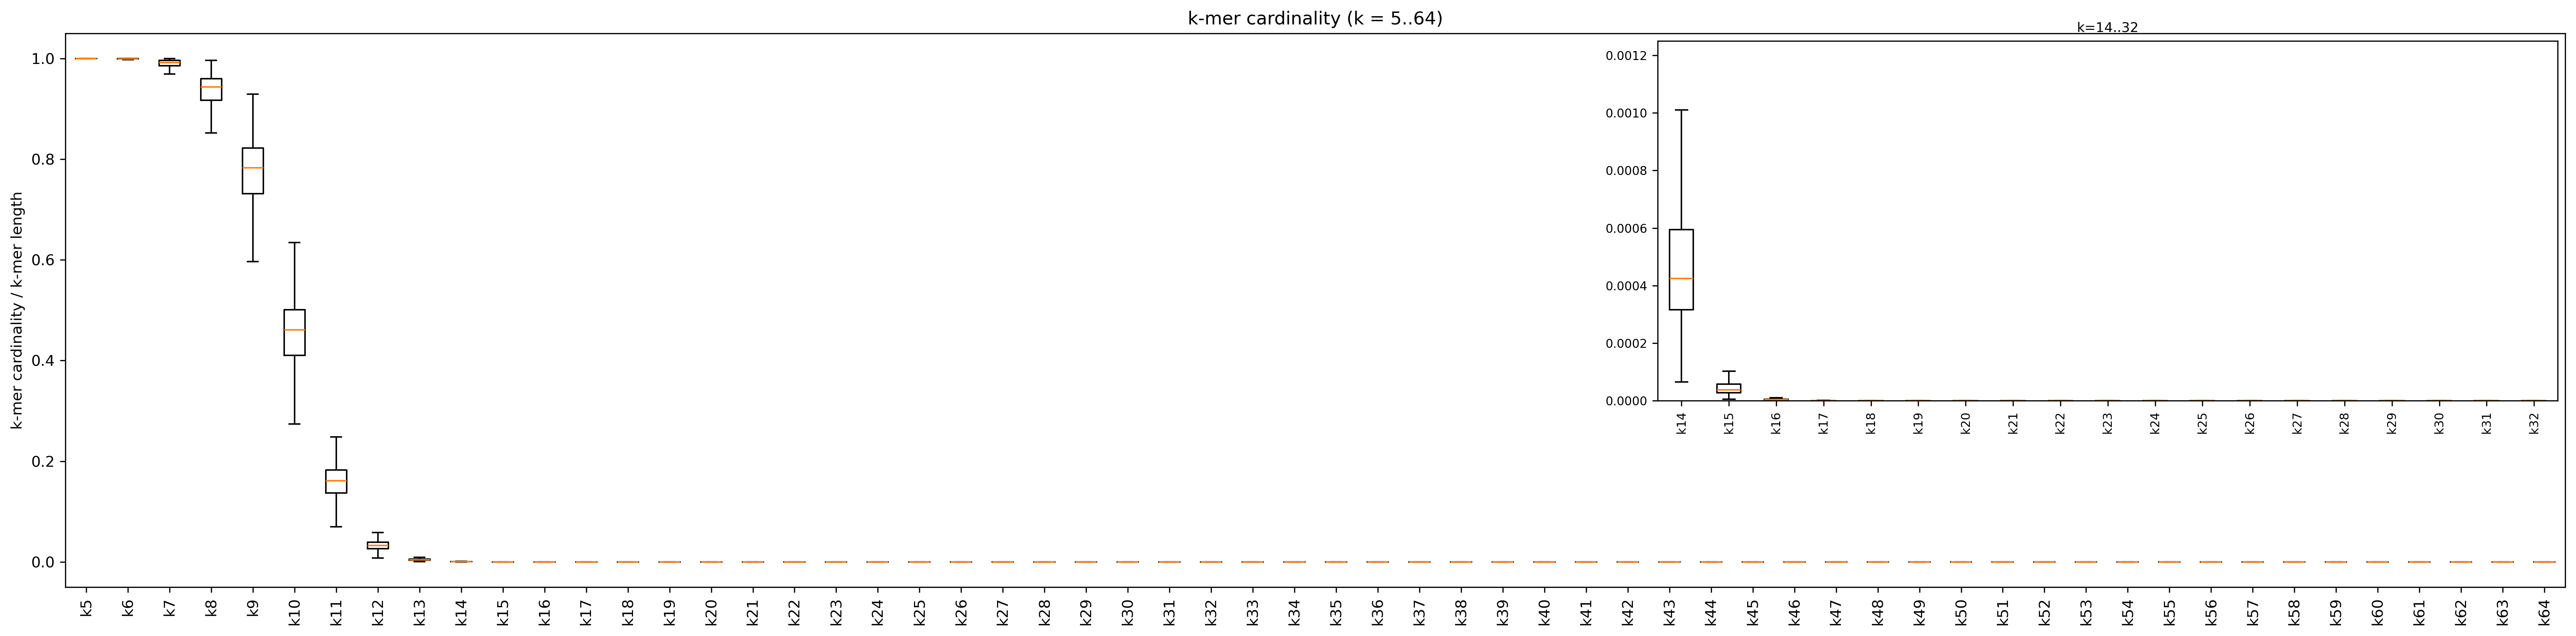

Plotting k-mer cardinality for Caldisericia


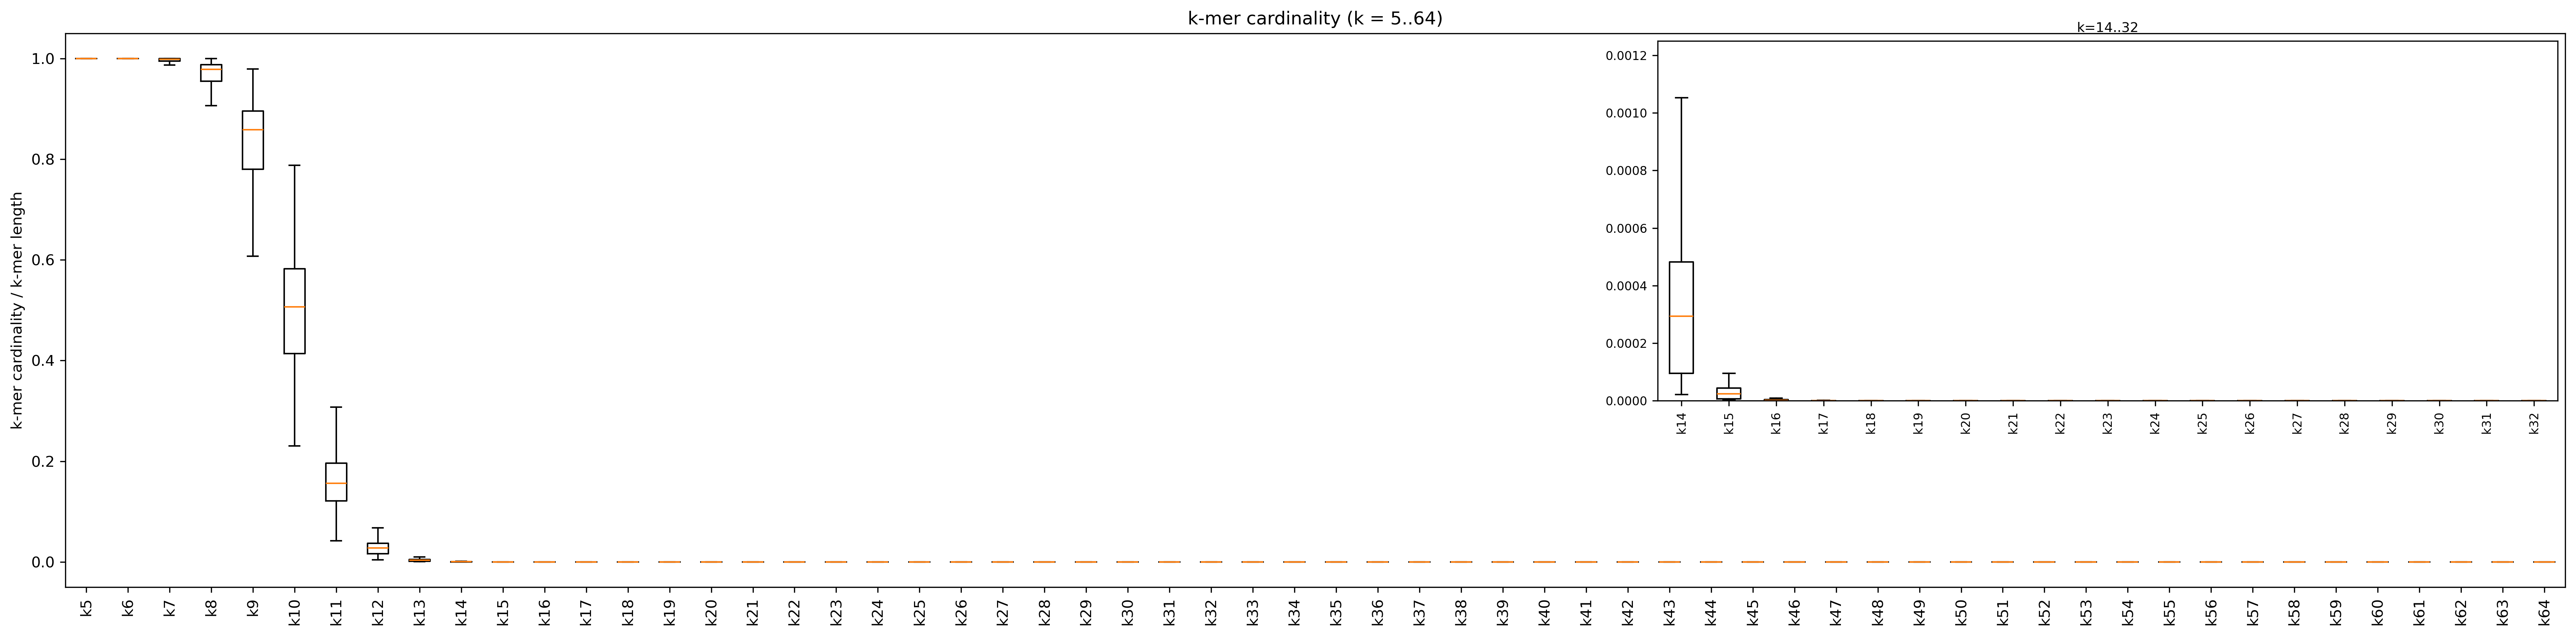

Plotting k-mer cardinality for Neisseriaceae


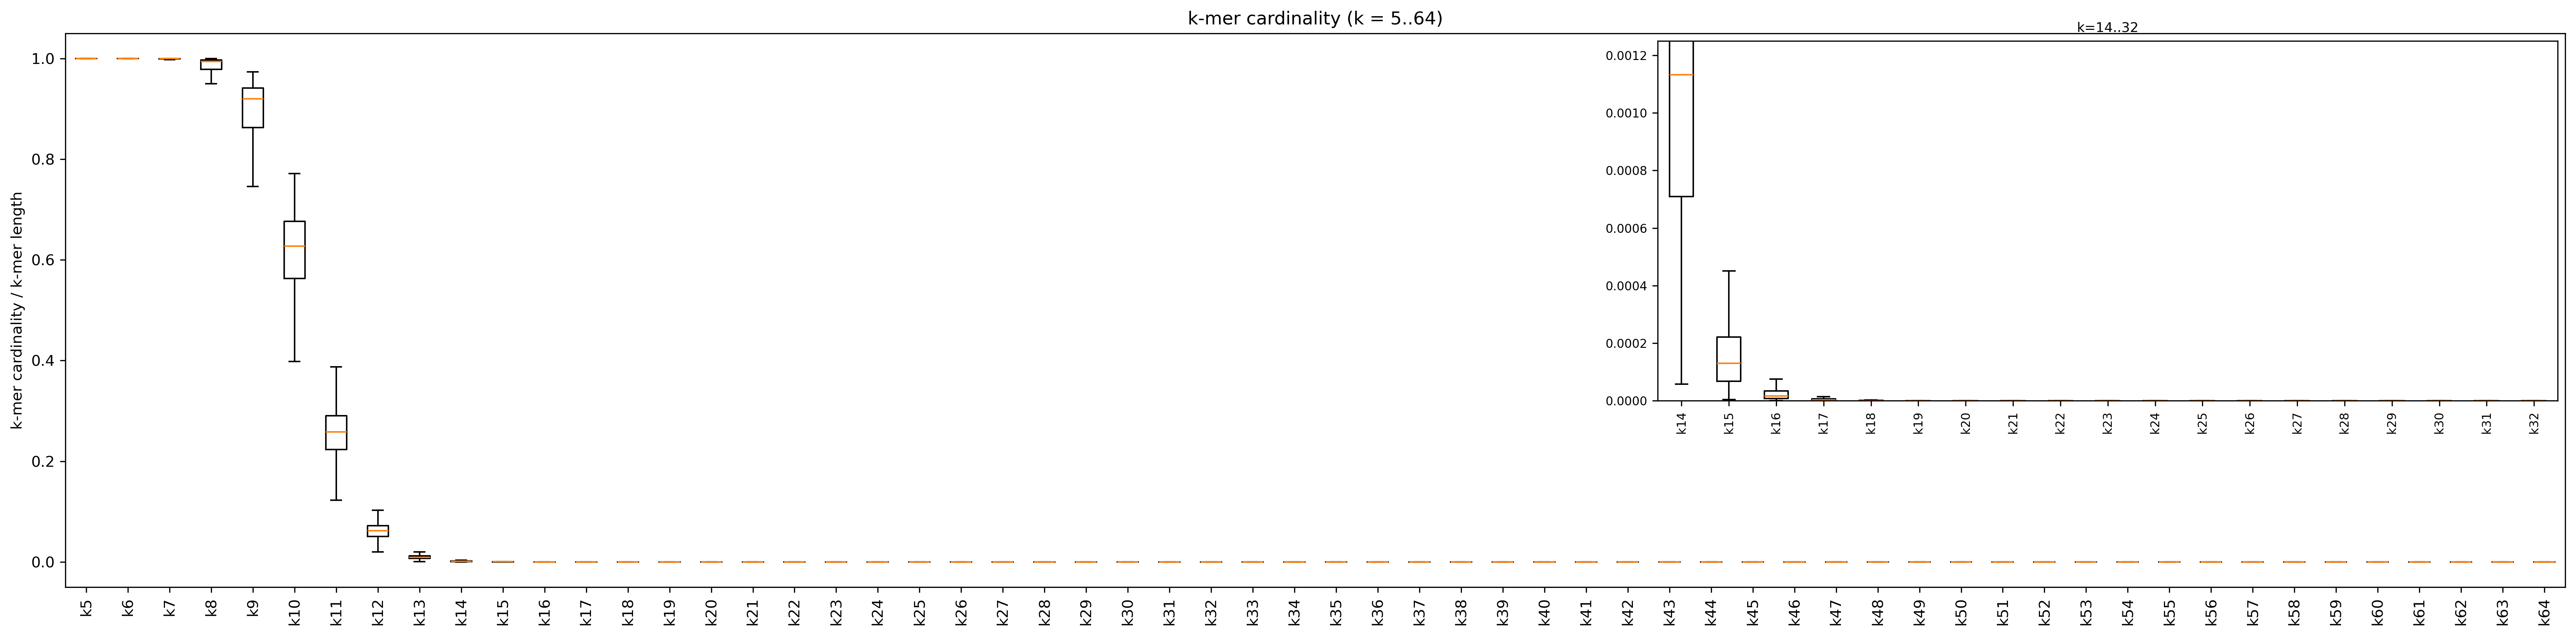

In [24]:
# plot k-mer cardinalities

zoom = True # zoom = False
k_min = 5
k_max = 64

for name, df in datasets:
    print(f"Plotting k-mer cardinality for {name}")
    if zoom:
        plot_kmer_dashing_card_zoom(df, k_min=k_min, k_max=k_max)
    else:
        plot_kmer_dashing_card(df, k_min=k_min, k_max=k_max)


## Tree annotated by k-mer recs


# Scratch

## 3+ k-mer correlation

### Idea:

Iteration 1 and 2:
* take the best k-mer
* find the average rank with the other k-mers
* when find the best two, weight the ranks

Iteration 3+:
* take the k-mer recommendation from the previous iteration
* next k-mer is added with weight: ((k1*w1 + k2*w2) * (num_k/ 100)) + kn * (100 - num_k)/100
* then when find that that does better: ((k1*w1 + k2*w2) * (num_k/ 100)) * wn + kn * (100 - num_k)/100 * (1-wn)

keep iterating until the correlation is no longer improving

output is:
* (k1,w1), (k2,w2), ... , (kn,wn)
* correlation of the best weighted rank of k-mers

In [ ]:
# modifying to be recursive

def initial_corr(merged_df, iteration=0, k_low=5, k_high=32):
    ''' '''
    results_matrix = np.zeros((k_high - k_low + 1, 3 + iteration))
    for i, k in enumerate(range(k_low, k_high + 1)):
        k_rank = merged_df[f'k{k}_distance'].rank()
        corr, pval = spearmanr(k_rank, merged_df['tree_distance'])
        results_matrix[i, :] = [k, corr, pval]
    min_idx = np.nanargmin(results_matrix[:,-2])
    return (int(results_matrix[min_idx][0]), *results_matrix[min_idx][1:3]), iteration, results_matrix


def two_plus(merged_df, ks, results_matrix_prev, iteration, k_low=5, k_high=32):
    ''' '''
    iteration += 1
    results_matrix = np.zeros((k_high - k_low + 1, 3 + iteration))

    if iteration >= 1:
        ranks = []
        for k in ks:
            ranks.append(merged_df[f'k{k}_distance'].rank())
        # then within ranks

            # k_fixed_rank = merged_df[f'k{fixed_ks}_distance'].rank()


    for i, k in enumerate(range(k_low, k_high + 1)):
        k_rank = merged_df[f'k{k}_distance'].rank()
        corr, pval = spearmanr(k_rank, merged_df['tree_distance'])
        results_matrix[i, :] = [k, corr, pval]
    min_idx = np.nanargmin(results_matrix[:,-2])
    return (int(results_matrix[min_idx][0]), *results_matrix[min_idx][1:3]), iteration, results_matrix


    k_fixed_ith = ks[0]
    k_fixed_rank = merged_df[f'k{k_fixed_ith}_distance'].rank()

    nan_rows = np.unique(np.argwhere(np.isnan(results_matrix_prev))[:,0])
    nan_ks = set(map(int, results_matrix_prev[nan_rows][:,0]))

    for i, k in enumerate(range(k_low, k_high + 1)):
        k_rank = merged_df[f'k{k}_distance'].rank()
        if k in nan_ks:  # skip nan ks
            results_matrix[i, :] = [k_fixed_ith, k, np.nan, np.nan]
        else:
            avg_rank = (k_fixed_rank + k_rank) / 2    # average the ranks
            corr, pval = calc_corr(avg_rank, merged_df['tree_distance'], prnt=False)
            results_matrix[i, :] = [k_fixed_ith, k, corr, pval]
    min_idx = np.nanargmin(results_matrix[:,-2])
    return results_matrix, (int(results_matrix[min_idx][0]), int(results_matrix[min_idx][1]), *results_matrix[min_idx][1:3])



def double_k_corr(merged_df, ks, results_matrix_prev, k_low=5, k_high=32):
    ''' '''
    num_k = len(ks) + 1
    k_fixed_ith = ks[0]
    results_matrix = np.zeros((k_high - k_low + 1, 2 + num_k))
    k_fixed_rank = merged_df[f'k{k_fixed_ith}_distance'].rank()

    nan_rows = np.unique(np.argwhere(np.isnan(results_matrix_prev))[:,0])
    nan_ks = set(map(int, results_matrix_prev[nan_rows][:,0]))

    for i, k in enumerate(range(k_low, k_high + 1)):
        k_rank = merged_df[f'k{k}_distance'].rank()
        if k in nan_ks:  # skip nan ks
            results_matrix[i, :] = [k_fixed_ith, k, np.nan, np.nan]
        else:
            avg_rank = (k_fixed_rank + k_rank) / 2    # average the ranks
            corr, pval = calc_corr(avg_rank, merged_df['tree_distance'], prnt=False)
            results_matrix[i, :] = [k_fixed_ith, k, corr, pval]
    min_idx = np.nanargmin(results_matrix[:,-2])
    return results_matrix, (int(results_matrix[min_idx][0]), int(results_matrix[min_idx][1]), *results_matrix[min_idx][1:3])


def double_k_corr_weighted(merged_df, ks, w_low=0, w_high=1, w_step=0.05):
    ''' '''
    ws = np.arange(w_low, w_high, w_step)
    num_k = len(ks) + 1
    k1 = ks[0]
    k2 = ks[1]

    results_matrix = np.zeros((len(ws), 2 + num_k))
    k1_rank = merged_df[f'k{k1}_distance'].rank()
    k2_rank = merged_df[f'k{k2}_distance'].rank()

    for i, w in enumerate(ws):
        avg_w_rank = w * k1_rank + (1 - w) * k2_rank   # weight the ranks by w and 1-w
        corr, pval = calc_corr(avg_w_rank, merged_df['tree_distance'], prnt=False)
        results_matrix[i, :] = [k1, k2, w, corr, pval]

    min_idx = np.nanargmin(results_matrix[:,-2])
    return results_matrix[min_idx]  # return results_matrix


################################################################################
# initial best-k

def run_iterative_search(merged_df):
    ''' adsf '''
    results_matrix_init, (k, corr, pval) = single_k_corr(merged_df)
    print('single-k:', k, corr, pval)

    # double k
    ks = [k]
    results_matrix_double, (k1, k2, corr, pval) = double_k_corr(merged_df, ks, results_matrix_init)
    print('double-k:', k1, k2, corr, pval)

    # double k, weighted
    ks = [k1, k2]
    k1, k2, w, corr, pval = double_k_corr_weighted(merged_df, ks)
    print('double-k, weighted', k1, k2, w, corr, pva)


# merged_df = cyano_merged_df
# merged_df = chlamydia_merged_df
run_iterative_search(chlamydia_merged_df)

In [68]:
# this is good, working

def single_k_corr(merged_df, k_low=5, k_high=32):
    ''' '''
    num_k = 1
    results_matrix = np.zeros((k_high - k_low + 1, 2 + num_k))
    for i, k in enumerate(range(k_low, k_high + 1)):
        k_rank = merged_df[f'k{k}_distance'].rank()
        corr, pval = calc_corr(k_rank, merged_df['tree_distance'], prnt=False)
        results_matrix[i, :] = [k, corr, pval]
    min_idx = np.nanargmin(results_matrix[:,-2])
    return results_matrix, (int(results_matrix[min_idx][0]), *results_matrix[min_idx][1:3])


def double_k_corr(merged_df, ks, results_matrix_prev, k_low=5, k_high=32):
    ''' '''
    num_k = len(ks) + 1
    k_fixed_ith = ks[0]
    results_matrix = np.zeros((k_high - k_low + 1, 2 + num_k))
    k_fixed_rank = merged_df[f'k{k_fixed_ith}_distance'].rank()

    nan_rows = np.unique(np.argwhere(np.isnan(results_matrix_prev))[:,0])
    nan_ks = set(map(int, results_matrix_prev[nan_rows][:,0]))

    for i, k in enumerate(range(k_low, k_high + 1)):
        k_rank = merged_df[f'k{k}_distance'].rank()
        if k in nan_ks:  # skip nan ks
            results_matrix[i, :] = [k_fixed_ith, k, np.nan, np.nan]
        else:
            avg_rank = (k_fixed_rank + k_rank) / 2    # average the ranks
            corr, pval = calc_corr(avg_rank, merged_df['tree_distance'], prnt=False)
            # results_matrix[i, :] = [int(k_fixed_ith), int(k), corr, pval]
            results_matrix[i, :] = [k_fixed_ith, k, corr, pval]
    min_idx = np.nanargmin(results_matrix[:,-2])
    print(results_matrix)
    return results_matrix, results_matrix[min_idx]
    #(int(results_matrix[min_idx][0]), int(results_matrix[min_idx][1]), *results_matrix[min_idx][1:3])

def double_k_corr_weighted(merged_df, ks, w_low=0.5, w_high=1, w_step=0.05):
    ''' '''
    ws = np.arange(w_low, w_high, w_step)
    num_k = len(ks) + 1
    k1, k2 = map(int, ks)
    k1_rank = merged_df[f'k{k1}_distance'].rank()
    k2_rank = merged_df[f'k{k2}_distance'].rank()

    results_matrix = np.zeros((len(ws), 2 + num_k))
    for i, w in enumerate(ws):
        avg_w_rank = w * k1_rank + (1 - w) * k2_rank   # weight the ranks by w and 1-w
        corr, pval = calc_corr(avg_w_rank, merged_df['tree_distance'], prnt=False)
        results_matrix[i, :] = [k1, k2, w, corr, pval]

    min_idx = np.nanargmin(results_matrix[:,-2])
    # print(results_matrix)
    return results_matrix[min_idx]  # return results_matrix


################################################################################
# initial best-k

def run_iterative_search(merged_df):
    ''' adsf '''
    results_matrix_init, (k, corr, pval) = single_k_corr(merged_df)
    print('single-k:', k, corr, pval)

    # double k
    ks = [k]
    results_matrix_double, (k1, k2, corr, pval) = double_k_corr(merged_df, ks, results_matrix_init)
    print('double-k:', int(k1), int(k2), corr, pval)

    # double k, weighted
    ks = [k1, k2]
    k1, k2, w, corr, pval = double_k_corr_weighted(merged_df, ks)
    print('double-k, weighted', int(k1), int(k2), w, corr, pval)


In [69]:
# Prepare a list of all available merged_dfs and their names
datasets = [
    ("Aquificota", aquificota_merged_df),
    ("Bacillales", bacillales_merged_df),
    ("Caldisericia", caldisericia_merged_df),
    ("Chlamydia", chlamydia_merged_df),
    ("Cyano", cyano_merged_df),
    ("Neisseriaceae", neisseriaceae_merged_df),
]

for name, merged_df in datasets:
    print(name)
    run_iterative_search(merged_df)
    print()

Aquificota
single-k: 20 -0.690943518743017 0.0
[[20.          5.         -0.68087454  0.        ]
 [20.          6.         -0.49787844  0.        ]
 [20.          7.         -0.47308393  0.        ]
 [20.          8.         -0.48361285  0.        ]
 [20.          9.         -0.49034771  0.        ]
 [20.         10.         -0.53087735  0.        ]
 [20.         11.         -0.54634918  0.        ]
 [20.         12.         -0.54538681  0.        ]
 [20.         13.         -0.55392923  0.        ]
 [20.         14.         -0.56995184  0.        ]
 [20.         15.         -0.5931441   0.        ]
 [20.         16.         -0.62659889  0.        ]
 [20.         17.         -0.65814769  0.        ]
 [20.         18.         -0.67727693  0.        ]
 [20.         19.         -0.68821961  0.        ]
 [20.         20.         -0.69094352  0.        ]
 [20.         21.         -0.68957721  0.        ]
 [20.         22.         -0.68956224  0.        ]
 [20.         23.         -0.688342

/tmp/ipykernel_1455090/2107416139.py:5: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.


single-k: 24 -0.6985444519903102 0.0
[[24.          5.                 nan         nan]
 [24.          6.                 nan         nan]
 [24.          7.         -0.69893863  0.        ]
 [24.          8.         -0.45894171  0.        ]
 [24.          9.         -0.4777615   0.        ]
 [24.         10.         -0.52636992  0.        ]
 [24.         11.         -0.57117531  0.        ]
 [24.         12.         -0.57443049  0.        ]
 [24.         13.         -0.57528834  0.        ]
 [24.         14.         -0.58456104  0.        ]
 [24.         15.         -0.60255375  0.        ]
 [24.         16.         -0.62769746  0.        ]
 [24.         17.         -0.65306393  0.        ]
 [24.         18.         -0.6731032   0.        ]
 [24.         19.         -0.68539497  0.        ]
 [24.         20.         -0.69206094  0.        ]
 [24.         21.         -0.696261    0.        ]
 [24.         22.         -0.69801586  0.        ]
 [24.         23.         -0.69863248  0.    

## Analyze corrrelation


In [ ]:
# spearman rank for k to true distance for all pairs

def spearman_corr_against_tree(dfs_dict, tree_dict, sample_mask=[]):
    rows = []
    for fname, df in dfs_dict.items():
        # Derive k from filename when possible
        k_val = int(str(fname).replace('distance_k', '').replace('.txt', ''))
        names = list(df.index)
        x_dashing = []
        y_tree = []

        for i in range(len(names)):
            for j in range(i + 1, len(names)):
                raw1, raw2 = names[i], names[j]
                g1 = raw1.replace('genomes_ncbi/', '').rstrip('.fa')
                g2 = raw2.replace('genomes_ncbi/', '').rstrip('.fa')
                # Only analyze samples not in sample_mask
                if (g1 in sample_mask) or (g2 in sample_mask):
                    continue
                td = tree_dict[g1][g2]
                dashing_dist = float(df.loc[raw1, raw2])
                x_dashing.append(dashing_dist)
                y_tree.append(float(td))

        corr, pval = spearmanr(x_dashing, y_tree)
        rows.append({
            'k': k_val,
            'spearman_corr': corr,
            'p_value': pval,
            'n_pairs': len(x_dashing)
        })

    return pd.DataFrame(rows)

In [ ]:





def compute_kmer_avg_rank_corr(merged_df, k_ref=20):
    """
    Calculate Spearman correlations between tree distances and the *average rank*
    of a reference k-mer (default k=20) and all other k-mers in merged_df.

    Args:
        merged_df (pd.DataFrame): DataFrame with k-mer distances and tree_distance.
        k_ref (int, optional): Reference k-mer value (default=20).

    Returns:
        Tuple (k_values, combined_corrs, single_k_corrs)
            - k_values (list of int): k-mer values used (looped).
            - combined_corrs (list of float): Spearman correlations of avg. rank (k_ref & k).
            - single_k_corrs (list of float): Spearman correlations of single k only.
    """
    k_ref_ranks = merged_df[f'k{k_ref}_distance'].rank()

    k_values = []
    combined_corrs = []
    single_k_corrs = []

    for k in range(5, 33):
        k_mid_ranks = merged_df[f'k{k}_distance'].rank()
        avg_ranks = (k_mid_ranks + k_ref_ranks) / 2
        corr, pval = calc_corr(avg_ranks, merged_df['tree_distance'], prnt=False)
        print(f"k={k_ref},{k}: {corr}, {pval}")

        single_k_corr, _ = calc_corr(k_mid_ranks, merged_df['tree_distance'], prnt=False)

        k_values.append(k)
        combined_corrs.append(corr)
        single_k_corrs.append(single_k_corr)

    return k_values, combined_corrs, single_k_corrs


In [ ]:

def compute_kmer_avg_rank_corr(merged_df, k_ref=20):
    """
    Calculate Spearman correlations between tree distances and the *average rank*
    of a reference k-mer (default k=20) and all other k-mers in merged_df.

    Args:
        merged_df (pd.DataFrame): DataFrame with k-mer distances and tree_distance.
        k_ref (int, optional): Reference k-mer value (default=20).

    Returns:
        Tuple (k_values, combined_corrs, single_k_corrs)
            - k_values (list of int): k-mer values used (looped).
            - combined_corrs (list of float): Spearman correlations of avg. rank (k_ref & k).
            - single_k_corrs (list of float): Spearman correlations of single k only.
    """

    k_ref_ranks = merged_df[f'k{k_ref}_distance'].rank()

    k_values = []
    combined_corrs = []
    single_k_corrs = []

    for k in range(5, 33):
        k_mid_ranks = merged_df[f'k{k}_distance'].rank()
        avg_ranks = (k_mid_ranks + k_ref_ranks) / 2
        corr, pval = calc_corr(avg_ranks, merged_df['tree_distance'], prnt=False)
        print(f"k={k_ref},{k}: {corr}, {pval}")

        single_k_corr, _ = calc_corr(k_mid_ranks, merged_df['tree_distance'], prnt=False)

        k_values.append(k)
        combined_corrs.append(corr)
        single_k_corrs.append(single_k_corr)

    return k_values, combined_corrs, single_k_corrs


## 2+ k-mer correlation

In [15]:
def compute_kmer_avg_rank_corr(merged_df, k_ref=20):
    """
    Calculate Spearman correlations between tree distances and the *average rank*
    of a reference k-mer (default k=20) and all other k-mers in merged_df.

    Args:
        merged_df (pd.DataFrame): DataFrame with k-mer distances and tree_distance.
        k_ref (int, optional): Reference k-mer value (default=20).

    Returns:
        Tuple (k_values, combined_corrs, single_k_corrs)
            - k_values (list of int): k-mer values used (looped).
            - combined_corrs (list of float): Spearman correlations of avg. rank (k_ref & k).
            - single_k_corrs (list of float): Spearman correlations of single k only.
    """

    k_ref_ranks = merged_df[f'k{k_ref}_distance'].rank()

    k_values = []
    combined_corrs = []
    single_k_corrs = []

    for k in range(5, 33):
        k_mid_ranks = merged_df[f'k{k}_distance'].rank()
        avg_ranks = (k_mid_ranks + k_ref_ranks) / 2
        corr, pval = calc_corr(avg_ranks, merged_df['tree_distance'], prnt=False)
        print(f"k={k_ref},{k}: {corr}, {pval}")

        single_k_corr, _ = calc_corr(k_mid_ranks, merged_df['tree_distance'], prnt=False)

        k_values.append(k)
        combined_corrs.append(corr)
        single_k_corrs.append(single_k_corr)

    return k_values, combined_corrs, single_k_corrs


In [16]:

def plot_kmer_avg_rank_corr(k_values, combined_corrs, single_k_corrs, k_ref=20):
    """
    Plot the Spearman correlations as a function of k (single and averaged k-mer ranks).

    Args:
        k_values (list): List of k values.
        combined_corrs (list): Spearman correlations for average of k_ref & k.
        single_k_corrs (list): Spearman correlations for single k.
        title (str, optional): Plot title. If None, generates a default title using k_ref.
        k_ref (int, optional): Reference k-mer value (default=20).
    """

    combined_label = f"(k, {k_ref})-mer average"
    single_label = "Single k-mer"

    plot_df = pd.DataFrame({
        'k_value': k_values,
        'Combined k': combined_corrs,
        single_label: single_k_corrs
    })

    plot_df = pd.melt(plot_df,
                      id_vars=['k_value'],
                      value_vars=['Combined k', single_label],
                      var_name='Method',
                      value_name='correlation')

    plot_df['Method'] = plot_df['Method'].replace({single_label: single_label, 'Combined k': combined_label})

    plot = (
        ggplot(plot_df) +
        geom_point(aes(x='k_value', y='correlation', color='Method'), alpha=0.8) +
        geom_line(aes(x='k_value', y='correlation', color='Method', group='Method'), alpha=0.8) +
        ggtitle(f"Dashing Jaccard index:\nSingle k-mer and (k, {k_ref})-mer average") +
        xlab("k-mer Jaccard length") +
        ylab("Spearman correlation") +
        theme_tufte_func(base_size=15, rotate=False, figure_size=(8, 5)) +
        scale_x_continuous(breaks=range(5,33,2)) +
        scale_color_manual(values=['#000000', '#D7263D'],
                          breaks=[single_label, combined_label])
    )
    return plot


In [17]:

# tree_dict =
# tree_dict =
# spearman_corr_against_tree(dfs_dict, tree_dict)

# chlamydia_tree_dict, chlamydia_dashing_dfs, chlamydia_merged_df = process_data(chlamydia_tree_path, chlamydia_dir_path)
spearman_corr_against_tree(chlamydia_dashing_dfs, chlamydia_tree_dict)


/tmp/ipykernel_253981/2278004018.py:25: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.


,k,spearman_corr,p_value,n_pairs
0,10,-0.344365,0.000000e+00,41328
1,11,-0.341808,0.000000e+00,41328
2,12,-0.291268,0.000000e+00,41328
3,13,-0.243907,0.000000e+00,41328
4,14,-0.228658,0.000000e+00,41328
5,15,-0.247307,0.000000e+00,41328
6,16,-0.304448,0.000000e+00,41328
7,17,-0.366936,0.000000e+00,41328
8,18,-0.398111,0.000000e+00,41328
9,19,-0.418595,0.000000e+00,41328


k=23,5: -0.698469637136924, 0.0
k=23,6: -0.698469637136924, 0.0
k=23,7: -0.6990298323382885, 0.0
k=23,8: -0.4598236967885044, 0.0
k=23,9: -0.47829313126756506, 0.0
k=23,10: -0.5264285489841093, 0.0
k=23,11: -0.5702784650543486, 0.0
k=23,12: -0.5727902362108572, 0.0
k=23,13: -0.5732296272037366, 0.0
k=23,14: -0.5824296986451096, 0.0
k=23,15: -0.6004681266193658, 0.0


/tmp/ipykernel_253981/2107416139.py:5: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.


k=23,16: -0.6257610294921394, 0.0
k=23,17: -0.6513948782865829, 0.0
k=23,18: -0.671771488724292, 0.0
k=23,19: -0.6843163027799688, 0.0
k=23,20: -0.6912551694310475, 0.0
k=23,21: -0.6956852281497259, 0.0
k=23,22: -0.6976278076953074, 0.0
k=23,23: -0.698469637136924, 0.0
k=23,24: -0.6986324780805152, 0.0
k=23,25: -0.6981524342843938, 0.0
k=23,26: -0.6972930986153184, 0.0
k=23,27: -0.6960448484671206, 0.0
k=23,28: -0.6948657187166338, 0.0
k=23,29: -0.693506947082278, 0.0
k=23,30: -0.6919559399073655, 0.0
k=23,31: -0.6904990361735708, 0.0
k=23,32: -0.6889560866213216, 0.0


/home/shwang45/miniconda3/envs/python310/lib/python3.10/site-packages/plotnine/layer.py:364: PlotnineWarning: geom_point : Removed 2 rows containing missing values.


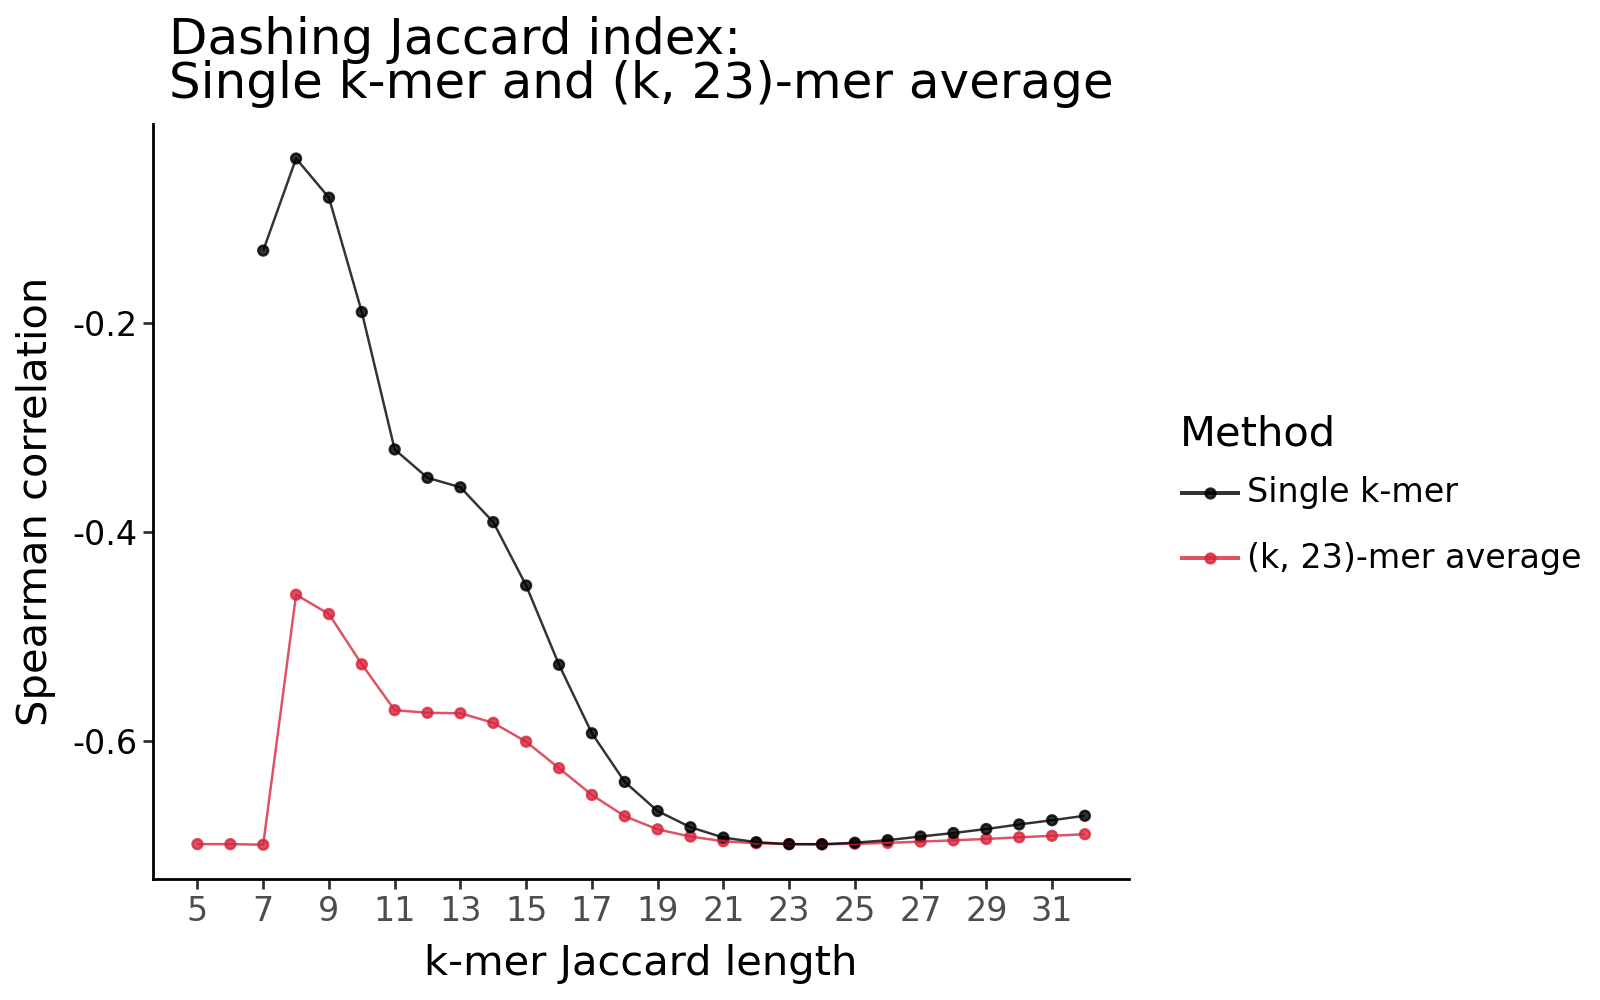

In [18]:
k_ref = 23
merged_df = bacillales_merged_df

k_values, combined_corrs, single_k_corrs = compute_kmer_avg_rank_corr(merged_df, k_ref)
plot_kmer_avg_rank_corr(k_values, combined_corrs, single_k_corrs, k_ref)

In [18]:
# genomes =
from itertools import permutations

x = list(permutations(chlam_sample_names, 2))

NameError: name 'chlam_sample_names' is not defined

In [ ]:
# Spearman rank correlation: average distance ranks vs. true tree distances

from scipy.stats import spearmanr

k1 = 11
k2 = 20

df1 = chlam_dashing_dfs['distance_k'+ str(k1) + '.txt']
df2 = chlam_dashing_dfs['distance_k'+ str(k2) + '.txt']

avg_ranks = []
tree_distances = []
pair_labels = []

for g1, g2 in x:
    # Average rank of the pair in both distance matrices
    d1 = df1.loc[g1, g2]
    d2 = df2.loc[g1, g2]
    flat_idx1 = df1.index.get_loc(g1) * len(df1.columns) + df1.columns.get_loc(g2)
    flat_idx2 = df2.index.get_loc(g1) * len(df2.columns) + df2.columns.get_loc(g2)
    d1_ranks = df1.values.flatten().argsort().argsort()
    d2_ranks = df2.values.flatten().argsort().argsort()
    d1_rank = d1_ranks[flat_idx1]
    d2_rank = d2_ranks[flat_idx2]
    d_avg = (d1_rank + d2_rank) / 2

    avg_ranks.append(d_avg)
    # Get true tree distance
    true_dist = chlam_nwk_dict[g1][g2]
    tree_distances.append(true_dist)
    pair_labels.append((g1, g2))

# Spearman rank correlation between d_avg and true tree distances
corr, p_value = spearmanr(avg_ranks, tree_distances)
print(corr, p_value)



-0.4885741793163473 0.0


In [ ]:


# Spearman rank correlation: average distance ranks vs. true tree distances

from scipy.stats import spearmanr

k1 = 11
k2 = 20

df1 = chlam_dashing_dfs['distance_k'+ str(k1) + '.txt']
df2 = chlam_dashing_dfs['distance_k'+ str(k2) + '.txt']

avg_ranks = []
tree_distances = []
pair_labels = []

for g1, g2 in x:
    # Average rank of the pair in both distance matrices
    d1 = df1.loc[g1, g2]
    d2 = df2.loc[g1, g2]
    flat_idx1 = df1.index.get_loc(g1) * len(df1.columns) + df1.columns.get_loc(g2)
    flat_idx2 = df2.index.get_loc(g1) * len(df2.columns) + df2.columns.get_loc(g2)
    d1_ranks = df1.values.flatten().argsort().argsort()
    d2_ranks = df2.values.flatten().argsort().argsort()
    d1_rank = d1_ranks[flat_idx1]
    d2_rank = d2_ranks[flat_idx2]
    d_avg = (d1_rank + d2_rank) / 2

    avg_ranks.append(d_avg)
    # Get true tree distance
    true_dist = chlam_nwk_dict[g1][g2]
    tree_distances.append(true_dist)
    pair_labels.append((g1, g2))

# Spearman rank correlation between d_avg and true tree distances
corr, p_value = spearmanr(avg_ranks, tree_distances)
print(corr, p_value)


In [ ]:
k_mid_ranks = merged_df[f'k_{k}'].rank()
avg_ranks = (k_mid_ranks + k20_ranks) / 2

In [ ]:
# for k=11, and 20 -0.4885741793163473 0.0

In [ ]:

# df_name = int(str(fname).replace('distance_k', '').replace('.txt', ''))
# g1, g2 = 'GCA_021372155.1', 'GCA_013813265.1'


# average of ranks of k
# g1

k1 = 11
k2 = 20

df1 = chlam_dashing_dfs['distance_k'+ str(k1) + '.txt']
df2 = chlam_dashing_dfs['distance_k'+ str(k2) + '.txt']

avg_rank_dict = dict()

for g1, g2 in x[:10]:
    d1 = df1.loc[g1, g2]
    d2 = df2.loc[g1, g2]
    d1_rank = df1.values.flatten().argsort().argsort()[df1.index.get_loc(g1) * len(df1.columns) + df1.columns.get_loc(g2)]
    d2_rank = df2.values.flatten().argsort().argsort()[df2.index.get_loc(g1) * len(df2.columns) + df2.columns.get_loc(g2)]
    d_avg = (d1_rank + d2_rank) / 2
    print(g1, g2, d_avg)





In [ ]:
# 1. Find k indices where spearman_corr is a local minimum
from scipy.signal import argrelextrema
import numpy as np
from scipy.stats import spearmanr

# Assume chlam_corr_df is sorted by 'k'
corrs = chlam_corr_df['spearman_corr'].values
ks = chlam_corr_df['k'].values

# Find local minima (order=1 for adjacent points)
minima_idx = argrelextrema(corrs, np.less, order=1)[0]
local_minima_k = ks[minima_idx]

print("Local minima ks:", local_minima_k)

# 2. Calculate average ranks across the associated 'k's
# For each k in local_minima_k, get its index in chlam_corr_df
# Compute, for each sample: the average rank across all those ks
# We'll assume for the next step that there is a function or dataframe with per-sample values
# For demonstration, let's say chlam_dashing_dfs[k] is a dataframe for a given k, with index/sample and 'distance' column.

# Get list of "distance" values (distance matrices) for each minimum k
distance_matrices = [chlam_dashing_dfs[k] for k in local_minima_k]

# For a valid average-of-ranks, we'd usually compare all-against-all distances per sample.
# Let's flatten all off-diagonal distances for each matrix, then for each sample pair compute the mean rank
import pandas as pd

all_pairs = None
for k, df in zip(local_minima_k, distance_matrices):
    if isinstance(df, pd.DataFrame):
        mat = df.copy()
    else:
        mat = pd.DataFrame(df)
    dists = mat.values
    # Flatten and skip diagonal (self to self)
    mask = ~np.eye(dists.shape[0],dtype=bool)
    col = mat.columns if hasattr(mat, 'columns') else np.arange(dists.shape[0])
    row = mat.index if hasattr(mat, 'index') else np.arange(dists.shape[0])
    pairs = [(row[i], col[j], dists[i,j]) for i in range(dists.shape[0]) for j in range(dists.shape[1]) if i != j]
    tmp = pd.DataFrame(pairs, columns=['sample1', 'sample2', f'dist_{k}'])
    if all_pairs is None:
        all_pairs = tmp.set_index(['sample1', 'sample2'])
    else:
        all_pairs = all_pairs.join(tmp.set_index(['sample1', 'sample2']), how='inner')

# Now for each pair, take the average of the distances across used ks
all_pairs['avg_dist'] = all_pairs.mean(axis=1)
# Rank (average rank for each pair)
all_pairs['avg_dist_rank'] = all_pairs['avg_dist'].rank()

# Now, compare these ranks to the tree distances

# Create matching tree distances Series for sample pairs (assume chlam_nwk_dict has tree distances)
# We'll flatten the tree distances for each sample pair (match above order)

tree_dist_pairs = []
for i, name1 in enumerate(all_pairs.index.get_level_values(0)):
    name2 = all_pairs.index.get_level_values(1)[i]
    try:
        tree_dist = chlam_nwk_dict[name1][name2]
    except KeyError:
        tree_dist = chlam_nwk_dict[name2][name1]  # Try reverse
    tree_dist_pairs.append(tree_dist)
all_pairs['tree_dist'] = tree_dist_pairs
all_pairs['tree_dist_rank'] = all_pairs['tree_dist'].rank()

# Calculate Spearman's rank correlation between the average-of-ranks distances and tree ranks
spearman_corr, p_value = spearmanr(all_pairs['avg_dist_rank'], all_pairs['tree_dist_rank'])

print("Spearman correlation of average-of-ranks distances (at local minima ks) vs. tree distances:", spearman_corr)
print("p-value:", p_value)

Local minima ks: [10 20]


KeyError: 10

In [ ]:
chlam_corr_df.loc[chlam_corr_df['spearman_corr'].idxmin()]

k                   20.000000
spearman_corr       -0.424038
p_value              0.000000
n_pairs          41328.000000
Name: 10, dtype: float64

In [ ]:
chlam_corr_df_mask.loc[chlam_corr_df_mask['spearman_corr'].idxmin()]

k                   20.000000
spearman_corr       -0.422647
p_value              0.000000
n_pairs          33670.000000
Name: 10, dtype: float64

/home/shwang45/miniconda3/envs/python310/lib/python3.10/site-packages/plotnine/layer.py:364: PlotnineWarning: geom_point : Removed 1 rows containing missing values.
/home/shwang45/miniconda3/envs/python310/lib/python3.10/site-packages/plotnine/geoms/geom_path.py:100: PlotnineWarning: geom_path: Removed 1 rows containing missing values.


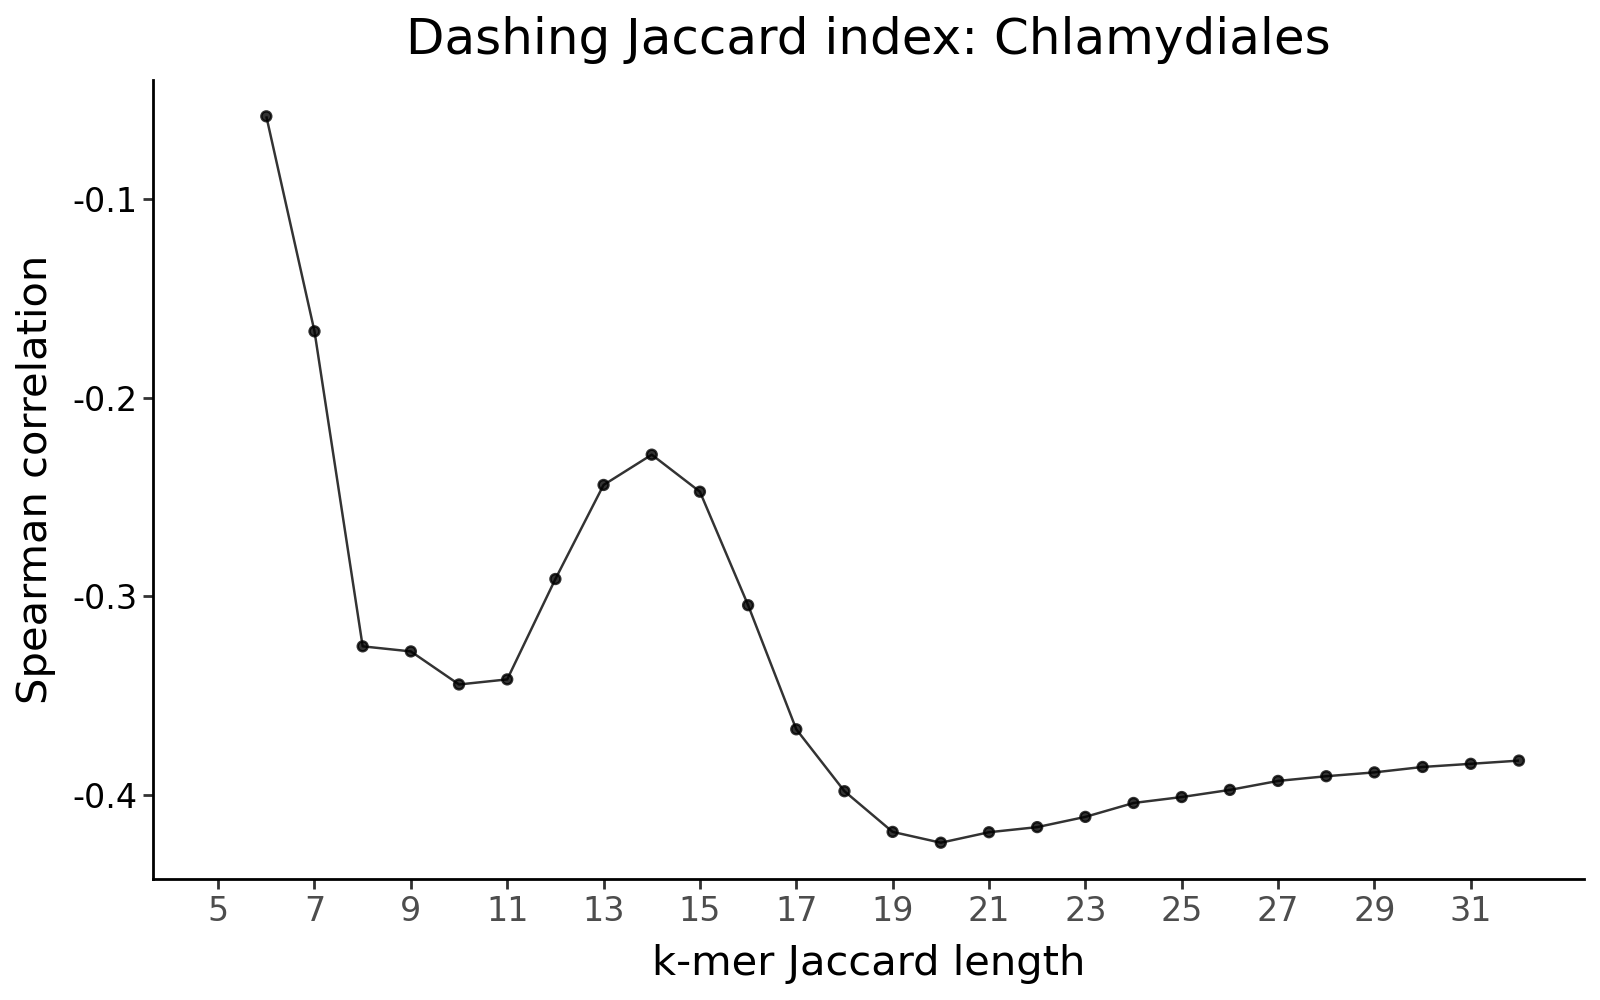

In [ ]:
chlam_corr_df

(
    ggplot(chlam_corr_df) +
    geom_point(aes(x='k', y='spearman_corr'), alpha=0.8) +
    geom_line(aes(x='k', y='spearman_corr'), alpha=0.8) +
    # ggtitle("Dashing Jaccard index: Cyanobacteriales (n=585)") +
    ggtitle("Dashing Jaccard index: Chlamydiales") +
    xlab("k-mer Jaccard length") +
    ylab("Spearman correlation") +
    theme_tufte_func(base_size=15, rotate=False, figure_size=(8, 5)) +
    scale_x_continuous(breaks=range(5,33,2))
    # scale_x_continuous(breaks=range(5,33,2)) +
    # scale_color_manual(values=['#000000', '#D7263D'],  # Black, Royal blue, Green
                    #   breaks=['Single k', 'k and 20-mer'])  # Specify legend order
)

In [ ]:
# Filter for just the distance_k files and sort them by k value
distance_files = sorted([f for f in dashing_dfs.keys() if f.startswith('distance_k')],
                       key=lambda x: int(x.replace('distance_k', '').replace('.txt', '')))

# Create list of pairs and their distances
pairs = []
k_values = {}

# Process first file to get genome names and create pairs
first_df = dashing_dfs[distance_files[0]]
genomes = first_df.iloc[0, 1:].tolist()  # Get genome names from first row

# Clean genome names by removing 'genomes_ncbi/'
genomes = [g.replace('genomes_ncbi/', '') for g in genomes]

# Create all pairs of genomes (upper triangle only)
for i in range(len(genomes)):
    for j in range(i+1, len(genomes)):
        # Sort lexicographically and join with '_'
        pair = '_'.join(sorted([genomes[i], genomes[j]]))
        pairs.append(pair)

# Initialize dataframe with pairs as index
merged_df = pd.DataFrame(index=pairs)

# Add data from each distance file
for file in distance_files:
    k = int(file.replace('distance_k', '').replace('.txt', ''))
    df = dashing_dfs[file]

    # Extract distances for each pair
    distances = []
    for i in range(len(genomes)):
        for j in range(i+1, len(genomes)):
            distances.append(df.iloc[i+1, j+1])

    # Add as new column
    merged_df[f'k_{k}'] = distances

# Clean up the index name
merged_df.index.name = 'genome_pair'


# Add metadat columns to merged_df
genome_pairs = []
genomes_1s = []
genomes_2s = []
tree_distances = []

for index in merged_df.index:
    # Split the genome pair
    genome1 = "_".join(index.split("_", 2)[:2])
    genome2 = "_".join(index.split("_", 2)[2:])

    # Get distance from tree_dict
    distance = tree_dict[genome1][genome2]

    genome_pairs.append(index)
    genomes_1s.append(genome1)
    genomes_2s.append(genome2)
    tree_distances.append(distance)

# Add tree_distance column to merged_df
merged_df['genome_pair'] = genome_pairs
merged_df['genome_1'] = genomes_1s
merged_df['genome_2'] = genomes_2s
merged_df['tree_distance'] = tree_distances

print(f"Final dataframe shape: {merged_df.shape}")
merged_df


In [ ]:

# spearman rank for k to true distance for all pairs

def spearman_corr_against_tree(dfs_dict, tree_dict):
    rows = []
    for fname, df in dfs_dict.items():
        # Derive k from filename when possible
        try:
            k_val = int(str(fname).replace('distance_k', '').replace('.txt', ''))
        except Exception:
            k_val = fname

        names = list(df.index)
        x_dashing = []
        y_tree = []

        for i in range(len(names)):
            for j in range(i + 1, len(names)):
                raw1, raw2 = names[i], names[j]
                g1 = raw1.replace('genomes_ncbi/', '').rstrip('.fa')
                g2 = raw2.replace('genomes_ncbi/', '').rstrip('.fa')

                # Fetch tree distance (symmetric)
                td = None
                if g1 in tree_dict and g2 in tree_dict[g1]:
                    td = tree_dict[g1][g2]
                elif g2 in tree_dict and g1 in tree_dict[g2]:
                    td = tree_dict[g2][g1]
                else:
                    continue  # skip pairs not present in the tree dict

                try:
                    dashing_dist = float(df.loc[raw1, raw2])
                except Exception:
                    # If labels aren't perfectly aligned, try the symmetric access
                    try:
                        dashing_dist = float(df.loc[raw2, raw1])
                    except Exception:
                        continue

                x_dashing.append(dashing_dist)
                y_tree.append(float(td))

        if len(x_dashing) >= 2:
            corr, pval = spearmanr(x_dashing, y_tree)
        else:
            corr, pval = np.nan, np.nan

        rows.append({
            'k': k_val,
            'spearman_corr': corr,
            'p_value': pval,
            'n_pairs': len(x_dashing)
        })

    return pd.DataFrame(rows)